## Cell 1 — Environment setup, reproducibility, and experiment configuration

This cell initializes the Python environment, fixes random seeds, prepares the output folders, and defines the central experiment configuration. The configuration holds the time horizon, the evaluation, calibration, sweep, and scalability seeds, the hybrid-security parameters, the risk and stress-energy weights, the free-energy temperature, the energy model, and the failure definition used for prediction. Configuration and run metadata are saved so that every figure and table can be traced to its parameter settings.

In [1]:
import os
import sys
import json
import math
import time
import random
import platform
import warnings
from pathlib import Path
from datetime import datetime, timezone
from itertools import islice
from copy import deepcopy

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.optimize import milp, LinearConstraint, Bounds

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# -----------------------------
# Runtime environment
# -----------------------------
try:
    from google.colab import drive
    IN_COLAB = True
except Exception:
    IN_COLAB = False

PROJECT_NAME = "quantum_secure_comm"

if IN_COLAB:
    drive.mount("/content/drive", force_remount=True)
    ROOT_DIR = Path(f"/content/drive/MyDrive/Outputs/{PROJECT_NAME}")
else:
    ROOT_DIR = Path("./Outputs") / PROJECT_NAME

FIG_DIR = ROOT_DIR / "figures"
TAB_DIR = ROOT_DIR / "tables"
OTH_DIR = ROOT_DIR / "others"

for d in [ROOT_DIR, FIG_DIR, TAB_DIR, OTH_DIR]:
    d.mkdir(parents=True, exist_ok=True)

OUTPUTS_SUMMARY_PATH = ROOT_DIR / "outputs_summary.txt"
RUN_METADATA_PATH = OTH_DIR / "run_metadata.json"
CONFIG_PATH = OTH_DIR / "experiment_config.json"

# -----------------------------
# Plot settings
# -----------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.titlesize": 9,
    "axes.linewidth": 0.6,
    "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.5,
    "legend.frameon": False,
    "lines.linewidth": 1.2,
    "lines.markersize": 3,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

FULL_W = 5.95
SINGLE_W = 4.17
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK = "#0b0b0b"
INK2 = "#52514e"
REGIME_COLORS = {"secure": "#1baf7a", "transition": "#eda100", "sparse": "#e34948"}
STATUS_COLORS = {
    "secure_allocated": "#1baf7a",
    "best_effort_allocated": "#eda100",
    "degraded_unallocated": "#eb6834",
    "blocked": "#e34948",
}
STATUS_LABELS = {
    "secure_allocated": "Secure",
    "best_effort_allocated": "Best effort",
    "degraded_unallocated": "Degraded",
    "blocked": "Blocked",
}

def panel_label(ax, letter, x=-0.16, y=1.03):
    ax.text(x, y, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    fig.savefig(FIG_DIR / f"{name}.pdf")
    plt.show()

# -----------------------------
# Central experiment configuration
# -----------------------------
CONFIG = {
    "project_name": PROJECT_NAME,
    "seed": SEED,
    "time_horizon": 48,
    "environment_period": 24,
    "max_candidate_paths_per_flow": 8,
    "max_path_hops": 6,
    "raw_path_pool": 64,
    "reference_seed": SEED,
    "reference_scenario": "satellite_channel_stress",
    "evaluation_seeds": list(range(1, 31)),
    "calibration_seeds": list(range(101, 116)),
    "sweep_seeds": list(range(1, 21)),
    "sensitivity_seeds": list(range(1, 13)),
    "scalability_seeds": list(range(1, 11)),
    "security": {
        "combiner": "kdf",
        "alpha_linear": 0.55,
        "sigma_qkd": 0.95,
        "sigma_pqc": 0.60,
        "beta_trust": 0.50,
        "autonomy_slots": 4.0,
        "qber_threshold": 0.11,
        "ec_efficiency": 1.16,
        "pqc_overhead": 0.12,
    },
    "risk_weights": {
        "reliability": 0.35,
        "trust": 0.40,
        "qber": 0.25,
    },
    "stress_weights": {
        "lambda_H": 0.30,
        "lambda_R": 0.40,
        "lambda_L": 0.20,
        "lambda_E": 0.15,
        "lambda_K": 0.30,
    },
    "temperature": 0.10,
    "infeasibility_penalty": 1.0,
    "latency_ref_ms": 150.0,
    "energy_ref": 12.0,
    "allocation": {
        "secure_bonus": 10.0,
        "service_bonus": 5.0,
    },
    "energy": {
        "pqc_handshake_per_hop": 0.02,
        "pqc_symmetric_per_unit": 0.005,
        "qkd_time_cap_slots": 4.0,
    },
    "key_buffer": {
        "initial_fill": 0.8,
    },
    "prediction": {
        "failure_level": 0.75,
        "horizons": [1, 2, 3, 4, 5],
        "secure_probability": 0.10,
        "sparse_probability": 0.50,
        "max_lead_window": 5,
    },
    "notes": (
        "Network-level hybrid QKD-PQC STIN simulation with BB84-type secret-key rates, "
        "per-link key buffers, KDF-based hybrid key combination, and free-energy path stress. "
        "Physical-layer QKD is represented by surrogate channel models rather than full protocol simulation."
    )
}

# Persist config for reproducibility
with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

run_metadata = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "networkx_version": nx.__version__,
    "matplotlib_version": plt.matplotlib.__version__,
    "scipy_version": scipy.__version__,
    "in_colab": IN_COLAB,
    "root_dir": ROOT_DIR.as_posix(),
    "config_path": CONFIG_PATH.as_posix(),
}
with open(RUN_METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(run_metadata, f, indent=2)

NOTEBOOK_START = time.time()

print(f"[INFO] Root output directory: {ROOT_DIR.as_posix()}")
print(f"[INFO] Figures directory: {FIG_DIR.as_posix()}")
print(f"[INFO] Tables directory: {TAB_DIR.as_posix()}")
print(f"[INFO] Metadata saved: {RUN_METADATA_PATH.as_posix()}")
print(f"[INFO] Config saved: {CONFIG_PATH.as_posix()}")

[INFO] Root output directory: Outputs/quantum_secure_comm
[INFO] Figures directory: Outputs/quantum_secure_comm/figures
[INFO] Tables directory: Outputs/quantum_secure_comm/tables
[INFO] Metadata saved: Outputs/quantum_secure_comm/others/run_metadata.json
[INFO] Config saved: Outputs/quantum_secure_comm/others/experiment_config.json


## Cell 2 — Unified theoretical quantities, free-energy formulation, and indicators

This cell defines the quantities used throughout the notebook. QKD secret-key generation follows the asymptotic BB84 secret fraction 1 - f h(e) - h(e), which vanishes above the QBER threshold. The QKD assurance of a trusted-relay path, Q_p, is derived from the key-buffer autonomy of its bottleneck hop. The QKD and PQC session keys are combined through a key-derivation function, so the hybrid key is secure if either component holds: S = 1 - (1 - Q_p)(1 - C). A linear combiner is kept for comparison. Each candidate path receives a stress energy E_p = (1 - S_p) + lambda_H H_p + lambda_R R_p + lambda_L L_p + lambda_E E_p + lambda_K Pi_p, where H_p is the normalized binary entropy of the QBER on QKD-protected hops (range [0, 1]); every uncertainty term increases E_p. The flow-level free energy F_f = min_pi { <E>_pi - T H(pi) } = -T log sum_p exp(-E_p / T) is minimized by the Gibbs policy over candidate paths. The Security Criticality Index is SCI(t) = R(t) - D(t), where the reserve R(t) aggregates positive margins and the deficit D(t) keeps the severity of negative margins. The cell also includes the statistics helpers used later (confidence intervals, logistic regression, ROC-AUC, average precision).

In [2]:
# -----------------------------
# Role and layer definitions
# -----------------------------
def node_role(name: str) -> str:
    if name.startswith("SAT"):
        return "satellite"
    if name.startswith("UAV"):
        return "uav"
    if name.startswith("GW"):
        return "gateway"
    if name.startswith("BS"):
        return "base_station"
    if name.startswith("DC"):
        return "data_center"
    return "unknown"

def node_layer(name: str) -> str:
    role = node_role(name)
    if role == "satellite":
        return "space"
    if role == "uav":
        return "air"
    return "ground"

def edge_role_class(u: str, v: str) -> str:
    ru, rv = node_role(u), node_role(v)
    roles = {ru, rv}

    if roles == {"satellite"}:
        return "inter_satellite"
    if "satellite" in roles and "gateway" in roles:
        return "satellite_gateway"
    if "satellite" in roles and "uav" in roles:
        return "satellite_aerial"
    if "uav" in roles and "gateway" in roles:
        return "aerial_gateway"
    if "uav" in roles and "base_station" in roles:
        return "aerial_access"
    if "gateway" in roles and "base_station" in roles:
        return "gateway_backhaul"
    if roles == {"base_station"}:
        return "terrestrial_backhaul"
    if "base_station" in roles and "data_center" in roles:
        return "metro_core"
    if "gateway" in roles and "data_center" in roles:
        return "gateway_core"
    return "heterogeneous_ground"

SPACE_AIR_CLASSES = {
    "inter_satellite",
    "satellite_gateway",
    "satellite_aerial",
    "aerial_gateway",
    "aerial_access",
}

# -----------------------------
# Numeric helpers
# -----------------------------
def clip01(x: float) -> float:
    x = float(x)
    return 0.0 if x < 0.0 else (1.0 if x > 1.0 else x)

def safe_mean(values) -> float:
    values = list(values)
    return float(np.mean(values)) if values else 0.0

def binary_entropy(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-12, 1.0 - 1e-12)
    return -(p * np.log2(p) + (1.0 - p) * np.log2(1.0 - p))

def logsumexp(x):
    x = np.asarray(x, dtype=float)
    m = np.max(x)
    return float(m + np.log(np.sum(np.exp(x - m))))

# -----------------------------
# QKD secret-key generation
# -----------------------------
def bb84_secret_fraction(qber, P=None):
    """Asymptotic BB84 secret fraction 1 - f*h(e) - h(e), zero above the QBER threshold."""
    P = CONFIG if P is None else P
    sec = P["security"]
    q = np.asarray(qber, dtype=float)
    h = binary_entropy(q)
    r = 1.0 - sec["ec_efficiency"] * h - h
    r = np.where(q >= sec["qber_threshold"], 0.0, r)
    return np.maximum(r, 0.0)

def qkd_key_rate(transmissivity, qber, source_rate, P=None):
    """Secret-key generation per slot: source rate x channel transmissivity x secret fraction."""
    eta = np.clip(np.asarray(transmissivity, dtype=float), 0.0, 1.0)
    return np.asarray(source_rate, dtype=float) * eta * bb84_secret_fraction(qber, P)

# -----------------------------
# Hybrid QKD-PQC security
# -----------------------------
def qkd_path_assurance(min_available_key: float, key_demand: float, P=None) -> float:
    """
    Q_p: end-to-end QKD assurance of a trusted-relay path.
    Every hop must hold at least one slot of key; assurance grows with the key-buffer
    autonomy of the bottleneck hop, A_min / (k_f * h_K), and saturates at sigma_QKD.
    """
    P = CONFIG if P is None else P
    sec = P["security"]
    if min_available_key < key_demand:
        return 0.0
    autonomy = min_available_key / max(key_demand * sec["autonomy_slots"], 1e-12)
    return float(sec["sigma_qkd"] * min(1.0, autonomy))

def hybrid_security_level(Q: float, P=None, combiner=None) -> float:
    """
    kdf    : K = KDF(K_QKD || K_PQC); the session key is secure if either component holds,
             S = 1 - (1 - Q)(1 - C)
    linear : S = alpha Q + (1 - alpha) C
    """
    P = CONFIG if P is None else P
    sec = P["security"]
    combiner = sec["combiner"] if combiner is None else combiner
    C = sec["sigma_pqc"]
    if combiner == "linear":
        a = sec["alpha_linear"]
        return float(a * Q + (1.0 - a) * C)
    return float(1.0 - (1.0 - Q) * (1.0 - C))

def path_security_level(Q: float, trust_min: float, P=None, combiner=None, beta_trust=None) -> float:
    """S_p = S_hybrid(Q_p, C) * (1 - beta_tau (1 - tau_min)), tau_min = least trusted relay on the path."""
    P = CONFIG if P is None else P
    beta = P["security"]["beta_trust"] if beta_trust is None else beta_trust
    return clip01(hybrid_security_level(Q, P, combiner) * (1.0 - beta * (1.0 - clip01(trust_min))))

def security_margin_value(security_level: float, security_req: float) -> float:
    return float(security_level - security_req)

def channel_entropy(qber_protected, P=None, h_values=None) -> float:
    """H_p in [0, 1]: largest binary entropy of QBER on QKD-protected hops, normalized by h(e_th)."""
    P = CONFIG if P is None else P
    if len(qber_protected) == 0:
        return 0.0
    h = binary_entropy(qber_protected) if h_values is None else h_values
    h_max = float(binary_entropy(P["security"]["qber_threshold"]))
    return clip01(float(np.max(h)) / h_max)

# -----------------------------
# Path-level operators
# -----------------------------
def path_risk(reliability: float, trust_min: float, qber_max: float, P=None, weights=None) -> float:
    """R_p = b1 (1 - r_p) + b2 (1 - tau_p) + b3 min(1, e_p / e_th), weights summing to one."""
    P = CONFIG if P is None else P
    w = P["risk_weights"] if weights is None else weights
    e_th = P["security"]["qber_threshold"]
    return clip01(
        w["reliability"] * (1.0 - clip01(reliability)) +
        w["trust"] * (1.0 - clip01(trust_min)) +
        w["qber"] * min(1.0, qber_max / e_th)
    )

def normalized_latency(latency_ms: float, P=None) -> float:
    P = CONFIG if P is None else P
    return clip01(latency_ms / P["latency_ref_ms"])

def path_energy(traffic_demand, key_demand, tx_coeff, qkd_power, key_rate, use_qkd, P=None) -> float:
    """
    Energy per slot of serving a flow on a path:
    transmission + QKD generation time x QKD power (when QKD is used) + PQC handshake and symmetric encryption.
    """
    P = CONFIG if P is None else P
    en = P["energy"]
    tx_coeff = np.asarray(tx_coeff, dtype=float)
    e_tx = traffic_demand * float(np.sum(tx_coeff))
    e_qkd = 0.0
    if use_qkd:
        gen_time = np.minimum(key_demand / np.maximum(np.asarray(key_rate, dtype=float), 1e-9), en["qkd_time_cap_slots"])
        e_qkd = float(np.sum(np.asarray(qkd_power, dtype=float) * gen_time))
    e_pqc = len(tx_coeff) * en["pqc_handshake_per_hop"] + traffic_demand * en["pqc_symmetric_per_unit"]
    return float(e_tx + e_qkd + e_pqc)

# -----------------------------
# Free-energy formulation
# -----------------------------
def stress_energy(S, H, R, L_hat, E_hat, Pi, P=None, weights=None) -> float:
    """E_p = (1 - S_p) + lH H_p + lR R_p + lL L_p + lE E_p + lK Pi_p (lower is better)."""
    P = CONFIG if P is None else P
    w = P["stress_weights"] if weights is None else weights
    return float(
        (1.0 - S) +
        w["lambda_H"] * H +
        w["lambda_R"] * R +
        w["lambda_L"] * L_hat +
        w["lambda_E"] * E_hat +
        w["lambda_K"] * Pi
    )

def gibbs_policy(energies, temperature: float):
    """Minimizer of <E>_pi - T H(pi) over the simplex."""
    e = np.asarray(energies, dtype=float)
    z = -e / max(temperature, 1e-9)
    z = z - np.max(z)
    w = np.exp(z)
    return w / np.sum(w)

def flow_free_energy(energies, temperature: float):
    """
    F_f = min_pi { <E>_pi - T H(pi) } = -T log sum_p exp(-E_p / T).
    Returns F_f and the effective number of alternatives exp(H(pi*)).
    """
    e = np.asarray(energies, dtype=float)
    T_ = max(temperature, 1e-9)
    F = -T_ * logsumexp(-e / T_)
    pi = gibbs_policy(e, T_)
    H = -float(np.sum(pi * np.log(np.clip(pi, 1e-300, 1.0))))
    return float(F), float(np.exp(H))

# -----------------------------
# Security Criticality Index (SCI)
# -----------------------------
def criticality_components(effective_margins, security_reqs, weights):
    """
    Reserve R(t) = sum w max(M,0) / sum w S_req
    Deficit D(t) = sum w max(-M,0) / sum w S_req   (in [0, 1])
    SCI(t)       = R(t) - D(t)
    """
    m = np.asarray(effective_margins, dtype=float)
    s = np.asarray(security_reqs, dtype=float)
    w = np.asarray(weights, dtype=float)
    denom = max(float(np.sum(w * s)), 1e-12)
    reserve = float(np.sum(w * np.maximum(m, 0.0)) / denom)
    deficit = float(np.sum(w * np.maximum(-m, 0.0)) / denom)
    return reserve, deficit, reserve - deficit

REGIME_THRESHOLDS = {"secure": 0.0, "sparse": -0.25}

def classify_security_regime(sci: float, thresholds=None) -> str:
    th = REGIME_THRESHOLDS if thresholds is None else thresholds
    if sci >= th["secure"]:
        return "secure"
    if sci >= th["sparse"]:
        return "transition"
    return "sparse"

# -----------------------------
# Statistics helpers
# -----------------------------
def mean_ci(values, confidence: float = 0.95):
    x = np.asarray(pd.Series(values).dropna(), dtype=float)
    n = len(x)
    if n == 0:
        return np.nan, np.nan, np.nan
    m = float(np.mean(x))
    if n < 2:
        return m, m, m
    half = float(stats.t.ppf(0.5 + confidence / 2.0, n - 1) * np.std(x, ddof=1) / np.sqrt(n))
    return m, m - half, m + half

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))

def fit_logistic(X, y, l2: float = 1e-3, iters: int = 100):
    """Newton-Raphson logistic regression on standardized features."""
    X = np.atleast_2d(np.asarray(X, dtype=float))
    if X.shape[0] != len(y):
        X = X.T
    y = np.asarray(y, dtype=float)
    mu = X.mean(axis=0)
    sd = X.std(axis=0)
    sd[sd < 1e-12] = 1.0
    Z = np.column_stack([np.ones(len(X)), (X - mu) / sd])
    w = np.zeros(Z.shape[1])
    reg = l2 * np.eye(Z.shape[1])
    reg[0, 0] = 0.0
    for _ in range(iters):
        p = sigmoid(Z @ w)
        g = Z.T @ (y - p) - reg @ w
        Hs = -(Z.T * (p * (1.0 - p))) @ Z - reg
        step = np.linalg.solve(Hs, g)
        w = w - step
        if np.max(np.abs(step)) < 1e-8:
            break
    return {"w": w, "mu": mu, "sd": sd}

def predict_logistic(model, X):
    X = np.atleast_2d(np.asarray(X, dtype=float))
    if X.shape[1] != len(model["mu"]):
        X = X.T
    Z = np.column_stack([np.ones(len(X)), (X - model["mu"]) / model["sd"]])
    return sigmoid(Z @ model["w"])

def roc_auc(scores, labels) -> float:
    s = np.asarray(scores, dtype=float)
    y = np.asarray(labels, dtype=bool)
    n_pos, n_neg = int(y.sum()), int((~y).sum())
    if n_pos == 0 or n_neg == 0:
        return np.nan
    ranks = stats.rankdata(s)
    return float((ranks[y].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))

def roc_curve_points(scores, labels):
    s = np.asarray(scores, dtype=float)
    y = np.asarray(labels, dtype=bool)
    thr = np.unique(s)[::-1]
    tpr = [0.0]
    fpr = [0.0]
    for th in thr:
        pred = s >= th
        tpr.append(float((pred & y).sum() / max(y.sum(), 1)))
        fpr.append(float((pred & ~y).sum() / max((~y).sum(), 1)))
    return np.array(fpr), np.array(tpr)

def average_precision(scores, labels) -> float:
    s = np.asarray(scores, dtype=float)
    y = np.asarray(labels, dtype=bool)
    if y.sum() == 0:
        return np.nan
    order = np.argsort(-s, kind="mergesort")
    y_sorted = y[order]
    tp = np.cumsum(y_sorted)
    precision = tp / np.arange(1, len(y_sorted) + 1)
    return float(np.sum(precision[y_sorted]) / y.sum())

print("[INFO] Unified security, free-energy, and indicator utilities are ready.")

[INFO] Unified security, free-energy, and indicator utilities are ready.


## Cell 3 — Multi-layer STIN topologies with role-aware links

This cell builds the reference role-aware STIN, which has 10 nodes and 18 edges and connects satellite, UAV, gateway, base-station, and data-center roles. It also provides a layered generator for larger topologies used in the scalability study. Each link class has surrogate ranges for transmissivity, noise, QBER, latency, capacity, and trust, together with QKD source rate, key-buffer capacity, transmission energy, and QKD power. Free-space links and the fiber gateway/metro backbone are QKD-capable, while base-station mesh links are PQC-only.

In [3]:
# -----------------------------
# Link-class parameter library
# Architecture-level surrogate ranges
# -----------------------------
LINK_CLASS_PARAMS = {
    "inter_satellite": {
        "distance_km": (900, 1400),
        "transmissivity": (0.20, 0.38),
        "noise": (0.010, 0.030),
        "qber": (0.010, 0.040),
        "latency_ms": (12, 22),
        "capacity": (8, 16),
        "trust": (0.82, 0.94),
        "supports_qkd": True,
        "qkd_source_rate": 14.0,
        "buffer_capacity": 10.0,
        "tx_energy": 0.80,
        "qkd_power": 2.0,
    },
    "satellite_gateway": {
        "distance_km": (700, 1200),
        "transmissivity": (0.14, 0.32),
        "noise": (0.020, 0.060),
        "qber": (0.020, 0.065),
        "latency_ms": (20, 40),
        "capacity": (6, 14),
        "trust": (0.72, 0.88),
        "supports_qkd": True,
        "qkd_source_rate": 12.0,
        "buffer_capacity": 10.0,
        "tx_energy": 1.00,
        "qkd_power": 2.0,
    },
    "satellite_aerial": {
        "distance_km": (500, 950),
        "transmissivity": (0.16, 0.36),
        "noise": (0.018, 0.055),
        "qber": (0.018, 0.060),
        "latency_ms": (16, 32),
        "capacity": (6, 14),
        "trust": (0.70, 0.86),
        "supports_qkd": True,
        "qkd_source_rate": 12.0,
        "buffer_capacity": 10.0,
        "tx_energy": 0.90,
        "qkd_power": 2.0,
    },
    "aerial_gateway": {
        "distance_km": (120, 260),
        "transmissivity": (0.30, 0.58),
        "noise": (0.010, 0.035),
        "qber": (0.012, 0.045),
        "latency_ms": (7, 15),
        "capacity": (10, 22),
        "trust": (0.76, 0.90),
        "supports_qkd": True,
        "qkd_source_rate": 10.0,
        "buffer_capacity": 10.0,
        "tx_energy": 0.40,
        "qkd_power": 1.2,
    },
    "aerial_access": {
        "distance_km": (80, 180),
        "transmissivity": (0.36, 0.66),
        "noise": (0.008, 0.030),
        "qber": (0.010, 0.040),
        "latency_ms": (5, 12),
        "capacity": (12, 24),
        "trust": (0.78, 0.92),
        "supports_qkd": True,
        "qkd_source_rate": 10.0,
        "buffer_capacity": 10.0,
        "tx_energy": 0.30,
        "qkd_power": 1.2,
    },
    "gateway_backhaul": {
        "distance_km": (25, 90),
        "transmissivity": (0.62, 0.90),
        "noise": (0.004, 0.018),
        "qber": (0.006, 0.020),
        "latency_ms": (2, 8),
        "capacity": (18, 36),
        "trust": (0.84, 0.96),
        "supports_qkd": True,
        "qkd_source_rate": 8.0,
        "buffer_capacity": 20.0,
        "tx_energy": 0.08,
        "qkd_power": 0.6,
    },
    "terrestrial_backhaul": {
        "distance_km": (20, 80),
        "transmissivity": (0.72, 0.95),
        "noise": (0.003, 0.015),
        "qber": (0.005, 0.018),
        "latency_ms": (1, 6),
        "capacity": (20, 40),
        "trust": (0.86, 0.97),
        "supports_qkd": False,
        "qkd_source_rate": 0.0,
        "buffer_capacity": 0.0,
        "tx_energy": 0.06,
        "qkd_power": 0.0,
    },
    "metro_core": {
        "distance_km": (15, 70),
        "transmissivity": (0.78, 0.96),
        "noise": (0.002, 0.012),
        "qber": (0.004, 0.016),
        "latency_ms": (1, 5),
        "capacity": (24, 44),
        "trust": (0.88, 0.98),
        "supports_qkd": True,
        "qkd_source_rate": 8.0,
        "buffer_capacity": 20.0,
        "tx_energy": 0.05,
        "qkd_power": 0.6,
    },
    "gateway_core": {
        "distance_km": (30, 100),
        "transmissivity": (0.68, 0.92),
        "noise": (0.003, 0.015),
        "qber": (0.005, 0.018),
        "latency_ms": (2, 7),
        "capacity": (22, 40),
        "trust": (0.86, 0.97),
        "supports_qkd": True,
        "qkd_source_rate": 8.0,
        "buffer_capacity": 20.0,
        "tx_energy": 0.07,
        "qkd_power": 0.6,
    },
    "heterogeneous_ground": {
        "distance_km": (20, 100),
        "transmissivity": (0.60, 0.88),
        "noise": (0.004, 0.020),
        "qber": (0.006, 0.022),
        "latency_ms": (2, 8),
        "capacity": (16, 32),
        "trust": (0.82, 0.95),
        "supports_qkd": False,
        "qkd_source_rate": 0.0,
        "buffer_capacity": 0.0,
        "tx_energy": 0.08,
        "qkd_power": 0.0,
    },
}

# -----------------------------
# Reference topology (10 nodes, 18 edges)
# -----------------------------
REFERENCE_NODE_POS = {
    "SAT_1": (0.12, 0.92),
    "SAT_2": (0.88, 0.92),
    "UAV_1": (0.24, 0.70),
    "UAV_2": (0.76, 0.70),
    "GW_1":  (0.24, 0.48),
    "GW_2":  (0.76, 0.48),
    "BS_1":  (0.12, 0.20),
    "BS_2":  (0.50, 0.20),
    "BS_3":  (0.88, 0.20),
    "DC_1":  (0.50, 0.04),
}

REFERENCE_EDGES = [
    ("SAT_1", "SAT_2"),
    ("SAT_1", "UAV_1"),
    ("SAT_2", "UAV_2"),
    ("SAT_1", "GW_1"),
    ("SAT_2", "GW_2"),
    ("UAV_1", "GW_1"),
    ("UAV_2", "GW_2"),
    ("UAV_1", "BS_2"),
    ("UAV_2", "BS_2"),
    ("GW_1", "BS_1"),
    ("GW_1", "BS_2"),
    ("GW_2", "BS_2"),
    ("GW_2", "BS_3"),
    ("BS_1", "BS_2"),
    ("BS_2", "BS_3"),
    ("BS_1", "DC_1"),
    ("BS_2", "DC_1"),
    ("BS_3", "DC_1"),
]

def build_reference_topology():
    G = nx.Graph()
    G.add_nodes_from(REFERENCE_NODE_POS.keys())
    G.add_edges_from(REFERENCE_EDGES)
    for n in G.nodes():
        G.nodes[n]["role"] = node_role(n)
        G.nodes[n]["layer"] = node_layer(n)
        G.nodes[n]["pos"] = REFERENCE_NODE_POS[n]
    return G

# -----------------------------
# Scalable layered topology generator
# -----------------------------
TOPOLOGY_SIZES = {
    "reference": None,
    "medium": {"n_sat": 4, "n_uav": 4, "n_gw": 4, "n_bs": 8, "n_dc": 2, "n_flows": 12},
    "large": {"n_sat": 8, "n_uav": 8, "n_gw": 8, "n_bs": 16, "n_dc": 4, "n_flows": 24},
}

def build_generated_topology(n_sat, n_uav, n_gw, n_bs, n_dc, seed):
    rng = np.random.default_rng([seed, 11])
    G = nx.Graph()

    def layer_positions(prefix, n, y):
        xs = np.sort(np.clip(np.linspace(0.06, 0.94, n) + rng.normal(0, 0.02, n), 0.02, 0.98))
        return {f"{prefix}_{i + 1}": (float(x), y) for i, x in enumerate(xs)}

    pos = {}
    pos.update(layer_positions("SAT", n_sat, 0.92))
    pos.update(layer_positions("UAV", n_uav, 0.70))
    pos.update(layer_positions("GW", n_gw, 0.48))
    pos.update(layer_positions("BS", n_bs, 0.20))
    pos.update(layer_positions("DC", n_dc, 0.04))

    for n, p in pos.items():
        G.add_node(n, role=node_role(n), layer=node_layer(n), pos=p)

    def nodes_of(prefix):
        return [n for n in pos if n.startswith(prefix + "_")]

    def nearest(src, prefix, k):
        cands = nodes_of(prefix)
        cands = sorted(cands, key=lambda n: abs(pos[n][0] - pos[src][0]))
        return [c for c in cands if c != src][:k]

    sats, uavs, gws, bss, dcs = (nodes_of(p) for p in ["SAT", "UAV", "GW", "BS", "DC"])

    for i in range(len(sats) - 1):
        G.add_edge(sats[i], sats[i + 1])
    for s in sats:
        for g in nearest(s, "GW", 2):
            G.add_edge(s, g)
        for u in nearest(s, "UAV", 1):
            G.add_edge(s, u)
    for u in uavs:
        for g in nearest(u, "GW", 1):
            G.add_edge(u, g)
        for b in nearest(u, "BS", 2):
            G.add_edge(u, b)
    for g in gws:
        for b in nearest(g, "BS", 2):
            G.add_edge(g, b)
        for d in nearest(g, "DC", 1):
            G.add_edge(g, d)
    for i in range(len(bss) - 1):
        G.add_edge(bss[i], bss[i + 1])
    for b in bss:
        for d in nearest(b, "DC", 1):
            G.add_edge(b, d)

    if not nx.is_connected(G):
        comps = list(nx.connected_components(G))
        for c in comps[1:]:
            G.add_edge(next(iter(comps[0])), next(iter(c)))
    return G

# -----------------------------
# Edge attribute assignment
# -----------------------------
def sample_from_range(rng, bounds):
    return float(rng.uniform(bounds[0], bounds[1]))

def assign_link_attributes(G, seed):
    rng = np.random.default_rng([seed, 3])
    for u, v in sorted(G.edges()):
        link_class = edge_role_class(u, v)
        params = LINK_CLASS_PARAMS[link_class]
        G[u][v]["link_class"] = link_class
        G[u][v]["distance_km"] = sample_from_range(rng, params["distance_km"])
        G[u][v]["base_transmissivity"] = sample_from_range(rng, params["transmissivity"])
        G[u][v]["base_noise"] = sample_from_range(rng, params["noise"])
        G[u][v]["base_qber"] = sample_from_range(rng, params["qber"])
        G[u][v]["latency_ms"] = sample_from_range(rng, params["latency_ms"])
        G[u][v]["link_capacity"] = sample_from_range(rng, params["capacity"])
        G[u][v]["trust_score"] = sample_from_range(rng, params["trust"])
        G[u][v]["supports_qkd"] = bool(params["supports_qkd"])
        G[u][v]["supports_pqc"] = True
        G[u][v]["qkd_source_rate"] = params["qkd_source_rate"]
        G[u][v]["buffer_capacity"] = params["buffer_capacity"]
        G[u][v]["tx_energy"] = params["tx_energy"]
        G[u][v]["qkd_power"] = params["qkd_power"]
    return G

def build_topology(kind: str, seed: int):
    if kind == "reference":
        G = build_reference_topology()
    else:
        spec = TOPOLOGY_SIZES[kind]
        G = build_generated_topology(spec["n_sat"], spec["n_uav"], spec["n_gw"], spec["n_bs"], spec["n_dc"], seed)
    return assign_link_attributes(G, seed)

G = build_topology("reference", CONFIG["reference_seed"])
print(f"[INFO] Reference topology -> nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")
for kind in ["medium", "large"]:
    G_tmp = build_topology(kind, CONFIG["reference_seed"])
    print(f"[INFO] {kind} topology -> nodes: {G_tmp.number_of_nodes()}, edges: {G_tmp.number_of_edges()}")

node_preview = pd.DataFrame([
    {
        "node": n,
        "role": G.nodes[n]["role"],
        "layer": G.nodes[n]["layer"],
        "pos_x": G.nodes[n]["pos"][0],
        "pos_y": G.nodes[n]["pos"][1],
    }
    for n in G.nodes()
])

edge_preview = pd.DataFrame([
    {
        "u": u,
        "v": v,
        "link_class": G[u][v]["link_class"],
        "distance_km": G[u][v]["distance_km"],
        "base_transmissivity": G[u][v]["base_transmissivity"],
        "base_noise": G[u][v]["base_noise"],
        "base_qber": G[u][v]["base_qber"],
        "latency_ms": G[u][v]["latency_ms"],
        "link_capacity": G[u][v]["link_capacity"],
        "trust_score": G[u][v]["trust_score"],
        "supports_qkd": G[u][v]["supports_qkd"],
        "buffer_capacity": G[u][v]["buffer_capacity"],
    }
    for u, v in G.edges()
])
edge_preview.to_csv(TAB_DIR / "reference_topology_edges.csv", index=False)

link_class_table = pd.DataFrame([
    {"link_class": k, **{kk: (f"{vv[0]}-{vv[1]}" if isinstance(vv, tuple) else vv) for kk, vv in v.items()}}
    for k, v in LINK_CLASS_PARAMS.items()
])
link_class_table.to_csv(TAB_DIR / "link_class_parameters.csv", index=False)

display(node_preview)
display(edge_preview.head(10))

[INFO] Reference topology -> nodes: 10, edges: 18
[INFO] medium topology -> nodes: 22, edges: 54
[INFO] large topology -> nodes: 44, edges: 110


,node,role,layer,pos_x,pos_y
0,SAT_1,satellite,space,0.12,0.92
1,SAT_2,satellite,space,0.88,0.92
2,UAV_1,uav,air,0.24,0.70
3,UAV_2,uav,air,0.76,0.70
4,GW_1,gateway,ground,0.24,0.48
5,GW_2,gateway,ground,0.76,0.48
6,BS_1,base_station,ground,0.12,0.20
7,BS_2,base_station,ground,0.50,0.20
8,BS_3,base_station,ground,0.88,0.20
9,DC_1,data_center,ground,0.50,0.04


,u,v,link_class,distance_km,base_transmissivity,base_noise,base_qber,latency_ms,link_capacity,trust_score,supports_qkd,buffer_capacity
0,SAT_1,SAT_2,inter_satellite,1114.805546,0.331302,0.018145,0.033282,15.524734,13.681240,0.823522,True,10.0
1,SAT_1,UAV_1,satellite_aerial,537.124877,0.350580,0.040377,0.043872,16.729156,13.272551,0.809398,True,10.0
2,SAT_1,GW_1,satellite_gateway,1046.234135,0.212906,0.038887,0.025768,34.448484,6.498738,0.865970,True,10.0
3,SAT_2,UAV_2,satellite_aerial,752.326112,0.270955,0.025890,0.049618,24.344485,6.011166,0.769166,True,10.0
4,SAT_2,GW_2,satellite_gateway,1109.215735,0.318098,0.029844,0.047885,28.225185,11.794854,0.863095,True,10.0
5,UAV_1,GW_1,aerial_gateway,134.765477,0.309378,0.019115,0.017197,8.282746,15.920859,0.866002,True,10.0
6,UAV_1,BS_2,aerial_access,100.165764,0.559138,0.017011,0.024441,11.455781,15.747142,0.914453,True,10.0
7,UAV_2,GW_2,aerial_gateway,127.888322,0.314295,0.023930,0.044277,13.340024,13.522017,0.868403,True,10.0
8,UAV_2,BS_2,aerial_access,113.118196,0.492049,0.012205,0.035663,5.194167,22.590676,0.838083,True,10.0
9,GW_1,BS_1,gateway_backhaul,29.936740,0.840197,0.006852,0.016221,7.078946,27.493826,0.841591,True,20.0


## Cell 4 — Operating scenarios and dynamic link-state simulation

This cell defines the operating scenarios and generates time-varying link states. Each link evolves with its own temporal phase and volatility, driven by shared weather, congestion, and adversarial-pressure processes. The simulation produces availability, transmissivity, excess noise, QBER, classical capacity, latency, trust, and the per-slot secret-key generation of QKD-capable links. All random draws are made in a fixed order, so different scenarios of the same seed share common random numbers and can be compared pairwise.

In [4]:
# -----------------------------
# Operating scenarios
# -----------------------------
BASE_SCENARIO = {
    "qkd_space_factor": 1.00,
    "qkd_ground_factor": 1.00,
    "capacity_space_factor": 1.00,
    "capacity_ground_factor": 1.00,
    "latency_space_factor": 1.00,
    "latency_ground_factor": 1.00,
    "trust_shift": 0.00,
    "noise_factor": 1.00,
    "qber_factor": 1.00,
    "availability_factor": 1.00,
    "traffic_demand_factor": 1.00,
    "key_demand_factor": 1.00,
}

def make_scenario(**overrides):
    sc = dict(BASE_SCENARIO)
    for k, v in overrides.items():
        if k not in sc:
            raise KeyError(f"Unknown scenario field: {k}")
        sc[k] = v
    return sc

SCENARIOS = {
    "nominal": make_scenario(),
    "satellite_channel_stress": make_scenario(
        qkd_space_factor=0.60, qkd_ground_factor=0.90,
        capacity_space_factor=0.92, capacity_ground_factor=0.98,
        latency_space_factor=1.15, latency_ground_factor=1.03,
        trust_shift=-0.03, noise_factor=1.25, qber_factor=1.20,
        availability_factor=0.93, key_demand_factor=1.10,
    ),
    "trust_erosion": make_scenario(
        qkd_space_factor=0.92, qkd_ground_factor=0.95,
        capacity_space_factor=0.96, capacity_ground_factor=0.96,
        latency_space_factor=1.03, latency_ground_factor=1.05,
        trust_shift=-0.12, noise_factor=1.05, qber_factor=1.05,
        availability_factor=0.98,
    ),
    "congestion_heavy": make_scenario(
        qkd_space_factor=0.95, qkd_ground_factor=0.98,
        capacity_space_factor=0.82, capacity_ground_factor=0.72,
        latency_space_factor=1.12, latency_ground_factor=1.30,
        trust_shift=-0.02, noise_factor=1.03, qber_factor=1.02,
        availability_factor=0.99, traffic_demand_factor=1.18,
    ),
    "compound_stress": make_scenario(
        qkd_space_factor=0.50, qkd_ground_factor=0.82,
        capacity_space_factor=0.80, capacity_ground_factor=0.68,
        latency_space_factor=1.22, latency_ground_factor=1.35,
        trust_shift=-0.15, noise_factor=1.35, qber_factor=1.30,
        availability_factor=0.88, traffic_demand_factor=1.20,
        key_demand_factor=1.15,
    ),
}

# -----------------------------
# Class-dependent temporal sensitivities
# -----------------------------
def edge_dynamic_factors(link_class: str):
    if link_class in {"inter_satellite", "satellite_gateway", "satellite_aerial"}:
        return {"weather_sensitivity": 1.00, "congestion_sensitivity": 0.20, "availability_base": 0.94, "fragility": 1.0}
    if link_class in {"aerial_gateway", "aerial_access"}:
        return {"weather_sensitivity": 0.65, "congestion_sensitivity": 0.35, "availability_base": 0.96, "fragility": 1.0}
    return {"weather_sensitivity": 0.15, "congestion_sensitivity": 0.85, "availability_base": 0.985, "fragility": 0.6}

def canonical_edge(a: str, b: str):
    return tuple(sorted((a, b)))

# -----------------------------
# Dynamic link-state simulation
# -----------------------------
def simulate_link_states(G, seed: int, scenario: dict, P=None):
    """
    Generates time-varying link states. All random draws are made in a fixed order,
    so different scenarios of the same seed share common random numbers.
    """
    P = CONFIG if P is None else P
    T = P["time_horizon"]
    period = P["environment_period"]
    edges = sorted(canonical_edge(u, v) for u, v in G.edges())
    E = len(edges)

    attr = {k: np.array([G[u][v][k] for u, v in edges], dtype=float) for k in [
        "base_transmissivity", "base_noise", "base_qber", "latency_ms", "link_capacity",
        "trust_score", "qkd_source_rate", "buffer_capacity", "tx_energy", "qkd_power",
    ]}
    link_class = np.array([G[u][v]["link_class"] for u, v in edges])
    supports_qkd = np.array([G[u][v]["supports_qkd"] for u, v in edges], dtype=bool)
    is_space_air = np.array([c in SPACE_AIR_CLASSES for c in link_class], dtype=bool)
    factors = [edge_dynamic_factors(c) for c in link_class]
    ws = np.array([f["weather_sensitivity"] for f in factors])
    cs = np.array([f["congestion_sensitivity"] for f in factors])
    ab = np.array([f["availability_base"] for f in factors])
    fragility = np.array([f["fragility"] for f in factors])

    rng_profile = np.random.default_rng([seed, 1])
    phase = rng_profile.uniform(0, 2 * np.pi, E)
    trans_vol = rng_profile.uniform(0.03, 0.08, E)
    noise_vol = rng_profile.uniform(0.003, 0.012, E)
    qber_vol = rng_profile.uniform(0.003, 0.010, E)
    cap_vol = rng_profile.uniform(0.04, 0.12, E)
    lat_vol = rng_profile.uniform(0.05, 0.18, E)
    trust_vol = rng_profile.uniform(0.01, 0.05, E)

    rng = np.random.default_rng([seed, 2])
    shape = (T, E)
    u_avail = rng.random(shape)
    n_trans = rng.normal(0, 0.015, shape)
    u_trans_drop = rng.uniform(0.05, 0.25, shape)
    n_noise = rng.normal(0, 0.05, shape)
    u_noise_up = rng.uniform(1.2, 1.8, shape)
    n_qber = rng.normal(0, 0.003, shape)
    u_qber_up = rng.uniform(0.01, 0.04, shape)
    n_cap = rng.normal(0, 0.02, shape)
    n_lat = rng.normal(0, 0.03, shape)
    u_lat_up = rng.uniform(1.10, 1.35, shape)
    n_trust = rng.normal(0, 0.01, shape)

    t = np.arange(T)[:, None]
    weather = 0.5 + 0.5 * np.sin(2 * np.pi * t / period + 0.6)
    congestion = 0.5 + 0.5 * np.sin(2 * np.pi * t / period + 2.1)
    adversarial = 0.5 + 0.5 * np.sin(2 * np.pi * t / period + 4.0)
    wave = np.sin(2 * np.pi * t / period + phase)
    wave_shift = np.cos(2 * np.pi * t / period + phase / 2.0)

    sc = scenario
    qkd_factor = np.where(is_space_air, sc["qkd_space_factor"], sc["qkd_ground_factor"])
    cap_factor = np.where(is_space_air, sc["capacity_space_factor"], sc["capacity_ground_factor"])
    lat_factor = np.where(is_space_air, sc["latency_space_factor"], sc["latency_ground_factor"])

    # Operational availability
    avail_score = np.clip(ab - 0.10 * ws * weather - 0.03 * trans_vol + 0.04 * wave_shift, 0.70, 0.995)
    avail_prob = avail_score * (1.0 - (1.0 - sc["availability_factor"]) * fragility)
    is_available = u_avail < avail_prob

    # Transmissivity
    trans = attr["base_transmissivity"] * (1.0 + trans_vol * wave - 0.18 * ws * weather + n_trans)
    trans = np.where(is_available, trans, trans * u_trans_drop)
    trans = np.clip(trans, 0.001, 0.98)

    # Excess noise
    noise = attr["base_noise"] * (1.0 + noise_vol * 12.0 * np.abs(wave_shift) + 0.55 * ws * weather + n_noise)
    noise = np.where(is_available, noise, noise * u_noise_up)
    noise = np.clip(noise * sc["noise_factor"], 0.001, 0.25)

    # QBER driven by intrinsic error, weather, and excess noise
    qber = attr["base_qber"] * (1.0 + 0.6 * ws * weather) + 0.10 * noise + qber_vol * wave_shift + n_qber
    qber = np.where(is_available, qber, qber + u_qber_up)
    qber = np.clip(qber * sc["qber_factor"], 0.001, 0.30)

    # Classical capacity
    capacity = attr["link_capacity"] * (1.0 - 0.20 * cs * congestion + cap_vol * wave + n_cap)
    capacity = np.clip(capacity, 1.0, attr["link_capacity"] * 1.15) * cap_factor
    usable_capacity = capacity * (1.0 - P["security"]["pqc_overhead"])
    usable_capacity = np.where(is_available, usable_capacity, 0.0)

    # Latency
    latency = attr["latency_ms"] * (1.0 + 0.35 * cs * congestion + lat_vol * np.abs(wave) + n_lat)
    latency = np.where(is_available, latency, latency * u_lat_up)
    latency = np.clip(latency * lat_factor, 0.5, 180.0)

    # Trust
    trust = attr["trust_score"] - (0.05 * adversarial + 0.03 * (~is_available) + trust_vol * np.maximum(0.0, wave_shift) + n_trust)
    trust = np.clip(trust + sc["trust_shift"], 0.30, 0.99)

    # Secret-key generation per slot
    key_rate = qkd_key_rate(trans, qber, attr["qkd_source_rate"], P) * qkd_factor
    key_rate = np.where(supports_qkd & is_available, key_rate, 0.0)

    return {
        "edges": edges,
        "edge_index": {e: i for i, e in enumerate(edges)},
        "link_class": link_class,
        "supports_qkd": supports_qkd,
        "buffer_capacity": attr["buffer_capacity"],
        "tx_energy": attr["tx_energy"],
        "qkd_power": attr["qkd_power"],
        "is_available": is_available,
        "avail_prob": avail_prob,
        "transmissivity": trans,
        "excess_noise": noise,
        "qber": qber,
        "h_qber": binary_entropy(qber),
        "capacity": capacity,
        "usable_capacity": usable_capacity,
        "latency_ms": latency,
        "trust": trust,
        "key_rate": key_rate,
        "weather": weather[:, 0],
        "congestion": congestion[:, 0],
        "adversarial": adversarial[:, 0],
    }

def link_states_to_frame(ls):
    T, E = ls["qber"].shape
    rows = []
    for t in range(T):
        for i, (u, v) in enumerate(ls["edges"]):
            rows.append({
                "time": t,
                "u": u,
                "v": v,
                "link_class": ls["link_class"][i],
                "supports_qkd": bool(ls["supports_qkd"][i]),
                "is_available": bool(ls["is_available"][t, i]),
                "availability_prob": float(ls["avail_prob"][t, i]),
                "transmissivity": float(ls["transmissivity"][t, i]),
                "excess_noise": float(ls["excess_noise"][t, i]),
                "qber": float(ls["qber"][t, i]),
                "secret_fraction": float(bb84_secret_fraction(ls["qber"][t, i])),
                "key_rate": float(ls["key_rate"][t, i]),
                "capacity": float(ls["capacity"][t, i]),
                "usable_capacity": float(ls["usable_capacity"][t, i]),
                "latency_ms": float(ls["latency_ms"][t, i]),
                "trust_score": float(ls["trust"][t, i]),
            })
    return pd.DataFrame(rows)

T = CONFIG["time_horizon"]
reference_link_states = simulate_link_states(G, CONFIG["reference_seed"], SCENARIOS["nominal"])
link_df = link_states_to_frame(reference_link_states)
link_df.to_csv(TAB_DIR / "simulated_link_states.csv", index=False)

print(f"[INFO] Simulated link-state rows: {len(link_df)}")
print(f"[INFO] Time steps: {T}")
print(f"[INFO] Saved: {TAB_DIR / 'simulated_link_states.csv'}")

display(link_df.head(10))

display(
    link_df.groupby("link_class").agg(
        mean_availability=("is_available", "mean"),
        mean_transmissivity=("transmissivity", "mean"),
        mean_qber=("qber", "mean"),
        mean_key_rate=("key_rate", "mean"),
        mean_usable_capacity=("usable_capacity", "mean"),
        mean_latency_ms=("latency_ms", "mean"),
        mean_trust=("trust_score", "mean"),
    ).reset_index()
)

[INFO] Simulated link-state rows: 864
[INFO] Time steps: 48
[INFO] Saved: Outputs\quantum_secure_comm\tables\simulated_link_states.csv


,time,u,v,link_class,supports_qkd,is_available,availability_prob,transmissivity,excess_noise,qber,secret_fraction,key_rate,capacity,usable_capacity,latency_ms,trust_score
0,0,BS_1,BS_2,terrestrial_backhaul,False,True,0.939606,0.792203,0.015104,0.009021,0.839665,0.000000,22.455978,19.761261,7.355914,0.899673
1,0,BS_1,DC_1,metro_core,True,True,0.995000,0.876188,0.012710,0.012809,0.786400,5.512269,34.114963,30.021168,2.103086,0.956374
2,0,BS_1,GW_1,gateway_backhaul,True,True,0.983274,0.858115,0.007189,0.020683,0.686239,4.710981,24.802872,21.826527,9.230217,0.835426
3,0,BS_2,BS_3,terrestrial_backhaul,False,True,0.955371,0.853589,0.012422,0.013764,0.773589,0.000000,30.441008,26.788087,6.201583,0.919520
4,0,BS_2,DC_1,metro_core,True,True,0.938234,0.763444,0.003126,0.004808,0.905084,5.527850,22.069576,19.421227,2.544576,0.966396
5,0,BS_2,GW_1,gateway_backhaul,True,True,0.962031,0.625477,0.016692,0.013902,0.771745,3.861670,27.801947,24.465713,7.231213,0.911717
6,0,BS_2,GW_2,gateway_backhaul,True,True,0.941526,0.662894,0.009487,0.006469,0.878291,4.657711,24.656671,21.697871,10.508395,0.834958
7,0,BS_2,UAV_1,aerial_access,True,True,0.873094,0.478935,0.024012,0.029773,0.582581,2.790180,13.690341,12.047500,14.150803,0.911888
8,0,BS_2,UAV_2,aerial_access,True,True,0.917689,0.461053,0.016289,0.048945,0.391098,1.803169,22.352865,19.670521,6.273813,0.826286
9,0,BS_3,DC_1,metro_core,True,True,0.943974,0.739316,0.005107,0.005493,0.893842,5.286654,23.888074,21.021505,4.252558,0.942089


,link_class,mean_availability,mean_transmissivity,mean_qber,mean_key_rate,mean_usable_capacity,mean_latency_ms,mean_trust
0,aerial_access,0.937500,0.469682,0.039382,2.350483,15.340328,9.427139,0.842237
1,aerial_gateway,0.895833,0.268394,0.042100,1.297231,11.216123,12.801124,0.828381
2,gateway_backhaul,0.979167,0.712745,0.015779,4.301633,22.949400,8.031896,0.855277
3,inter_satellite,0.916667,0.282171,0.048424,1.665597,10.823467,16.697681,0.780615
4,metro_core,0.986111,0.795561,0.009746,5.303581,26.156337,2.597668,0.927868
5,satellite_aerial,0.885417,0.256709,0.068960,0.792648,7.251447,23.694961,0.751331
6,satellite_gateway,0.916667,0.224817,0.054286,0.923143,7.299313,36.495709,0.829234
7,terrestrial_backhaul,0.968750,0.847635,0.015374,0.000000,26.271179,6.097123,0.878481


## Cell 5 — Flow definitions and ranked candidate security paths

This cell defines the mission flows, each with a security requirement, priority, traffic demand, and per-slot key demand. Candidate paths are drawn from the k-shortest simple paths, filtered by hop and layer admissibility rules, and ranked by a topology-level preselection score built from trust, QKD-capable edge fraction, and latency. For generated topologies, flows are sampled between space/air sources and ground destinations.

In [5]:
# -----------------------------
# Flow definitions (reference topology)
# -----------------------------
REFERENCE_FLOWS = [
    {
        "flow_id": "F1",
        "src": "SAT_1",
        "dst": "DC_1",
        "mission": "satellite_telemetry_backhaul",
        "security_req": 0.78,
        "priority": 1.00,
        "traffic_demand": 5.0,
        "key_demand": 1.50,
    },
    {
        "flow_id": "F2",
        "src": "SAT_2",
        "dst": "BS_1",
        "mission": "secure_satellite_access_delivery",
        "security_req": 0.72,
        "priority": 0.94,
        "traffic_demand": 4.0,
        "key_demand": 1.20,
    },
    {
        "flow_id": "F3",
        "src": "UAV_1",
        "dst": "DC_1",
        "mission": "uav_control_and_data_return",
        "security_req": 0.68,
        "priority": 0.88,
        "traffic_demand": 4.5,
        "key_demand": 0.90,
    },
    {
        "flow_id": "F4",
        "src": "GW_2",
        "dst": "BS_1",
        "mission": "gateway_to_edge_service_sync",
        "security_req": 0.50,
        "priority": 0.78,
        "traffic_demand": 3.5,
        "key_demand": 0.60,
    },
    {
        "flow_id": "F5",
        "src": "UAV_2",
        "dst": "BS_3",
        "mission": "uav_to_local_edge_delivery",
        "security_req": 0.62,
        "priority": 0.82,
        "traffic_demand": 3.0,
        "key_demand": 0.75,
    },
]

def generate_flows(G, n_flows: int, seed: int):
    rng = np.random.default_rng([seed, 21])
    sources = [n for n in G.nodes() if G.nodes[n]["role"] in {"satellite", "uav"}]
    sinks = [n for n in G.nodes() if G.nodes[n]["role"] in {"base_station", "data_center", "gateway"}]
    flows_out, used = [], set()
    while len(flows_out) < n_flows:
        s = str(rng.choice(sources))
        dist = nx.single_source_shortest_path_length(G, s, cutoff=4)
        near = sorted(d for d in sinks if 2 <= dist.get(d, 99) <= 4)
        if not near:
            continue
        d = str(rng.choice(near))
        if (s, d) in used:
            continue
        used.add((s, d))
        flows_out.append({
            "flow_id": f"F{len(flows_out) + 1}",
            "src": s,
            "dst": d,
            "mission": "generated_flow",
            "security_req": float(rng.uniform(0.50, 0.75)),
            "priority": float(rng.uniform(0.70, 1.00)),
            "traffic_demand": float(rng.uniform(2.5, 5.0)),
            "key_demand": float(rng.uniform(0.40, 1.20)),
        })
    return flows_out

# -----------------------------
# Path admissibility rules
# -----------------------------
def is_path_admissible(path, P=None):
    P = CONFIG if P is None else P
    hop_count = len(path) - 1
    if hop_count > P["max_path_hops"]:
        return False
    roles = [node_role(n) for n in path]
    layer_sequence = [node_layer(n) for n in path]
    layer_transitions = sum(1 for i in range(len(layer_sequence) - 1) if layer_sequence[i] != layer_sequence[i + 1])
    if layer_transitions > hop_count:
        return False
    if sum(1 for r in roles if r == "satellite") > 2:
        return False
    return True

def communication_cost(latency_ms: float, hop_count: int, P=None) -> float:
    P = CONFIG if P is None else P
    latency_term = clip01(latency_ms / P["latency_ref_ms"])
    hop_term = clip01(hop_count / P["max_path_hops"])
    return float(0.70 * latency_term + 0.30 * hop_term)

def static_path_preselection_score(G, path, P=None):
    """Topology-level ranking from mean trust, QKD-capable edge fraction, and baseline latency."""
    edge_attrs = [G[a][b] for a, b in zip(path[:-1], path[1:])]
    hop_count = len(path) - 1
    mean_trust = safe_mean(d["trust_score"] for d in edge_attrs)
    total_latency = float(sum(d["latency_ms"] for d in edge_attrs))
    qkd_fraction = sum(1 for d in edge_attrs if d["supports_qkd"]) / max(hop_count, 1)
    return float(0.45 * mean_trust + 0.25 * qkd_fraction - 0.30 * communication_cost(total_latency, hop_count, P))

# -----------------------------
# Candidate path generation
# -----------------------------
def generate_candidate_paths(G, flow, P=None):
    P = CONFIG if P is None else P
    raw = []
    for p in islice(nx.shortest_simple_paths(G, flow["src"], flow["dst"], weight="latency_ms"), P["raw_path_pool"]):
        if len(p) - 1 <= P["max_path_hops"]:
            raw.append(p)
    admissible = [p for p in raw if is_path_admissible(p, P)]
    ranked = sorted(admissible, key=lambda p: static_path_preselection_score(G, p, P), reverse=True)
    return ranked[:P["max_candidate_paths_per_flow"]]

def path_info(G, path, edge_index):
    edge_list = [canonical_edge(a, b) for a, b in zip(path[:-1], path[1:])]
    idx = np.array([edge_index[e] for e in edge_list], dtype=int)
    return {
        "nodes": path,
        "path": " -> ".join(path),
        "edges": idx,
        "qkd": np.array([G[a][b]["supports_qkd"] for a, b in edge_list], dtype=bool),
        "hops": len(path) - 1,
    }

def build_bundle(kind: str, seed: int, P=None):
    P = CONFIG if P is None else P
    G_b = build_topology(kind, seed)
    if kind == "reference":
        flows_b = deepcopy(REFERENCE_FLOWS)
    else:
        flows_b = generate_flows(G_b, TOPOLOGY_SIZES[kind]["n_flows"], seed)
    edge_index = {e: i for i, e in enumerate(sorted(canonical_edge(u, v) for u, v in G_b.edges()))}
    cand = {}
    for fl in flows_b:
        cand[fl["flow_id"]] = [path_info(G_b, p, edge_index) for p in generate_candidate_paths(G_b, fl, P)]
    if kind != "reference":
        # Requirements consistent with the key services reachable on each flow's candidate routes
        rng = np.random.default_rng([seed, 22])
        for fl in flows_b:
            qkd_route = any(pi["qkd"].all() for pi in cand[fl["flow_id"]])
            fl["security_req"] = float(rng.uniform(0.60, 0.75) if qkd_route else rng.uniform(0.45, 0.53))
    return {"kind": kind, "seed": seed, "G": G_b, "flows": flows_b, "candidates": cand, "edge_index": edge_index}

# -----------------------------
# Reference bundle and candidate-path summary
# -----------------------------
reference_bundle = build_bundle("reference", CONFIG["reference_seed"])
flows = reference_bundle["flows"]
candidate_paths = {fid: [pi["nodes"] for pi in lst] for fid, lst in reference_bundle["candidates"].items()}

candidate_summary = []
for flow in flows:
    fid = flow["flow_id"]
    for rank_idx, path in enumerate(candidate_paths[fid], start=1):
        edge_list = list(zip(path[:-1], path[1:]))
        candidate_summary.append({
            "flow_id": fid,
            "rank": rank_idx,
            "path": " -> ".join(path),
            "hop_count": len(path) - 1,
            "mean_trust": float(np.mean([G[a][b]["trust_score"] for a, b in edge_list])),
            "baseline_latency_ms": float(np.sum([G[a][b]["latency_ms"] for a, b in edge_list])),
            "qkd_edge_fraction": float(np.mean([1.0 if G[a][b]["supports_qkd"] else 0.0 for a, b in edge_list])),
            "preselection_score": static_path_preselection_score(G, path),
        })

candidate_paths_df = pd.DataFrame(candidate_summary)
candidate_paths_df.to_csv(TAB_DIR / "candidate_paths_ranked.csv", index=False)
pd.DataFrame(flows).to_csv(TAB_DIR / "flow_definitions.csv", index=False)

print("[INFO] Candidate paths per flow:")
for fid, paths in candidate_paths.items():
    print(f"  {fid}: {len(paths)} ranked candidates")

display(pd.DataFrame(flows))
display(candidate_paths_df.sort_values(["flow_id", "rank"]).reset_index(drop=True))
print(f"[SAVED] {TAB_DIR / 'candidate_paths_ranked.csv'}")
print(f"[SAVED] {TAB_DIR / 'flow_definitions.csv'}")

[INFO] Candidate paths per flow:
  F1: 8 ranked candidates
  F2: 8 ranked candidates
  F3: 8 ranked candidates
  F4: 8 ranked candidates
  F5: 8 ranked candidates


,flow_id,src,dst,mission,security_req,priority,traffic_demand,key_demand
0,F1,SAT_1,DC_1,satellite_telemetry_backhaul,0.78,1.00,5.0,1.50
1,F2,SAT_2,BS_1,secure_satellite_access_delivery,0.72,0.94,4.0,1.20
2,F3,UAV_1,DC_1,uav_control_and_data_return,0.68,0.88,4.5,0.90
3,F4,GW_2,BS_1,gateway_to_edge_service_sync,0.50,0.78,3.5,0.60
4,F5,UAV_2,BS_3,uav_to_local_edge_delivery,0.62,0.82,3.0,0.75


,flow_id,rank,path,hop_count,mean_trust,baseline_latency_ms,qkd_edge_fraction,preselection_score
0,F1,1,SAT_1 -> UAV_1 -> BS_2 -> DC_1,3,0.901230,29.990188,1.000000,0.568567
1,F1,2,SAT_1 -> GW_1 -> BS_2 -> DC_1,3,0.922767,41.769371,1.000000,0.561768
2,F1,3,SAT_1 -> UAV_1 -> GW_1 -> BS_2 -> DC_1,4,0.894433,32.332790,1.000000,0.547229
3,F1,4,SAT_1 -> GW_1 -> BS_1 -> DC_1,3,0.890370,43.077930,1.000000,0.545357
4,F1,5,SAT_1 -> UAV_1 -> GW_1 -> BS_1 -> DC_1,4,0.870135,33.641349,1.000000,0.534463
5,F1,6,SAT_1 -> SAT_2 -> GW_2 -> BS_3 -> DC_1,4,0.896568,52.776102,1.000000,0.519569
6,F1,7,SAT_1 -> GW_1 -> UAV_1 -> BS_2 -> DC_1,4,0.906566,55.992262,1.000000,0.519566
7,F1,8,SAT_1 -> UAV_1 -> BS_2 -> GW_1 -> BS_1 -> DC_1,5,0.890297,42.330019,1.000000,0.516372
8,F2,1,SAT_2 -> GW_2 -> BS_3 -> DC_1 -> BS_1,4,0.931574,38.801868,1.000000,0.554886
9,F2,2,SAT_2 -> GW_2 -> BS_2 -> DC_1 -> BS_1,4,0.912802,39.206029,1.000000,0.545872


[SAVED] Outputs\quantum_secure_comm\tables\candidate_paths_ranked.csv
[SAVED] Outputs\quantum_secure_comm\tables\flow_definitions.csv


## Cell 6 — Hybrid allocation engine with key buffers and shared resources

This cell implements the allocation engine. Every QKD-capable link keeps a key buffer that accumulates generated secret key and is consumed by the flows routed over it. A flow either uses the hybrid QKD+PQC key layer, which requires key on every hop, or falls back to PQC only. The proposed controller solves a per-slot mixed-integer program that selects a path and key layer for each flow under capacity and key-buffer constraints. It gives priority to secure service, then to service continuity, and then minimizes the stress energy. The baselines are a joint mixed-integer allocator that maximizes the security margin, plus sequential greedy rules based on maximum security, latency, PQC capacity and trust, and QKD availability. For each slot the engine records the SCI components, the flow free energy, the key reserve, energy use, and the decision of every flow.

In [6]:
# -----------------------------
# Allocation methods
# -----------------------------
METHODS = [
    "proposed",
    "milp_max_secure",
    "max_security",
    "latency_first",
    "pqc_trust",
    "qkd_priority",
]
MILP_METHODS = {"proposed", "milp_max_secure"}
BASELINES = [m for m in METHODS if m != "proposed"]
METHOD_LABELS = {
    "proposed": "Proposed",
    "milp_max_secure": "Joint max-margin",
    "max_security": "Max-security",
    "latency_first": "Latency-first",
    "pqc_trust": "PQC-trust",
    "qkd_priority": "QKD-priority",
}

STATUS_ORDER = ["secure_allocated", "best_effort_allocated", "degraded_unallocated", "blocked"]

CAPACITY_REF = 40.0

def max_stress_energy(P):
    return 1.0 + sum(P["stress_weights"].values()) + P["infeasibility_penalty"]

def resolve_controller(P, ctrl):
    """Controller view of the model. Evaluation always uses the full model in P."""
    if not ctrl:
        return None
    c = {
        "stress_weights": dict(P["stress_weights"]),
        "risk_weights": dict(P["risk_weights"]),
        "combiner": P["security"]["combiner"],
        "beta_trust": P["security"]["beta_trust"],
        "ignore_qkd": False,
        "hybrid_only": False,
    }
    for k, v in ctrl.items():
        if isinstance(v, dict):
            c[k].update(v)
        else:
            c[k] = v
    return c

# -----------------------------
# Path-time features (precomputed per seed and scenario)
# -----------------------------
def prepare_path_features(bundle, ls, flows_s, P):
    sec, en = P["security"], P["energy"]
    e_th = sec["qber_threshold"]
    h_th = float(binary_entropy(e_th))
    feats = {}
    for flow in flows_s:
        fid = flow["flow_id"]
        D, k = flow["traffic_demand"], flow["key_demand"]
        lst = []
        for pinfo in bundle["candidates"][fid]:
            e = pinfo["edges"]
            all_qkd = bool(pinfo["qkd"].all())
            trust = ls["trust"][:, e]
            reliability = ls["avail_prob"][:, e].prod(axis=1)
            cap_min = ls["usable_capacity"][:, e].min(axis=1)
            if all_qkd:
                qber_max = ls["qber"][:, e].max(axis=1)
                H = np.clip(ls["h_qber"][:, e].max(axis=1) / h_th, 0.0, 1.0)
                gen_time = np.minimum(k / np.maximum(ls["key_rate"][:, e], 1e-9), en["qkd_time_cap_slots"])
                e_qkd = (ls["qkd_power"][e] * gen_time).sum(axis=1)
            else:
                qber_max = np.zeros(len(trust))
                H = np.zeros(len(trust))
                e_qkd = np.zeros(len(trust))
            lst.append({
                "pinfo": pinfo,
                "edges": e,
                "all_qkd": all_qkd,
                "trust_min": trust.min(axis=1),
                "trust_mean": trust.mean(axis=1),
                "risk_rel": 1.0 - reliability,
                "risk_trust": 1.0 - trust.min(axis=1),
                "risk_qber": np.minimum(1.0, qber_max / e_th),
                "qber_max": qber_max,
                "H": H,
                "latency": ls["latency_ms"][:, e].sum(axis=1),
                "available": ls["is_available"][:, e].all(axis=1),
                "cap_min": cap_min,
                "pcap": D / np.maximum(cap_min, 1e-9),
                "e_common": D * float(ls["tx_energy"][e].sum()) + len(e) * en["pqc_handshake_per_hop"] + D * en["pqc_symmetric_per_unit"],
                "e_qkd": e_qkd,
            })
        feats[fid] = lst
    return feats

def _stress_terms(S, H, rq, f, t, energy, pressure, P, rw, sw):
    R = rw["reliability"] * f["risk_rel"][t] + rw["trust"] * f["risk_trust"][t] + rw["qber"] * rq
    R = clip01(R)
    L_hat = normalized_latency(f["latency"][t], P)
    E_hat = clip01(energy / P["energy_ref"])
    return R, stress_energy(S, H, R, L_hat, E_hat, pressure, P, sw)

def evaluate_option(flow, f, t, A_slot, use_qkd, P, ctrl):
    """Evaluates serving flow f on a candidate path at slot t, with or without the QKD key layer."""
    k = flow["key_demand"]
    if use_qkd:
        A_min = float(A_slot[f["edges"]].min())
        Q = qkd_path_assurance(A_min, k, P)
        H = float(f["H"][t])
        rq = float(f["risk_qber"][t])
        energy = f["e_common"] + float(f["e_qkd"][t])
        pressure = max(float(f["pcap"][t]), k / max(A_min, 1e-9))
    else:
        Q, H, rq = 0.0, 0.0, 0.0
        energy = f["e_common"]
        pressure = float(f["pcap"][t])
    pressure = min(1.0, pressure)
    trust_min = float(f["trust_min"][t])

    S = path_security_level(Q, trust_min, P)
    R, stress = _stress_terms(S, H, rq, f, t, energy, pressure, P, P["risk_weights"], P["stress_weights"])
    if ctrl is None:
        stress_c = stress
    else:
        S_c = path_security_level(0.0 if ctrl["ignore_qkd"] else Q, trust_min, P, ctrl["combiner"], ctrl["beta_trust"])
        _, stress_c = _stress_terms(S_c, H, rq, f, t, energy, pressure, P, ctrl["risk_weights"], ctrl["stress_weights"])

    return {
        "f": f,
        "pinfo": f["pinfo"],
        "use_qkd": use_qkd,
        "variant": "hybrid" if use_qkd else "pqc_only",
        "Q": Q,
        "S": S,
        "margin": S - flow["security_req"],
        "H": H,
        "risk": R,
        "trust_min": trust_min,
        "trust_mean": float(f["trust_mean"][t]),
        "latency": float(f["latency"][t]),
        "available": bool(f["available"][t]),
        "cap_bottleneck": float(f["cap_min"][t]),
        "energy": float(energy),
        "pressure": pressure,
        "stress": stress,
        "stress_ctrl": stress_c,
    }

def method_score(m, method, P):
    cost = communication_cost(m["latency"], m["pinfo"]["hops"], P)
    if method in ("proposed", "proposed_greedy"):
        return -m["stress_ctrl"]
    if method == "max_security":
        return m["S"]
    if method == "latency_first":
        return -m["latency"] + 5.0 * m["trust_mean"] - 2.0 * m["risk"]
    if method == "pqc_trust":
        return 0.60 * min(1.0, m["cap_bottleneck"] / CAPACITY_REF) + 0.25 * m["trust_mean"] - 0.15 * cost
    if method == "qkd_priority":
        return 0.45 * m["Q"] / P["security"]["sigma_qkd"] + 0.25 * float(m["use_qkd"]) + 0.15 * m["trust_mean"] - 0.15 * cost
    if method == "milp_max_secure":
        return m["margin"]
    raise ValueError(f"Unknown method: {method}")

def milp_value(m, flow, method, P):
    a = P["allocation"]
    base = a["secure_bonus"] * float(m["secure_feasible"]) + a["service_bonus"]
    if method == "proposed":
        return flow["priority"] * (base - m["stress_ctrl"])
    if method == "milp_max_secure":
        # Ties in margin are broken toward lower latency
        return flow["priority"] * (base + m["margin"] - 1e-3 * normalized_latency(m["latency"], P))
    raise ValueError(method)

# -----------------------------
# Slot-level solvers
# -----------------------------
def solve_slot_greedy(t, flows_ord, feats, ls, A_slot, P, ctrl, method, allow_pqc_only):
    """Sequential priority-ordered allocation with the feasible-first hierarchy."""
    residual_cap = ls["usable_capacity"][t].copy()
    residual_key = A_slot.copy()
    chosen = {}
    for flow in flows_ord:
        fid = flow["flow_id"]
        D, k = flow["traffic_demand"], flow["key_demand"]
        evaluated = []
        for f in feats[fid]:
            e = f["edges"]
            options = []
            if f["all_qkd"] and residual_key[e].min() >= k:
                options.append(True)
                if allow_pqc_only:
                    options.append(False)
            else:
                options.append(False)
            for use_qkd in options:
                m = evaluate_option(flow, f, t, A_slot, use_qkd, P, ctrl)
                m["service_feasible"] = bool(m["available"] and residual_cap[e].min() >= D)
                m["secure_feasible"] = bool(m["service_feasible"] and m["S"] >= flow["security_req"])
                m["score"] = method_score(m, method, P)
                evaluated.append(m)

        secure = [c for c in evaluated if c["secure_feasible"]]
        best_effort = [c for c in evaluated if c["service_feasible"] and not c["secure_feasible"]]
        degraded = [c for c in evaluated if c["available"] and not c["service_feasible"]]

        if secure:
            sel, status = max(secure, key=lambda c: c["score"]), "secure_allocated"
        elif best_effort:
            sel, status = max(best_effort, key=lambda c: c["score"]), "best_effort_allocated"
        elif degraded:
            sel, status = max(degraded, key=lambda c: c["score"]), "degraded_unallocated"
        else:
            sel, status = None, "blocked"

        if status in ("secure_allocated", "best_effort_allocated"):
            e = sel["f"]["edges"]
            residual_cap[e] -= D
            if sel["use_qkd"]:
                residual_key[e] -= k
        chosen[fid] = (sel, status)
    return chosen

def solve_slot_milp(t, flows_ord, feats, ls, A_slot, P, ctrl, method):
    """Joint per-slot allocation: binary choice of (path, key layer) per flow under capacity and key-buffer constraints."""
    cap = ls["usable_capacity"][t]
    hybrid_only = bool(ctrl and ctrl.get("hybrid_only"))
    var_list = []
    for flow in flows_ord:
        D, k = flow["traffic_demand"], flow["key_demand"]
        for f in feats[flow["flow_id"]]:
            if not f["available"][t] or f["cap_min"][t] < D:
                continue
            can_qkd = f["all_qkd"] and A_slot[f["edges"]].min() >= k
            options = [True] if (can_qkd and hybrid_only) else ([True, False] if can_qkd else [False])
            for use_qkd in options:
                m = evaluate_option(flow, f, t, A_slot, use_qkd, P, ctrl)
                m["service_feasible"] = True
                m["secure_feasible"] = bool(m["S"] >= flow["security_req"])
                m["value"] = milp_value(m, flow, method, P)
                var_list.append((flow, m))

    chosen = {}
    if var_list:
        n = len(var_list)
        flow_pos = {fl["flow_id"]: i for i, fl in enumerate(flows_ord)}
        n_flows, n_edges = len(flows_ord), len(cap)
        A = np.zeros((n_flows + 2 * n_edges, n))
        ub = np.concatenate([np.ones(n_flows), cap, A_slot])
        c = np.zeros(n)
        for j, (flow, m) in enumerate(var_list):
            e = m["f"]["edges"]
            A[flow_pos[flow["flow_id"]], j] = 1.0
            A[n_flows + e, j] += flow["traffic_demand"]
            if m["use_qkd"]:
                A[n_flows + n_edges + e, j] += flow["key_demand"]
            c[j] = m["value"]

        # Per-flow best choice; optimal whenever it already satisfies the coupling constraints
        x = np.zeros(n, dtype=int)
        best = {}
        for j, (flow, m) in enumerate(var_list):
            fid = flow["flow_id"]
            if c[j] > 0 and (fid not in best or c[j] > c[best[fid]]):
                best[fid] = j
        x[list(best.values())] = 1
        if np.any(A @ x > ub + 1e-9):
            keep = np.any(A != 0, axis=1)
            res = milp(
                c=-c,
                constraints=LinearConstraint(A[keep], -np.inf, ub[keep] + 1e-9),
                integrality=np.ones(n),
                bounds=Bounds(0, 1),
                options={"mip_rel_gap": 0.0},
            )
            x = np.round(res.x).astype(int) if res.x is not None else np.zeros(n, dtype=int)
        for j in np.flatnonzero(x):
            flow, m = var_list[j]
            chosen[flow["flow_id"]] = (m, "secure_allocated" if m["secure_feasible"] else "best_effort_allocated")

    for flow in flows_ord:
        fid = flow["flow_id"]
        if fid in chosen:
            continue
        avail = [f for f in feats[fid] if f["available"][t]]
        if avail:
            opts = [evaluate_option(flow, f, t, A_slot, False, P, ctrl) for f in avail]
            chosen[fid] = (max(opts, key=lambda m: method_score(m, method, P)), "degraded_unallocated")
        else:
            chosen[fid] = (None, "blocked")
    return chosen

# -----------------------------
# Simulation over the time horizon
# -----------------------------
def scenario_flows(bundle, scenario):
    out = []
    for fl in bundle["flows"]:
        f = dict(fl)
        f["traffic_demand"] = fl["traffic_demand"] * scenario["traffic_demand_factor"]
        f["key_demand"] = fl["key_demand"] * scenario["key_demand_factor"]
        out.append(f)
    return sorted(out, key=lambda x: (x["priority"], x["security_req"], x["traffic_demand"]), reverse=True)

def run_simulation(bundle, ls, scenario, method, P=None, ctrl=None, method_label=None, scenario_name="", seed=None):
    P = CONFIG if P is None else P
    ctrl_r = resolve_controller(P, ctrl)
    label = method if method_label is None else method_label
    T_ = P["time_horizon"]

    flows_ord = scenario_flows(bundle, scenario)
    feat_key = (id(bundle), json.dumps(P["energy"], sort_keys=True), json.dumps(P["security"], sort_keys=True))
    cache = ls.setdefault("_features", {})
    if feat_key not in cache:
        cache[feat_key] = prepare_path_features(bundle, ls, flows_ord, P)
    feats = cache[feat_key]

    weights = np.array([f["priority"] for f in flows_ord])
    s_req = np.array([f["security_req"] for f in flows_ord])
    qkd_edges = ls["supports_qkd"]
    B_cap = ls["buffer_capacity"]
    B = P["key_buffer"]["initial_fill"] * B_cap
    temperature = P["temperature"]
    penalty = P["infeasibility_penalty"]
    E_max = max_stress_energy(P)
    base_method = "proposed_greedy" if method == "proposed_greedy" else method

    dec_rows, slot_rows = [], []
    for t in range(T_):
        key_reserve = float(B[qkd_edges].sum() / max(B_cap[qkd_edges].sum(), 1e-9))
        A_slot = B + ls["key_rate"][t]

        # Flow free energy over the admissible candidate set at the start of the slot
        free_energy, n_eff = [], []
        for flow in flows_ord:
            energies = []
            for f in feats[flow["flow_id"]]:
                if not f["available"][t]:
                    continue
                use_qkd = f["all_qkd"] and A_slot[f["edges"]].min() >= flow["key_demand"]
                m = evaluate_option(flow, f, t, A_slot, use_qkd, P, None)
                secure_iso = m["cap_bottleneck"] >= flow["traffic_demand"] and m["S"] >= flow["security_req"]
                energies.append(m["stress"] + penalty * (0.0 if secure_iso else 1.0))
            if energies:
                F_f, n_f = flow_free_energy(energies, temperature)
            else:
                F_f, n_f = E_max, 0.0
            free_energy.append(F_f)
            n_eff.append(n_f)

        if base_method in MILP_METHODS:
            chosen = solve_slot_milp(t, flows_ord, feats, ls, A_slot, P, ctrl_r, base_method)
        else:
            chosen = solve_slot_greedy(t, flows_ord, feats, ls, A_slot, P, ctrl_r, base_method, base_method == "proposed_greedy")

        consumed = np.zeros_like(B)
        eff_margins, statuses = [], []
        energy_total, secure_traffic, served_traffic = 0.0, 0.0, 0.0
        for flow in flows_ord:
            fid = flow["flow_id"]
            sel, status = chosen[fid]
            allocated = status in ("secure_allocated", "best_effort_allocated")
            if allocated:
                if sel["use_qkd"]:
                    consumed[sel["f"]["edges"]] += flow["key_demand"]
                energy_total += sel["energy"]
                served_traffic += flow["traffic_demand"]
                if status == "secure_allocated":
                    secure_traffic += flow["traffic_demand"]
            eff_m = sel["margin"] if allocated else -flow["security_req"]
            eff_margins.append(eff_m)
            statuses.append(status)
            dec_rows.append({
                "method": label,
                "scenario": scenario_name,
                "seed": seed,
                "time": t,
                "flow_id": fid,
                "mission": flow["mission"],
                "src": flow["src"],
                "dst": flow["dst"],
                "path": sel["pinfo"]["path"] if sel is not None else "BLOCKED",
                "variant": sel["variant"] if sel is not None else "none",
                "hop_count": sel["pinfo"]["hops"] if sel is not None else np.nan,
                "traffic_demand": flow["traffic_demand"],
                "key_demand": flow["key_demand"],
                "security_req": flow["security_req"],
                "priority": flow["priority"],
                "selection_status": status,
                "allocated": allocated,
                "secure_feasible": status == "secure_allocated",
                "qkd_assurance": sel["Q"] if sel is not None else 0.0,
                "security_level": sel["S"] if sel is not None else 0.0,
                "security_margin": sel["margin"] if sel is not None else -flow["security_req"],
                "effective_margin": eff_m,
                "q_share": float(sel["use_qkd"]) if allocated else 0.0,
                "trust_path": sel["trust_min"] if sel is not None else np.nan,
                "risk_path": sel["risk"] if sel is not None else np.nan,
                "channel_entropy": sel["H"] if sel is not None else np.nan,
                "latency_path": sel["latency"] if allocated else np.nan,
                "energy": sel["energy"] if allocated else 0.0,
                "pressure": sel["pressure"] if sel is not None else np.nan,
                "stress_energy": sel["stress"] if sel is not None else E_max,
                "key_used": flow["key_demand"] * len(sel["f"]["edges"]) if (allocated and sel["use_qkd"]) else 0.0,
            })

        reserve, deficit, sci = criticality_components(eff_margins, s_req, weights)
        secure_mask = np.array([s == "secure_allocated" for s in statuses])
        alloc_mask = np.array([s in ("secure_allocated", "best_effort_allocated") for s in statuses])
        slot_rows.append({
            "method": label,
            "scenario": scenario_name,
            "seed": seed,
            "time": t,
            "n_flows": len(flows_ord),
            "secure_ratio": float(secure_mask.mean()),
            "weighted_secure_ratio": float((weights * secure_mask).sum() / weights.sum()),
            "allocated_ratio": float(alloc_mask.mean()),
            "reserve": reserve,
            "deficit": deficit,
            "SCI": sci,
            "free_energy": float((weights * np.array(free_energy)).sum() / weights.sum()),
            "effective_alternatives": float(np.mean(n_eff)),
            "key_reserve": key_reserve,
            "mean_qber": float(ls["qber"][t, qkd_edges].mean()),
            "mean_key_rate": float(ls["key_rate"][t, qkd_edges].mean()),
            "link_availability": float(ls["is_available"][t].mean()),
            "weather": float(ls["weather"][t]),
            "energy_total": energy_total,
            "served_traffic": served_traffic,
            "secure_traffic": secure_traffic,
            "key_consumed": float(consumed.sum()),
        })

        B = np.where(qkd_edges, np.minimum(B_cap, np.maximum(A_slot - consumed, 0.0)), 0.0)

    return dec_rows, slot_rows

# -----------------------------
# Batch runner with caching
# -----------------------------
_BUNDLE_CACHE = {}
_LINK_CACHE = {}

def get_bundle(kind, seed, P=None):
    key = (kind, seed)
    if key not in _BUNDLE_CACHE:
        _BUNDLE_CACHE[key] = build_bundle(kind, seed, P)
    return _BUNDLE_CACHE[key]

def get_link_states(kind, seed, scenario_name, scenario, P=None):
    P = CONFIG if P is None else P
    sim_key = json.dumps({"sec": P["security"], "T": P["time_horizon"], "sc": scenario}, sort_keys=True)
    key = (kind, seed, scenario_name, sim_key)
    if key not in _LINK_CACHE:
        if len(_LINK_CACHE) > 600:
            _LINK_CACHE.clear()
        _LINK_CACHE[key] = simulate_link_states(get_bundle(kind, seed, P)["G"], seed, scenario, P)
    return _LINK_CACHE[key]

def run_batch(seeds, scenarios, method_specs, kind="reference", P=None, extra=None, verbose=True):
    """
    method_specs: list of dicts {"label", "method", "P" (optional), "ctrl" (optional)}
    Returns (decisions_df, slots_df).
    """
    P = CONFIG if P is None else P
    dec_all, slot_all = [], []
    t0 = time.time()
    for seed in seeds:
        bundle = get_bundle(kind, seed, P)
        for sc_name, sc in scenarios.items():
            for spec in method_specs:
                P_run = spec.get("P", P)
                ls = get_link_states(kind, seed, sc_name, sc, P_run)
                t_run = time.time()
                d, s = run_simulation(bundle, ls, sc, spec["method"], P_run, spec.get("ctrl"), spec["label"], sc_name, seed)
                t_run = time.time() - t_run
                for row in s:
                    row["run_time_s"] = t_run
                if extra:
                    for row in d:
                        row.update(extra)
                    for row in s:
                        row.update(extra)
                dec_all.extend(d)
                slot_all.extend(s)
    if verbose:
        print(f"[INFO] run_batch ({kind}): {len(seeds)} seeds x {len(scenarios)} scenarios x {len(method_specs)} methods in {time.time() - t0:.1f}s")
    return pd.DataFrame(dec_all), pd.DataFrame(slot_all)

def method_specs_for(methods, P=None):
    return [{"label": m, "method": m, "P": CONFIG if P is None else P} for m in methods]

print("[INFO] Allocation engine ready. Methods:", ", ".join(METHODS))

[INFO] Allocation engine ready. Methods: proposed, milp_max_secure, max_security, latency_first, pqc_trust, qkd_priority


## Cell 7 — Risk-calibrated regime thresholds

This cell calibrates the boundaries between the secure, transition, and sparse operating regimes. On calibration seeds that are disjoint from the evaluation seeds, a logistic model estimates the probability of secure-service failure in the next slot as a function of SCI. The secure/transition boundary is the SCI value at which this probability equals p_secure, and the transition/sparse boundary is where it equals p_sparse. Regimes are therefore defined by their empirical risk, and the term 'regime' denotes an operating-state classification rather than a thermodynamic phase.

[INFO] run_batch (reference): 15 seeds x 5 scenarios x 1 methods in 21.8s


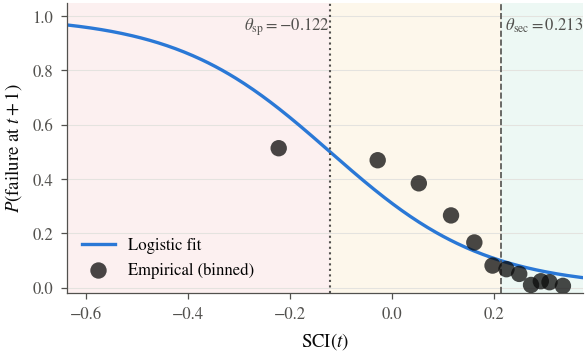

,quantity,value
0,logistic_intercept,-0.800651
1,logistic_slope,-6.570203
2,p_secure,0.100000
3,p_sparse,0.500000
4,theta_secure,0.212562
5,theta_sparse,-0.121861
6,calibration_rows,3525.000000
7,calibration_failure_rate,0.171915


,regime,n,failure_rate_next,mean_SCI
0,secure,1743,0.029260,0.280512
1,transition,1554,0.279279,0.092057
2,sparse,228,0.530702,-0.258013


[INFO] Regime thresholds: {'secure': 0.2125616947547822, 'sparse': -0.1218609258145728}
[SAVED] Outputs\quantum_secure_comm\tables\regime_threshold_calibration.csv
[SAVED] Outputs\quantum_secure_comm\tables\regime_calibration_check.csv


In [7]:
# -----------------------------
# Failure labels for indicator calibration and prediction
# -----------------------------
def add_failure_labels(slots, P=None):
    """fail(t) = 1 when the priority-weighted secure-service ratio falls below the failure level."""
    P = CONFIG if P is None else P
    level = P["prediction"]["failure_level"]
    df = slots.sort_values(["method", "scenario", "seed", "time"]).copy()
    df["fail"] = (df["weighted_secure_ratio"] < level).astype(int)
    grp = df.groupby(["method", "scenario", "seed"], sort=False)
    for k in P["prediction"]["horizons"]:
        df[f"fail_t{k}"] = grp["fail"].shift(-k)
    df["SCI_delta"] = grp["SCI"].diff().fillna(0.0)
    df["free_energy_delta"] = grp["free_energy"].diff().fillna(0.0)
    df["key_reserve_delta"] = grp["key_reserve"].diff().fillna(0.0)
    return df

# -----------------------------
# Calibration runs (seeds disjoint from evaluation seeds)
# -----------------------------
calib_dec, calib_slots = run_batch(CONFIG["calibration_seeds"], SCENARIOS, method_specs_for(["proposed"]))
calib_df = add_failure_labels(calib_slots)

# -----------------------------
# Risk-calibrated regime thresholds
# P(fail at t+1 | SCI(t)) is fitted by logistic regression; the secure/transition boundary
# is the SCI at which the one-step failure probability equals p_secure, and the
# transition/sparse boundary is where it equals p_sparse.
# -----------------------------
cal = calib_df.dropna(subset=["fail_t1"])
model_sci = fit_logistic(cal[["SCI"]].values, cal["fail_t1"].values)
w0, w1 = model_sci["w"]
a_raw = w0 - w1 * model_sci["mu"][0] / model_sci["sd"][0]
b_raw = w1 / model_sci["sd"][0]

def sci_at_probability(p):
    return float((np.log(p / (1.0 - p)) - a_raw) / b_raw)

p_secure = CONFIG["prediction"]["secure_probability"]
p_sparse = CONFIG["prediction"]["sparse_probability"]
if b_raw < 0:
    REGIME_THRESHOLDS["secure"] = sci_at_probability(p_secure)
    REGIME_THRESHOLDS["sparse"] = sci_at_probability(p_sparse)
else:
    REGIME_THRESHOLDS["secure"] = float(cal["SCI"].quantile(0.66))
    REGIME_THRESHOLDS["sparse"] = float(cal["SCI"].quantile(0.33))

calib_df["regime"] = calib_df["SCI"].apply(classify_security_regime)
regime_check = (
    calib_df.dropna(subset=["fail_t1"])
    .groupby("regime")
    .agg(n=("fail_t1", "size"), failure_rate_next=("fail_t1", "mean"), mean_SCI=("SCI", "mean"))
    .reindex(["secure", "transition", "sparse"])
    .reset_index()
)

threshold_table = pd.DataFrame([
    {"quantity": "logistic_intercept", "value": a_raw},
    {"quantity": "logistic_slope", "value": b_raw},
    {"quantity": "p_secure", "value": p_secure},
    {"quantity": "p_sparse", "value": p_sparse},
    {"quantity": "theta_secure", "value": REGIME_THRESHOLDS["secure"]},
    {"quantity": "theta_sparse", "value": REGIME_THRESHOLDS["sparse"]},
    {"quantity": "calibration_rows", "value": len(cal)},
    {"quantity": "calibration_failure_rate", "value": float(cal["fail_t1"].mean())},
])
threshold_table.to_csv(TAB_DIR / "regime_threshold_calibration.csv", index=False)
regime_check.to_csv(TAB_DIR / "regime_calibration_check.csv", index=False)

with open(OTH_DIR / "regime_thresholds.json", "w", encoding="utf-8") as f:
    json.dump(REGIME_THRESHOLDS, f, indent=2)

# -----------------------------
# Figure — Calibration of regime thresholds
# -----------------------------
bins = np.quantile(cal["SCI"], np.linspace(0, 1, 13))
bins = np.unique(bins)
cal_b = cal.assign(bin=pd.cut(cal["SCI"], bins, include_lowest=True))
emp = cal_b.groupby("bin", observed=True).agg(sci=("SCI", "mean"), p=("fail_t1", "mean"), n=("fail_t1", "size")).reset_index()

xs = np.linspace(cal["SCI"].min(), cal["SCI"].max(), 300)
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.6))
ax.axvspan(REGIME_THRESHOLDS["secure"], xs.max(), color=REGIME_COLORS["secure"], alpha=0.08, lw=0)
ax.axvspan(REGIME_THRESHOLDS["sparse"], REGIME_THRESHOLDS["secure"], color=REGIME_COLORS["transition"], alpha=0.08, lw=0)
ax.axvspan(xs.min(), REGIME_THRESHOLDS["sparse"], color=REGIME_COLORS["sparse"], alpha=0.08, lw=0)
ax.plot(xs, sigmoid(a_raw + b_raw * xs), color=PALETTE[0], lw=1.6, label="Logistic fit")
ax.scatter(emp["sci"], emp["p"], s=12 + 50 * emp["n"] / emp["n"].max(), color=INK, alpha=0.75, lw=0, zorder=3, label="Empirical (binned)")
ax.axvline(REGIME_THRESHOLDS["secure"], color=INK2, ls="--", lw=0.8)
ax.axvline(REGIME_THRESHOLDS["sparse"], color=INK2, ls=":", lw=1.0)
ax.text(REGIME_THRESHOLDS["secure"], 1.0, rf" $\theta_{{\mathrm{{sec}}}}={REGIME_THRESHOLDS['secure']:.3f}$", va="top", ha="left", fontsize=8, color=INK2)
ax.text(REGIME_THRESHOLDS["sparse"], 1.0, rf"$\theta_{{\mathrm{{sp}}}}={REGIME_THRESHOLDS['sparse']:.3f}$ ", va="top", ha="right", fontsize=8, color=INK2)
ax.set_xlabel(r"$\mathrm{SCI}(t)$")
ax.set_ylabel(r"$P(\mathrm{failure\ at}\ t+1)$")
ax.set_ylim(-0.02, 1.05)
ax.set_xlim(xs.min(), xs.max())
ax.legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "fig10_regime_threshold_calibration")

display(threshold_table)
display(regime_check)
print(f"[INFO] Regime thresholds: {REGIME_THRESHOLDS}")
print(f"[SAVED] {TAB_DIR / 'regime_threshold_calibration.csv'}")
print(f"[SAVED] {TAB_DIR / 'regime_calibration_check.csv'}")

## Cell 8 — Reference run: allocation-state summaries and criticality tables

This cell runs the proposed controller on the reference seed under the reference scenario (satellite-channel stress by default, so that regime transitions are visible) and summarizes the result. It produces flow-level and time-level tables, regime and allocation-state counts, and path, status, and key-layer switching statistics, together with a detailed decision table for tracing individual allocations.

In [8]:
# -----------------------------
# Reference run: proposed controller, reference scenario and seed
# -----------------------------
REF_SCENARIO = CONFIG["reference_scenario"]
ref_dec, ref_slots = run_batch([CONFIG["reference_seed"]], {REF_SCENARIO: SCENARIOS[REF_SCENARIO]}, method_specs_for(["proposed"]))
ref_slots["regime"] = ref_slots["SCI"].apply(classify_security_regime)

alloc_df = ref_dec.merge(
    ref_slots[["time", "SCI", "reserve", "deficit", "free_energy", "key_reserve", "regime", "weighted_secure_ratio", "allocated_ratio"]],
    on="time",
    how="left",
)

# -----------------------------
# Flow-level summary
# -----------------------------
summary_flow = alloc_df.groupby("flow_id").agg(
    mission=("mission", "first"),
    security_req=("security_req", "first"),
    secure_feasible_ratio=("secure_feasible", "mean"),
    allocated_ratio=("allocated", "mean"),
    avg_security_level=("security_level", "mean"),
    avg_security_margin=("effective_margin", "mean"),
    avg_qkd_assurance=("qkd_assurance", "mean"),
    avg_q_share=("q_share", "mean"),
    avg_trust=("trust_path", "mean"),
    avg_risk=("risk_path", "mean"),
    avg_channel_entropy=("channel_entropy", "mean"),
    avg_latency=("latency_path", "mean"),
    avg_energy=("energy", "mean"),
    avg_stress_energy=("stress_energy", "mean"),
    dominant_regime=("regime", lambda x: x.mode().iloc[0]),
    dominant_selection_status=("selection_status", lambda x: x.mode().iloc[0]),
).reset_index()

# -----------------------------
# Time-level summary
# -----------------------------
summary_time = alloc_df.groupby("time").agg(
    n_flows=("flow_id", "count"),
    secure_allocated_flows=("selection_status", lambda x: int((x == "secure_allocated").sum())),
    best_effort_flows=("selection_status", lambda x: int((x == "best_effort_allocated").sum())),
    degraded_flows=("selection_status", lambda x: int((x == "degraded_unallocated").sum())),
    blocked_flows=("selection_status", lambda x: int((x == "blocked").sum())),
    secure_feasible_ratio=("secure_feasible", "mean"),
    allocated_ratio=("allocated", "mean"),
    mean_security_level=("security_level", "mean"),
    mean_security_margin=("effective_margin", "mean"),
    mean_qkd_assurance=("qkd_assurance", "mean"),
    mean_q_share=("q_share", "mean"),
    mean_trust=("trust_path", "mean"),
    mean_risk=("risk_path", "mean"),
    mean_latency=("latency_path", "mean"),
    total_energy=("energy", "sum"),
).reset_index().merge(
    ref_slots[["time", "weighted_secure_ratio", "reserve", "deficit", "SCI", "free_energy",
               "effective_alternatives", "key_reserve", "mean_qber", "mean_key_rate", "weather", "regime"]],
    on="time",
)

# -----------------------------
# Regime and selection-state counts
# -----------------------------
regime_counts = (
    summary_time["regime"].value_counts()
    .reindex(["secure", "transition", "sparse"], fill_value=0)
    .rename_axis("regime").reset_index(name="count")
)

selection_status_counts = (
    alloc_df["selection_status"].value_counts()
    .reindex(STATUS_ORDER, fill_value=0)
    .rename_axis("selection_status").reset_index(name="count")
)

# -----------------------------
# Path stability / route switching
# -----------------------------
def path_stability_table(dec):
    rows = []
    for keys, grp in dec.sort_values("time").groupby(["method", "scenario", "seed", "flow_id"]):
        p = grp["path"].tolist()
        s = grp["selection_status"].tolist()
        v = grp["variant"].tolist()
        n = max(len(grp) - 1, 1)
        rows.append({
            "method": keys[0],
            "scenario": keys[1],
            "seed": keys[2],
            "flow_id": keys[3],
            "n_time_steps": len(grp),
            "path_switches": sum(p[i] != p[i - 1] for i in range(1, len(p))),
            "status_switches": sum(s[i] != s[i - 1] for i in range(1, len(s))),
            "key_layer_switches": sum(v[i] != v[i - 1] for i in range(1, len(v))),
            "path_switch_rate": sum(p[i] != p[i - 1] for i in range(1, len(p))) / n,
            "status_switch_rate": sum(s[i] != s[i - 1] for i in range(1, len(s))) / n,
            "key_layer_switch_rate": sum(v[i] != v[i - 1] for i in range(1, len(v))) / n,
            "unique_paths_used": grp["path"].nunique(),
            "blocked_fraction": float((grp["selection_status"] == "blocked").mean()),
            "secure_fraction": float((grp["selection_status"] == "secure_allocated").mean()),
        })
    return pd.DataFrame(rows)

path_stability_df = path_stability_table(ref_dec).drop(columns=["method", "scenario", "seed"])

# -----------------------------
# Decision table
# -----------------------------
decision_table = alloc_df[[
    "time", "flow_id", "mission", "src", "dst",
    "selection_status", "allocated", "secure_feasible",
    "path", "variant", "hop_count",
    "traffic_demand", "key_demand", "security_req", "priority",
    "qkd_assurance", "security_level", "security_margin", "effective_margin",
    "q_share", "trust_path", "risk_path", "channel_entropy", "latency_path",
    "energy", "pressure", "stress_energy",
    "SCI", "reserve", "deficit", "free_energy", "key_reserve", "regime",
]].copy()

# -----------------------------
# Save tables
# -----------------------------
summary_flow.to_csv(TAB_DIR / "summary_by_flow.csv", index=False)
summary_time.to_csv(TAB_DIR / "summary_by_time.csv", index=False)
regime_counts.to_csv(TAB_DIR / "regime_counts.csv", index=False)
selection_status_counts.to_csv(TAB_DIR / "selection_status_counts.csv", index=False)
path_stability_df.to_csv(TAB_DIR / "path_stability_summary.csv", index=False)
decision_table.to_csv(TAB_DIR / "decision_table.csv", index=False)

display(summary_flow)
display(summary_time)
display(regime_counts)
display(selection_status_counts)
display(path_stability_df)

for name in ["summary_by_flow", "summary_by_time", "regime_counts", "selection_status_counts", "path_stability_summary", "decision_table"]:
    print(f"[SAVED] {TAB_DIR / (name + '.csv')}")

[INFO] run_batch (reference): 1 seeds x 1 scenarios x 1 methods in 0.4s


,flow_id,mission,security_req,secure_feasible_ratio,allocated_ratio,avg_security_level,avg_security_margin,avg_qkd_assurance,avg_q_share,avg_trust,avg_risk,avg_channel_entropy,avg_latency,avg_energy,avg_stress_energy,dominant_regime,dominant_selection_status
0,F1,satellite_telemetry_backhaul,0.78,0.437500,0.958333,0.640312,-0.139688,0.367584,0.437500,0.770491,0.263564,0.273581,49.727777,9.650051,0.999621,transition,best_effort_allocated
1,F2,secure_satellite_access_delivery,0.72,0.729167,0.979167,0.697079,-0.022921,0.521758,0.729167,0.754437,0.366811,0.590993,52.254174,12.562047,1.015066,transition,secure_allocated
2,F3,uav_control_and_data_return,0.68,0.937500,0.958333,0.853250,0.173250,0.890625,0.937500,0.832721,0.219921,0.431256,18.646505,2.770258,0.617606,transition,secure_allocated
3,F4,gateway_to_edge_service_sync,0.50,1.000000,1.000000,0.909610,0.409610,0.950000,1.000000,0.856347,0.171881,0.279989,14.557997,1.015823,0.332905,transition,secure_allocated
4,F5,uav_to_local_edge_delivery,0.62,0.979167,0.979167,0.852121,0.232121,0.925865,0.979167,0.779284,0.299036,0.614501,15.415182,2.740002,0.605945,transition,secure_allocated


,time,n_flows,secure_allocated_flows,best_effort_flows,degraded_flows,blocked_flows,secure_feasible_ratio,allocated_ratio,mean_security_level,mean_security_margin,...,reserve,deficit,SCI,free_energy,effective_alternatives,key_reserve,mean_qber,mean_key_rate,weather,regime
0,0,5,5,0,0,0,1.0,1.0,0.898678,0.238678,...,0.342181,0.000000,0.342181,0.609473,3.326732,0.800000,0.053009,2.011128,0.782321,secure
1,1,5,5,0,0,0,1.0,1.0,0.881541,0.221541,...,0.313956,0.000000,0.313956,0.593204,4.368473,0.863529,0.045947,2.174969,0.879508,secure
2,2,5,3,0,0,2,0.6,0.6,0.531841,-0.128159,...,0.226180,0.466685,-0.240505,1.775342,1.506509,0.867463,0.056286,1.733033,0.950831,sparse
3,3,5,5,0,0,0,1.0,1.0,0.898575,0.238575,...,0.342080,0.000000,0.342080,0.541053,4.421672,0.880023,0.041792,2.231116,0.991431,secure
4,4,5,4,1,0,0,0.8,1.0,0.819481,0.159481,...,0.270242,0.055160,0.215082,0.931326,1.212098,0.873277,0.050413,1.448392,0.998541,secure
5,5,5,4,1,0,0,0.8,1.0,0.825235,0.165235,...,0.301506,0.082320,0.219186,0.810881,3.473018,0.872479,0.043507,2.276049,0.971677,secure
6,6,5,4,1,0,0,0.8,1.0,0.821585,0.161585,...,0.298261,0.085376,0.212884,0.832628,2.728257,0.867824,0.046998,2.183112,0.912668,secure
7,7,5,4,1,0,0,0.8,1.0,0.799118,0.139118,...,0.263208,0.084622,0.178586,0.789044,4.443925,0.861169,0.039730,2.316572,0.825536,transition
8,8,5,4,1,0,0,0.8,1.0,0.805282,0.145282,...,0.273851,0.086273,0.187579,0.787421,4.437217,0.855882,0.042595,2.257328,0.716220,transition
9,9,5,3,2,0,0,0.6,1.0,0.752352,0.092352,...,0.247904,0.143594,0.104310,0.985892,5.189982,0.853529,0.041393,2.215637,0.592169,transition


,regime,count
0,secure,22
1,transition,23
2,sparse,3


,selection_status,count
0,secure_allocated,196
1,best_effort_allocated,38
2,degraded_unallocated,0
3,blocked,6


,flow_id,n_time_steps,path_switches,status_switches,key_layer_switches,path_switch_rate,status_switch_rate,key_layer_switch_rate,unique_paths_used,blocked_fraction,secure_fraction
0,F1,48,33,22,22,0.702128,0.468085,0.468085,7,0.041667,0.437500
1,F2,48,37,16,16,0.787234,0.340426,0.340426,6,0.020833,0.729167
2,F3,48,28,5,5,0.595745,0.106383,0.106383,6,0.041667,0.937500
3,F4,48,14,0,0,0.297872,0.000000,0.000000,3,0.000000,1.000000
4,F5,48,19,2,2,0.404255,0.042553,0.042553,4,0.020833,0.979167


[SAVED] Outputs\quantum_secure_comm\tables\summary_by_flow.csv
[SAVED] Outputs\quantum_secure_comm\tables\summary_by_time.csv
[SAVED] Outputs\quantum_secure_comm\tables\regime_counts.csv
[SAVED] Outputs\quantum_secure_comm\tables\selection_status_counts.csv
[SAVED] Outputs\quantum_secure_comm\tables\path_stability_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\decision_table.csv


## Cell 9 — Reference-run figures and consolidated summary

This cell generates the figures for the reference run: topology, allocation outcomes, SCI with its reserve and deficit components and calibrated thresholds, secure feasibility, hybrid key-layer and key-buffer dynamics, the security margin-latency tradeoff, per-flow results, switching behavior, and the flow free energy with path diversity. A consolidated text summary is exported as well.

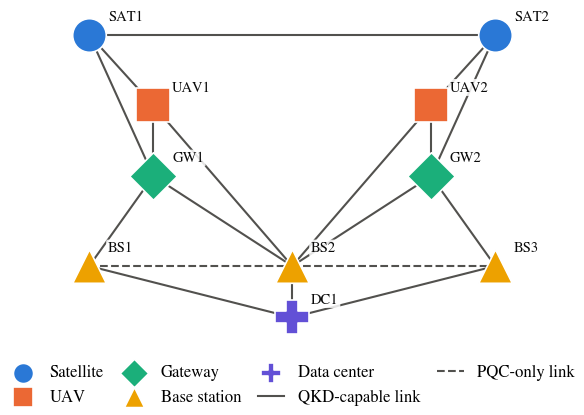

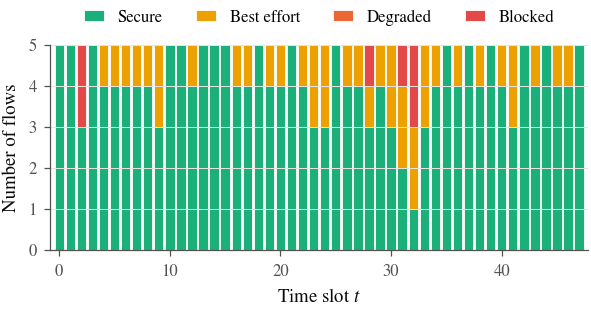

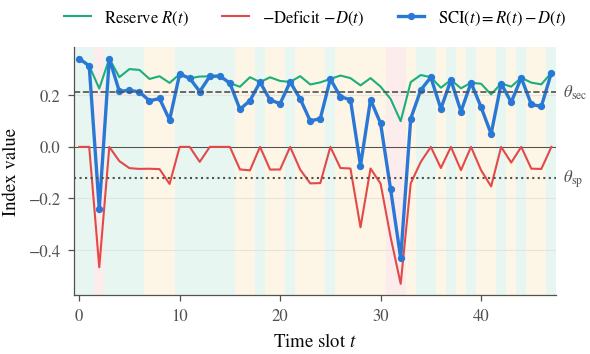

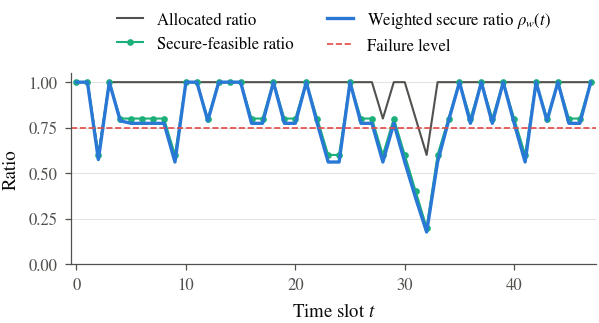

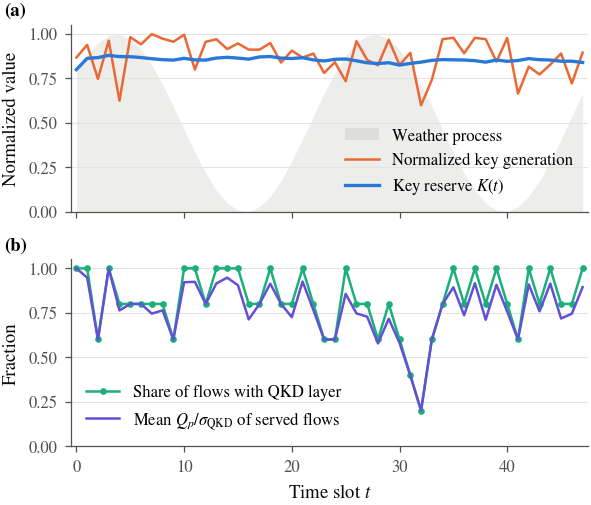

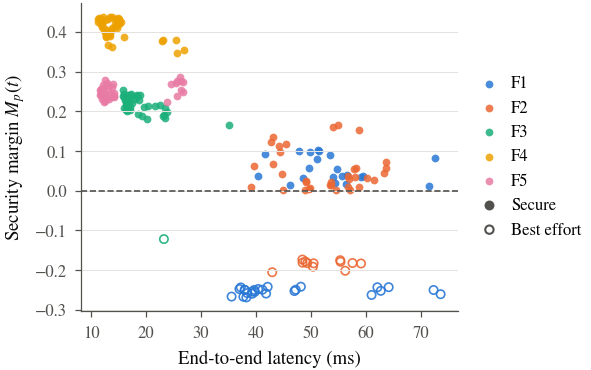

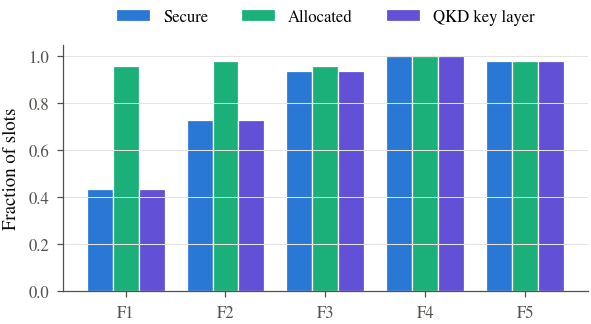

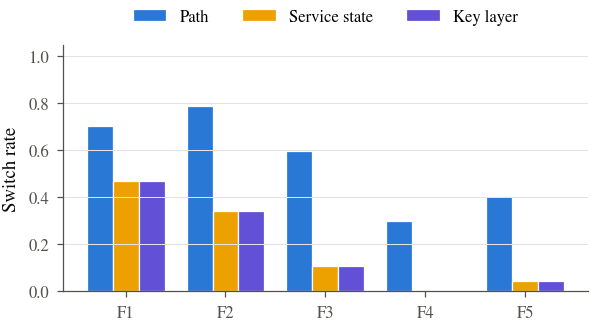

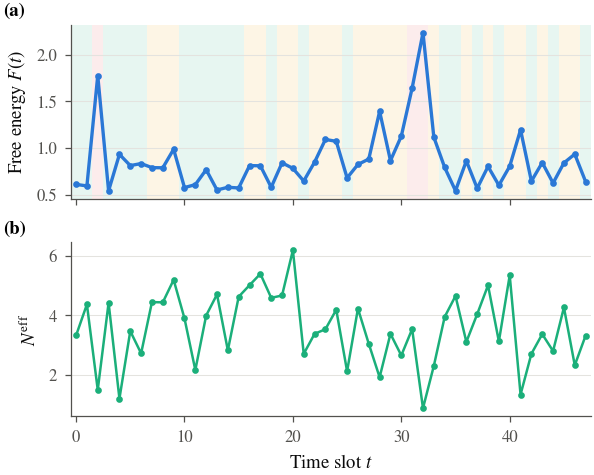

Quantum-Secure 6G STIN Hybrid Allocation (reference run, scenario: satellite_channel_stress)
Number of nodes: 10
Number of edges: 18
Number of flows: 5
Time steps: 48
Regime thresholds: secure >= 0.2126, sparse < -0.1219

Overall allocation-state counts:
- secure_allocated: 196
- best_effort_allocated: 38
- degraded_unallocated: 0
- blocked: 6

Overall regime counts:
- secure: 22
- transition: 23
- sparse: 3

Flow-level summary:
- F1 (satellite_telemetry_backhaul): S_req=0.78, secure_feasible_ratio=0.438, allocated_ratio=0.958, avg_security_level=0.6403, avg_effective_margin=-0.1397, avg_q_share=0.438, avg_risk=0.2636, avg_latency=49.73, avg_energy=9.650, dominant_status=best_effort_allocated
- F2 (secure_satellite_access_delivery): S_req=0.72, secure_feasible_ratio=0.729, allocated_ratio=0.979, avg_security_level=0.6971, avg_effective_margin=-0.0229, avg_q_share=0.729, avg_risk=0.3668, avg_latency=52.25, avg_energy=12.562, dominant_status=secure_allocated
- F3 (uav_control_and_data_re

In [9]:
# -----------------------------
# Prepare figure-friendly data
# -----------------------------
time_df = summary_time.sort_values("time").reset_index(drop=True)
flow_df = summary_flow.sort_values("flow_id").reset_index(drop=True)
switch_df = path_stability_df.sort_values("flow_id").reset_index(drop=True)

status_time_df = (
    alloc_df.groupby(["time", "selection_status"]).size()
    .unstack(fill_value=0)
    .reindex(columns=STATUS_ORDER, fill_value=0)
    .reset_index()
)

def shade_regimes(ax, times, regimes):
    for t_, r in zip(times, regimes):
        ax.axvspan(t_ - 0.5, t_ + 0.5, color=REGIME_COLORS[r], alpha=0.10, linewidth=0)

# -----------------------------
# Figure 1 — Role-aware topology
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 3.0))
pos = {n: G.nodes[n]["pos"] for n in G.nodes()}
role_style = {
    "satellite": ("o", PALETTE[0], "Satellite"),
    "uav": ("s", PALETTE[1], "UAV"),
    "gateway": ("D", PALETTE[2], "Gateway"),
    "base_station": ("^", PALETTE[3], "Base station"),
    "data_center": ("P", PALETTE[6], "Data center"),
}
qkd_edges_draw = [(u, v) for u, v in G.edges() if G[u][v]["supports_qkd"]]
non_qkd_edges_draw = [(u, v) for u, v in G.edges() if not G[u][v]["supports_qkd"]]
nx.draw_networkx_edges(G, pos, edgelist=qkd_edges_draw, width=1.0, edge_color=INK2, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=non_qkd_edges_draw, width=1.0, edge_color=INK2, style="dashed", ax=ax)
for role_name, (marker, color, label) in role_style.items():
    role_nodes = [n for n in G.nodes() if G.nodes[n]["role"] == role_name]
    nx.draw_networkx_nodes(G, pos, nodelist=role_nodes, node_shape=marker, node_color=color, node_size=260,
                           edgecolors="white", linewidths=0.8, label=label, ax=ax)
for n, p in pos.items():
    ax.text(p[0] + 0.035, p[1] + 0.035, n.replace("_", ""), fontsize=7, color=INK, ha="left", va="bottom", zorder=6,
            bbox={"boxstyle": "round,pad=0.12", "fc": "white", "ec": "none", "alpha": 0.85})
ax.plot([], [], color=INK2, lw=1.0, label="QKD-capable link")
ax.plot([], [], color=INK2, lw=1.0, ls="--", label="PQC-only link")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, markerscale=0.6, handlelength=1.6, columnspacing=1.0)
ax.set_ylim(-0.04, 1.02)
ax.axis("off")
fig.tight_layout()
save_figure(fig, "fig1_role_aware_topology")

# -----------------------------
# Figure 2 — Allocation outcomes over time
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.3))
bottom = np.zeros(len(status_time_df))
for status in STATUS_ORDER:
    vals = status_time_df[status].values
    ax.bar(status_time_df["time"], vals, bottom=bottom, width=0.85, color=STATUS_COLORS[status],
           edgecolor="white", linewidth=0.4, label=STATUS_LABELS[status])
    bottom = bottom + vals
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Number of flows")
ax.set_xlim(-0.8, len(status_time_df) - 0.2)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, handlelength=1.2)
fig.tight_layout()
save_figure(fig, "fig2_allocation_outcomes_over_time")

# -----------------------------
# Figure 3 — SCI with reserve, deficit, and calibrated regime thresholds
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.6))
shade_regimes(ax, time_df["time"], time_df["regime"])
ax.axhline(0.0, color=INK2, lw=0.5)
ax.plot(time_df["time"], time_df["reserve"], color=PALETTE[2], lw=1.0, label="Reserve $R(t)$")
ax.plot(time_df["time"], -time_df["deficit"], color=PALETTE[7], lw=1.0, label="$-$Deficit $-D(t)$")
ax.plot(time_df["time"], time_df["SCI"], color=PALETTE[0], lw=1.6, marker="o", ms=2.5, label="$\\mathrm{SCI}(t)=R(t)-D(t)$")
ax.axhline(REGIME_THRESHOLDS["secure"], color=INK2, ls="--", lw=0.8)
ax.axhline(REGIME_THRESHOLDS["sparse"], color=INK2, ls=":", lw=1.0)
ax.text(len(time_df) - 0.2, REGIME_THRESHOLDS["secure"], r" $\theta_{\mathrm{sec}}$", va="center", ha="left", fontsize=8, color=INK2, clip_on=False)
ax.text(len(time_df) - 0.2, REGIME_THRESHOLDS["sparse"], r" $\theta_{\mathrm{sp}}$", va="center", ha="left", fontsize=8, color=INK2, clip_on=False)
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Index value")
ax.set_xlim(-0.5, len(time_df) - 0.5)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, handlelength=1.6)
fig.tight_layout()
save_figure(fig, "fig3_sci_over_time")

# -----------------------------
# Figure 4 — Secure feasibility and allocation ratio
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.4))
ax.plot(time_df["time"], time_df["allocated_ratio"], color=INK2, lw=1.0, label="Allocated ratio")
ax.plot(time_df["time"], time_df["secure_feasible_ratio"], color=PALETTE[2], lw=1.0, marker="o", ms=2.2, label="Secure-feasible ratio")
ax.plot(time_df["time"], time_df["weighted_secure_ratio"], color=PALETTE[0], lw=1.6, label=r"Weighted secure ratio $\rho_w(t)$")
ax.axhline(CONFIG["prediction"]["failure_level"], color=PALETTE[7], ls="--", lw=0.8, label="Failure level")
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Ratio")
ax.set_ylim(0, 1.05)
ax.set_xlim(-0.5, len(time_df) - 0.5)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, handlelength=1.6)
fig.tight_layout()
save_figure(fig, "fig4_secure_feasibility_and_allocation")

# -----------------------------
# Figure 5 — Hybrid QKD/PQC contribution and key-buffer dynamics
# -----------------------------
fig, axes = plt.subplots(2, 1, figsize=(SINGLE_W, 3.6), sharex=True, gridspec_kw={"height_ratios": [1.0, 1.0]})
ax = axes[0]
ax.fill_between(time_df["time"], 0, time_df["weather"], color=INK2, alpha=0.10, lw=0, label="Weather process")
ax.plot(time_df["time"], time_df["mean_key_rate"] / max(time_df["mean_key_rate"].max(), 1e-9), color=PALETTE[1], lw=1.2, label="Normalized key generation")
ax.plot(time_df["time"], time_df["key_reserve"], color=PALETTE[0], lw=1.6, label="Key reserve $K(t)$")
ax.set_ylabel("Normalized value")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", ncol=1)
panel_label(ax, "a", x=-0.13)
ax = axes[1]
ax.plot(time_df["time"], time_df["mean_q_share"], color=PALETTE[2], lw=1.2, marker="o", ms=2.2, label="Share of flows with QKD layer")
ax.plot(time_df["time"], time_df["mean_qkd_assurance"] / CONFIG["security"]["sigma_qkd"], color=PALETTE[6], lw=1.2, label=r"Mean $Q_p/\sigma_{\mathrm{QKD}}$ of served flows")
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Fraction")
ax.set_ylim(0, 1.05)
ax.set_xlim(-0.5, len(time_df) - 0.5)
ax.legend(loc="lower left")
panel_label(ax, "b", x=-0.13)
fig.tight_layout(h_pad=0.8)
save_figure(fig, "fig5_hybrid_contribution_dynamics")

# -----------------------------
# Figure 6 — Security margin vs latency of served flows
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.7))
served = alloc_df[alloc_df["allocated"]]
flow_colors = dict(zip(sorted(served["flow_id"].unique()), PALETTE))
for fid, grp in served.groupby("flow_id"):
    sec = grp[grp["selection_status"] == "secure_allocated"]
    be = grp[grp["selection_status"] != "secure_allocated"]
    ax.scatter(sec["latency_path"], sec["security_margin"], s=14, color=flow_colors[fid], lw=0, alpha=0.85, label=fid)
    ax.scatter(be["latency_path"], be["security_margin"], s=16, facecolors="none", edgecolors=flow_colors[fid], lw=0.8, alpha=0.9)
ax.axhline(0.0, color=INK2, ls="--", lw=0.8)
ax.scatter([], [], s=14, color=INK2, label="Secure")
ax.scatter([], [], s=16, facecolors="none", edgecolors=INK2, label="Best effort")
ax.set_xlabel("End-to-end latency (ms)")
ax.set_ylabel("Security margin $M_p(t)$")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handletextpad=0.3)
fig.tight_layout()
save_figure(fig, "fig6_security_margin_vs_latency")

# -----------------------------
# Figure 7 — Per-flow secure and allocated ratios
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.4))
x = np.arange(len(flow_df))
width = 0.26
ax.bar(x - width, flow_df["secure_feasible_ratio"], width, color=PALETTE[0], edgecolor="white", linewidth=0.6, label="Secure")
ax.bar(x, flow_df["allocated_ratio"], width, color=PALETTE[2], edgecolor="white", linewidth=0.6, label="Allocated")
ax.bar(x + width, flow_df["avg_q_share"], width, color=PALETTE[6], edgecolor="white", linewidth=0.6, label="QKD key layer")
ax.set_xticks(x)
ax.set_xticklabels(flow_df["flow_id"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Fraction of slots")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3)
fig.tight_layout()
save_figure(fig, "fig7_per_flow_feasibility_and_allocation")

# -----------------------------
# Figure 8 — Path, status, and key-layer switching by flow
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.4))
x = np.arange(len(switch_df))
ax.bar(x - width, switch_df["path_switch_rate"], width, color=PALETTE[0], edgecolor="white", linewidth=0.6, label="Path")
ax.bar(x, switch_df["status_switch_rate"], width, color=PALETTE[3], edgecolor="white", linewidth=0.6, label="Service state")
ax.bar(x + width, switch_df["key_layer_switch_rate"], width, color=PALETTE[6], edgecolor="white", linewidth=0.6, label="Key layer")
ax.set_xticks(x)
ax.set_xticklabels(switch_df["flow_id"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Switch rate")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3)
fig.tight_layout()
save_figure(fig, "fig8_path_and_status_switching")

# -----------------------------
# Figure 9 — Free energy and effective path alternatives
# -----------------------------
fig, axes = plt.subplots(2, 1, figsize=(SINGLE_W, 3.4), sharex=True)
ax = axes[0]
shade_regimes(ax, time_df["time"], time_df["regime"])
ax.plot(time_df["time"], time_df["free_energy"], color=PALETTE[0], lw=1.6, marker="o", ms=2.2)
ax.set_ylabel("Free energy $F(t)$")
panel_label(ax, "a", x=-0.13)
ax = axes[1]
ax.plot(time_df["time"], time_df["effective_alternatives"], color=PALETTE[2], lw=1.2, marker="o", ms=2.2)
ax.set_ylabel(r"$N^{\mathrm{eff}}$")
ax.set_xlabel("Time slot $t$")
ax.set_xlim(-0.5, len(time_df) - 0.5)
panel_label(ax, "b", x=-0.13)
fig.tight_layout(h_pad=0.8)
save_figure(fig, "fig9_free_energy_over_time")

# -----------------------------
# Consolidated text summary
# -----------------------------
lines = []
lines.append(f"Quantum-Secure 6G STIN Hybrid Allocation (reference run, scenario: {REF_SCENARIO})")
lines.append("=" * 68)
lines.append(f"Number of nodes: {G.number_of_nodes()}")
lines.append(f"Number of edges: {G.number_of_edges()}")
lines.append(f"Number of flows: {len(flows)}")
lines.append(f"Time steps: {T}")
lines.append(f"Regime thresholds: secure >= {REGIME_THRESHOLDS['secure']:.4f}, sparse < {REGIME_THRESHOLDS['sparse']:.4f}")
lines.append("")
lines.append("Overall allocation-state counts:")
for _, row in selection_status_counts.iterrows():
    lines.append(f"- {row['selection_status']}: {int(row['count'])}")
lines.append("")
lines.append("Overall regime counts:")
for _, row in regime_counts.iterrows():
    lines.append(f"- {row['regime']}: {int(row['count'])}")
lines.append("")
lines.append("Flow-level summary:")
for _, row in flow_df.iterrows():
    lines.append(
        f"- {row['flow_id']} ({row['mission']}): S_req={row['security_req']:.2f}, "
        f"secure_feasible_ratio={row['secure_feasible_ratio']:.3f}, allocated_ratio={row['allocated_ratio']:.3f}, "
        f"avg_security_level={row['avg_security_level']:.4f}, avg_effective_margin={row['avg_security_margin']:.4f}, "
        f"avg_q_share={row['avg_q_share']:.3f}, avg_risk={row['avg_risk']:.4f}, avg_latency={row['avg_latency']:.2f}, "
        f"avg_energy={row['avg_energy']:.3f}, dominant_status={row['dominant_selection_status']}"
    )
lines.append("")
lines.append("Time-level summary:")
for _, row in time_df.iterrows():
    lines.append(
        f"- t={int(row['time'])}: secure={int(row['secure_allocated_flows'])}, best_effort={int(row['best_effort_flows'])}, "
        f"degraded={int(row['degraded_flows'])}, blocked={int(row['blocked_flows'])}, "
        f"weighted_secure_ratio={row['weighted_secure_ratio']:.3f}, SCI={row['SCI']:.4f}, "
        f"R={row['reserve']:.4f}, D={row['deficit']:.4f}, F={row['free_energy']:.4f}, "
        f"K={row['key_reserve']:.3f}, regime={row['regime']}"
    )
lines.append("")
lines.append("Path stability summary:")
for _, row in switch_df.iterrows():
    lines.append(
        f"- {row['flow_id']}: path_switch_rate={row['path_switch_rate']:.3f}, status_switch_rate={row['status_switch_rate']:.3f}, "
        f"key_layer_switch_rate={row['key_layer_switch_rate']:.3f}, unique_paths_used={int(row['unique_paths_used'])}, "
        f"secure_fraction={row['secure_fraction']:.3f}"
    )
lines.append("")
lines.append("Exported figures:")
for fig_name in sorted(os.listdir(FIG_DIR)):
    lines.append(f"- {fig_name}")

OUTPUTS_SUMMARY_PATH.write_text("\n".join(lines), encoding="utf-8")
print(OUTPUTS_SUMMARY_PATH.read_text(encoding="utf-8"))
print(f"[SAVED] {OUTPUTS_SUMMARY_PATH}")

## Cell 10 — Multi-seed comparison with baseline methods

This cell compares all allocation methods under nominal conditions over the evaluation seeds. Seed-level metrics include the priority-weighted secure ratio, allocation ratio, SCI, deficit, effective margin, latency, energy and key consumption per unit of secure traffic, QKD key-layer share, key reserve, failure fraction, and path-switch rate. Results are reported as means with 95% confidence intervals, and the proposed controller is compared with each baseline using paired Wilcoxon signed-rank tests over seeds.

In [10]:
# -----------------------------
# Metric definitions
# -----------------------------
METRIC_DIRECTIONS = {
    "weighted_secure_ratio": "max",
    "secure_ratio": "max",
    "allocated_ratio": "max",
    "SCI": "max",
    "reserve": "max",
    "deficit": "min",
    "free_energy": "min",
    "key_reserve": "max",
    "mean_effective_margin": "max",
    "mean_latency": "min",
    "energy_per_secure_unit": "min",
    "key_per_secure_unit": "min",
    "failure_fraction": "min",
    "path_switch_rate": "min",
    "mean_risk": "min",
    "q_share": "none",
}
KEY_METRICS = [
    "weighted_secure_ratio", "allocated_ratio", "SCI", "deficit", "mean_effective_margin",
    "mean_latency", "energy_per_secure_unit", "key_reserve", "q_share", "failure_fraction",
]

def seed_metrics(dec, slots, keys=("method", "scenario", "seed")):
    keys = list(keys)
    level = CONFIG["prediction"]["failure_level"]
    s = slots.groupby(keys).agg(
        weighted_secure_ratio=("weighted_secure_ratio", "mean"),
        secure_ratio=("secure_ratio", "mean"),
        allocated_ratio=("allocated_ratio", "mean"),
        SCI=("SCI", "mean"),
        reserve=("reserve", "mean"),
        deficit=("deficit", "mean"),
        free_energy=("free_energy", "mean"),
        key_reserve=("key_reserve", "mean"),
        energy_total=("energy_total", "sum"),
        secure_traffic=("secure_traffic", "sum"),
        key_consumed=("key_consumed", "sum"),
        failure_fraction=("weighted_secure_ratio", lambda x: float((x < level).mean())),
    ).reset_index()
    s["energy_per_secure_unit"] = s["energy_total"] / s["secure_traffic"].replace(0, np.nan)
    s["key_per_secure_unit"] = s["key_consumed"] / s["secure_traffic"].replace(0, np.nan)
    served = dec[dec["allocated"]]
    d = dec.groupby(keys).agg(mean_effective_margin=("effective_margin", "mean")).reset_index()
    d2 = served.groupby(keys).agg(
        mean_latency=("latency_path", "mean"),
        q_share=("q_share", "mean"),
        mean_risk=("risk_path", "mean"),
    ).reset_index()
    ps = path_stability_table(dec).groupby(keys)["path_switch_rate"].mean().reset_index()
    return s.merge(d, on=keys, how="left").merge(d2, on=keys, how="left").merge(ps, on=keys, how="left")

def summarize_with_ci(seed_df, group_cols, metrics):
    rows = []
    for keys, grp in seed_df.groupby(group_cols):
        keys = keys if isinstance(keys, tuple) else (keys,)
        row = dict(zip(group_cols, keys))
        row["n_seeds"] = grp["seed"].nunique()
        for m in metrics:
            mean, lo, hi = mean_ci(grp[m])
            row[m] = mean
            row[f"{m}_ci_low"] = lo
            row[f"{m}_ci_high"] = hi
        rows.append(row)
    return pd.DataFrame(rows)

def paired_tests(seed_df, reference, others, metrics, group_cols=("scenario",), label_col="method"):
    rows = []
    group_cols = list(group_cols)
    for gkeys, grp in seed_df.groupby(group_cols):
        gkeys = gkeys if isinstance(gkeys, tuple) else (gkeys,)
        ref = grp[grp[label_col] == reference].set_index("seed")
        for other in others:
            oth = grp[grp[label_col] == other].set_index("seed")
            common = ref.index.intersection(oth.index)
            for m in metrics:
                a = ref.loc[common, m].astype(float)
                b = oth.loc[common, m].astype(float)
                ok = a.notna() & b.notna()
                diff = (a[ok] - b[ok]).values
                direction = METRIC_DIRECTIONS.get(m, "max")
                if len(diff) == 0:
                    continue
                mean_d, lo, hi = mean_ci(diff)
                if np.allclose(diff, 0.0):
                    p_val = 1.0
                else:
                    try:
                        p_val = float(stats.wilcoxon(diff, zero_method="zsplit").pvalue)
                    except ValueError:
                        p_val = 1.0
                sign = 1.0 if direction == "max" else (-1.0 if direction == "min" else 0.0)
                rows.append({
                    **dict(zip(group_cols, gkeys)),
                    "reference": reference,
                    "baseline": other,
                    "metric": m,
                    "direction": direction,
                    "n": len(diff),
                    "mean_difference": mean_d,
                    "ci_low": lo,
                    "ci_high": hi,
                    "wins": int(np.sum(sign * diff > 1e-12)),
                    "ties": int(np.sum(np.abs(diff) <= 1e-12)),
                    "losses": int(np.sum(sign * diff < -1e-12)),
                    "wilcoxon_p": p_val,
                })
    return pd.DataFrame(rows)

# -----------------------------
# Multi-seed comparison under nominal conditions
# -----------------------------
eval_seeds = CONFIG["evaluation_seeds"]
nominal_dec, nominal_slots = run_batch(eval_seeds, {"nominal": SCENARIOS["nominal"]}, method_specs_for(METHODS))
nominal_slots["regime"] = nominal_slots["SCI"].apply(classify_security_regime)

nominal_seed_df = seed_metrics(nominal_dec, nominal_slots)
metric_cols = list(METRIC_DIRECTIONS.keys())
method_summary = summarize_with_ci(nominal_seed_df, ["method"], metric_cols)
method_summary["method"] = pd.Categorical(method_summary["method"], categories=METHODS, ordered=True)
method_summary = method_summary.sort_values("method").reset_index(drop=True)

paired_nominal = paired_tests(nominal_seed_df, "proposed", BASELINES, metric_cols)

method_status_summary = (
    nominal_dec.groupby(["method", "selection_status"]).size().rename("count").reset_index()
    .assign(per_seed=lambda d: d["count"] / len(eval_seeds))
)
method_regime_summary = (
    nominal_slots.groupby(["method", "regime"]).size().rename("count").reset_index()
    .assign(fraction=lambda d: d["count"] / d.groupby("method")["count"].transform("sum"))
)
method_flow_summary = nominal_dec.groupby(["method", "flow_id"]).agg(
    secure_feasible_ratio=("secure_feasible", "mean"),
    allocated_ratio=("allocated", "mean"),
    avg_security_margin=("effective_margin", "mean"),
    avg_latency=("latency_path", "mean"),
    avg_q_share=("q_share", "mean"),
    avg_energy=("energy", "mean"),
).reset_index()

method_time_summary = summarize_with_ci(
    nominal_slots,
    ["method", "time"],
    ["weighted_secure_ratio", "secure_ratio", "allocated_ratio", "SCI", "deficit", "free_energy", "key_reserve"],
)

# -----------------------------
# Save comparison tables
# -----------------------------
nominal_seed_df.to_csv(TAB_DIR / "comparison_seed_level_metrics.csv", index=False)
method_summary.to_csv(TAB_DIR / "comparison_method_summary.csv", index=False)
paired_nominal.to_csv(TAB_DIR / "comparison_paired_tests.csv", index=False)
method_status_summary.to_csv(TAB_DIR / "comparison_method_status_summary.csv", index=False)
method_regime_summary.to_csv(TAB_DIR / "comparison_method_regime_summary.csv", index=False)
method_flow_summary.to_csv(TAB_DIR / "comparison_method_flow_summary.csv", index=False)
method_time_summary.to_csv(TAB_DIR / "comparison_method_time_summary.csv", index=False)

display(method_summary[["method", "n_seeds"] + KEY_METRICS])
display(paired_nominal[paired_nominal["metric"].isin(["weighted_secure_ratio", "SCI", "deficit", "energy_per_secure_unit", "mean_latency"])])

for name in ["comparison_seed_level_metrics", "comparison_method_summary", "comparison_paired_tests",
             "comparison_method_status_summary", "comparison_method_regime_summary",
             "comparison_method_flow_summary", "comparison_method_time_summary"]:
    print(f"[SAVED] {TAB_DIR / (name + '.csv')}")

[INFO] run_batch (reference): 30 seeds x 1 scenarios x 6 methods in 35.5s


,method,n_seeds,weighted_secure_ratio,allocated_ratio,SCI,deficit,mean_effective_margin,mean_latency,energy_per_secure_unit,key_reserve,q_share,failure_fraction
0,proposed,30,0.969966,0.991944,0.286063,0.015724,0.202441,27.593295,1.288592,0.933757,0.981794,0.011806
1,milp_max_secure,30,0.937695,0.991944,0.291530,0.015295,0.206119,29.368498,1.481035,0.919593,0.995244,0.052083
2,max_security,30,0.934226,0.990417,0.289738,0.016709,0.204900,29.488087,1.487559,0.920187,0.995935,0.061111
3,latency_first,30,0.945007,0.990556,0.262986,0.017947,0.186482,25.624885,1.333536,0.921663,0.972006,0.033333
4,pqc_trust,30,0.941726,0.990000,0.262506,0.019409,0.186831,28.180984,1.405531,0.917461,0.979263,0.023611
5,qkd_priority,30,0.944520,0.990556,0.286847,0.016073,0.202595,26.622583,1.366127,0.925979,0.995665,0.061111


,scenario,reference,baseline,metric,direction,n,mean_difference,ci_low,ci_high,wins,ties,losses,wilcoxon_p
0,nominal,proposed,milp_max_secure,weighted_secure_ratio,max,30,0.032271,0.013240,0.051303,16,6,8,1.307323e-02
3,nominal,proposed,milp_max_secure,SCI,max,30,-0.005467,-0.011184,0.000250,9,0,21,6.056523e-02
5,nominal,proposed,milp_max_secure,deficit,min,30,0.000429,-0.001310,0.002169,11,6,13,3.986228e-01
9,nominal,proposed,milp_max_secure,mean_latency,min,30,-1.775202,-2.223507,-1.326897,28,0,2,1.862645e-08
10,nominal,proposed,milp_max_secure,energy_per_secure_unit,min,30,-0.192443,-0.234863,-0.150022,29,0,1,3.725290e-09
16,nominal,proposed,max_security,weighted_secure_ratio,max,30,0.035740,0.015323,0.056157,21,3,6,1.476200e-03
19,nominal,proposed,max_security,SCI,max,30,-0.003675,-0.009526,0.002177,10,0,20,2.285528e-01
21,nominal,proposed,max_security,deficit,min,30,-0.000985,-0.002939,0.000970,17,3,10,2.988926e-01
25,nominal,proposed,max_security,mean_latency,min,30,-1.894792,-2.282842,-1.506742,30,0,0,1.862645e-09
26,nominal,proposed,max_security,energy_per_secure_unit,min,30,-0.198966,-0.243691,-0.154241,29,0,1,3.725290e-09


[SAVED] Outputs\quantum_secure_comm\tables\comparison_seed_level_metrics.csv
[SAVED] Outputs\quantum_secure_comm\tables\comparison_method_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\comparison_paired_tests.csv
[SAVED] Outputs\quantum_secure_comm\tables\comparison_method_status_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\comparison_method_regime_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\comparison_method_flow_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\comparison_method_time_summary.csv


## Cell 11 — Comparative figures

This cell plots the method comparison with confidence intervals: overall secure service, SCI, and deficit; SCI, secure ratio, and key reserve over time; allocation-state composition; per-flow margins; the latency-QKD-share tradeoff; and energy and key efficiency.

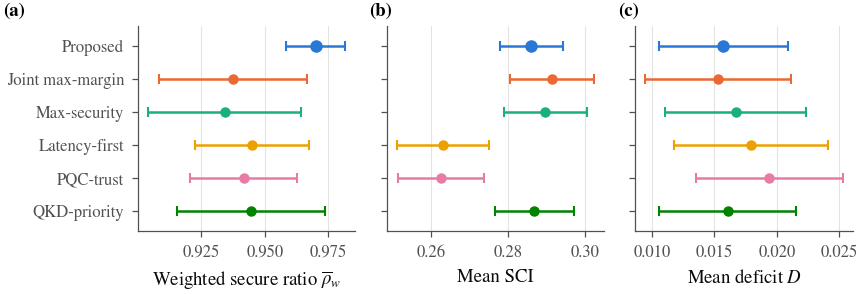

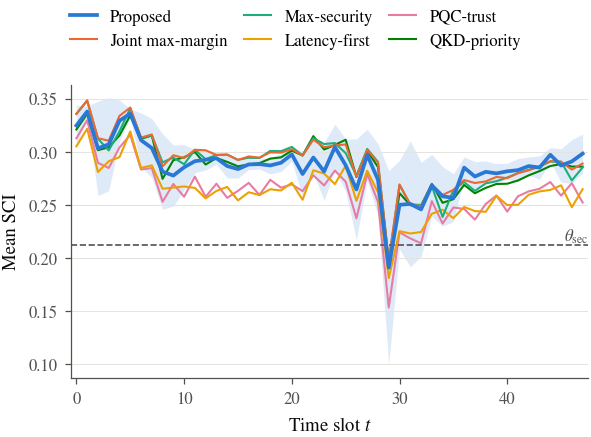

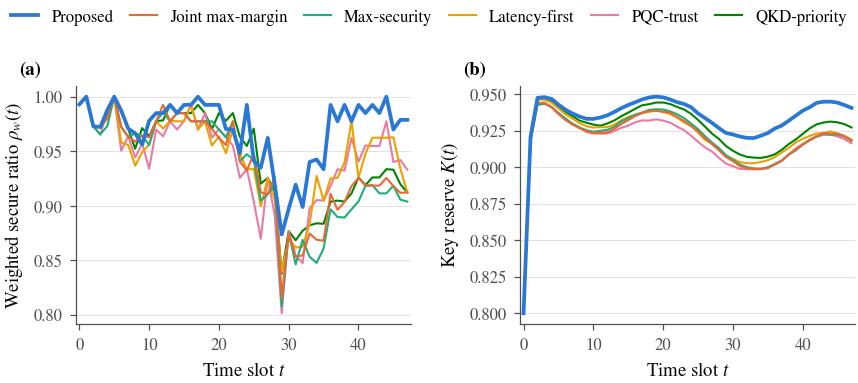

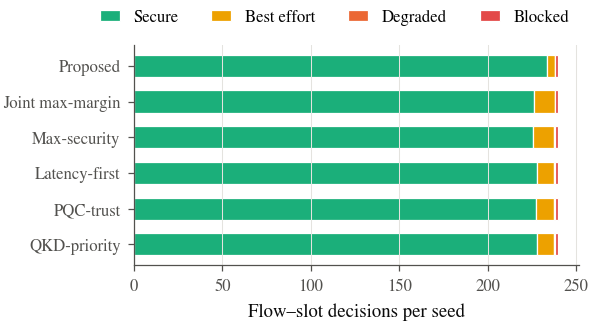

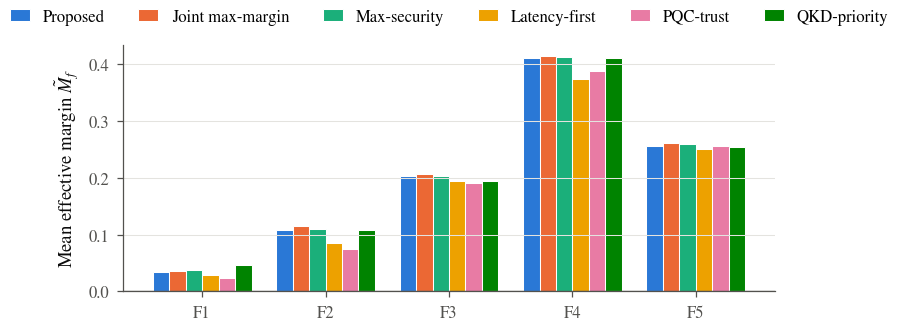

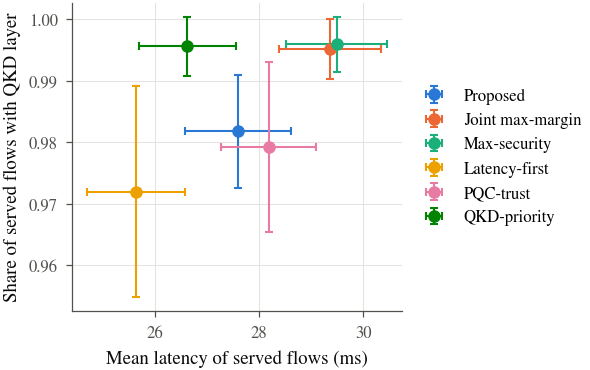

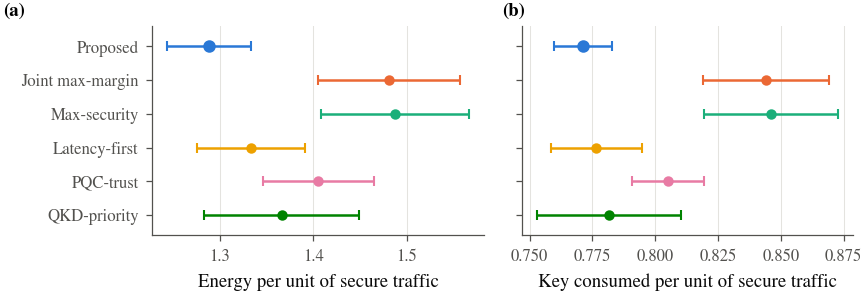

Saved comparative figures:
- fig11_method_overall_comparison.pdf
- fig11_method_overall_comparison.png
- fig12_sci_over_time_by_method.pdf
- fig12_sci_over_time_by_method.png
- fig13_secure_ratio_and_key_reserve_by_method.pdf
- fig13_secure_ratio_and_key_reserve_by_method.png
- fig14_allocation_state_composition_by_method.pdf
- fig14_allocation_state_composition_by_method.png
- fig15_per_flow_security_margin_by_method.pdf
- fig15_per_flow_security_margin_by_method.png
- fig16_latency_vs_quantum_share_by_method.pdf
- fig16_latency_vs_quantum_share_by_method.png
- fig17_energy_and_key_efficiency_by_method.pdf
- fig17_energy_and_key_efficiency_by_method.png


In [11]:
# -----------------------------
# Figure helpers
# -----------------------------
method_order = METHODS
METHOD_COLORS = dict(zip(METHODS, PALETTE[:len(METHODS)]))

def method_style(m):
    return {"lw": 1.8, "zorder": 5} if m == "proposed" else {"lw": 1.0, "zorder": 2}

def dot_ci(ax, df, col, labels_on=True):
    """Point estimate with 95% CI whiskers, one row per method."""
    y = np.arange(len(df))[::-1]
    for yi, (_, row) in zip(y, df.iterrows()):
        c = METHOD_COLORS[row["method"]]
        ax.errorbar(row[col], yi, xerr=[[row[col] - row[f"{col}_ci_low"]], [row[f"{col}_ci_high"] - row[col]]],
                    fmt="o", color=c, ecolor=c, elinewidth=1.2, capsize=2.5, ms=5 if row["method"] == "proposed" else 4)
    ax.set_yticks(y)
    ax.set_yticklabels([METHOD_LABELS[m] for m in df["method"]] if labels_on else [])
    ax.set_ylim(-0.6, len(df) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)

def method_legend(fig, axes_with_handles, ncol=6, y=1.06):
    h, l = axes_with_handles.get_legend_handles_labels()
    order = [l.index(METHOD_LABELS[m]) for m in METHODS if METHOD_LABELS[m] in l]
    fig.legend([h[i] for i in order], [l[i] for i in order], loc="lower center", ncol=ncol,
               bbox_to_anchor=(0.5, 1.0), handlelength=1.6, columnspacing=1.0)

ms = method_summary.set_index("method").loc[method_order].reset_index()

# -----------------------------
# Figure 11 — Overall method comparison (mean and 95% CI over seeds)
# -----------------------------
fig, axes = plt.subplots(1, 3, figsize=(FULL_W, 2.2))
for ax, (col, lab), L in zip(axes, [("weighted_secure_ratio", r"Weighted secure ratio $\overline{\rho}_w$"),
                                     ("SCI", "Mean SCI"), ("deficit", r"Mean deficit $D$")], "abc"):
    dot_ci(ax, ms, col, labels_on=(L == "a"))
    ax.set_xlabel(lab)
    panel_label(ax, L, x=-0.08 if L != "a" else -0.62)
fig.tight_layout(w_pad=0.8)
save_figure(fig, "fig11_method_overall_comparison")

# -----------------------------
# Figure 12 — SCI over time by method
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.6))
for m in method_order[::-1]:
    g = method_time_summary[method_time_summary["method"] == m].sort_values("time")
    ax.plot(g["time"], g["SCI"], color=METHOD_COLORS[m], label=METHOD_LABELS[m], **method_style(m))
    if m == "proposed":
        ax.fill_between(g["time"], g["SCI_ci_low"], g["SCI_ci_high"], color=METHOD_COLORS[m], alpha=0.15, lw=0, zorder=1)
ax.axhline(REGIME_THRESHOLDS["secure"], color=INK2, ls="--", lw=0.8)
ax.text(CONFIG["time_horizon"] - 0.5, REGIME_THRESHOLDS["secure"], r"$\theta_{\mathrm{sec}}$", va="bottom", ha="right", fontsize=8, color=INK2)
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Mean SCI")
ax.set_xlim(-0.5, CONFIG["time_horizon"] - 0.5)
method_legend(fig, ax, ncol=3, y=1.12)
fig.tight_layout()
save_figure(fig, "fig12_sci_over_time_by_method")

# -----------------------------
# Figure 13 — Weighted secure ratio and key reserve over time by method
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.4))
for m in method_order[::-1]:
    g = method_time_summary[method_time_summary["method"] == m].sort_values("time")
    axes[0].plot(g["time"], g["weighted_secure_ratio"], color=METHOD_COLORS[m], label=METHOD_LABELS[m], **method_style(m))
    axes[1].plot(g["time"], g["key_reserve"], color=METHOD_COLORS[m], label=METHOD_LABELS[m], **method_style(m))
axes[0].set_ylabel(r"Weighted secure ratio $\rho_w(t)$")
axes[1].set_ylabel("Key reserve $K(t)$")
for ax, L in zip(axes, "ab"):
    ax.set_xlabel("Time slot $t$")
    ax.set_xlim(-0.5, CONFIG["time_horizon"] - 0.5)
    panel_label(ax, L, x=-0.17)
method_legend(fig, axes[0], ncol=6, y=1.09)
fig.tight_layout(w_pad=1.5)
save_figure(fig, "fig13_secure_ratio_and_key_reserve_by_method")

# -----------------------------
# Figure 14 — Allocation-state composition by method
# -----------------------------
status_pivot = (
    method_status_summary.pivot(index="method", columns="selection_status", values="per_seed")
    .reindex(index=method_order, columns=STATUS_ORDER).fillna(0)
)
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.4))
y = np.arange(len(status_pivot))[::-1]
left = np.zeros(len(status_pivot))
for status in STATUS_ORDER:
    vals = status_pivot[status].values
    ax.barh(y, vals, left=left, height=0.62, color=STATUS_COLORS[status], edgecolor="white", linewidth=0.6, label=STATUS_LABELS[status])
    left += vals
ax.set_yticks(y)
ax.set_yticklabels([METHOD_LABELS[m] for m in status_pivot.index])
ax.set_xlabel("Flow–slot decisions per seed")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.02), ncol=4, handlelength=1.2)
fig.tight_layout()
save_figure(fig, "fig14_allocation_state_composition_by_method")

# -----------------------------
# Figure 15 — Per-flow effective security margin by method
# -----------------------------
flow_ids = sorted(method_flow_summary["flow_id"].unique())
fig, ax = plt.subplots(figsize=(FULL_W, 2.4))
x = np.arange(len(flow_ids))
width = 0.8 / len(method_order)
for i, m in enumerate(method_order):
    sub = method_flow_summary[method_flow_summary["method"] == m].set_index("flow_id").reindex(flow_ids)
    ax.bar(x + (i - (len(method_order) - 1) / 2) * width, sub["avg_security_margin"], width,
           color=METHOD_COLORS[m], edgecolor="white", linewidth=0.5, label=METHOD_LABELS[m])
ax.axhline(0.0, color=INK2, lw=0.6)
ax.set_xticks(x)
ax.set_xticklabels(flow_ids)
ax.set_ylabel(r"Mean effective margin $\tilde{M}_f$")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=6, handlelength=1.2)
fig.tight_layout()
save_figure(fig, "fig15_per_flow_security_margin_by_method")

# -----------------------------
# Figure 16 — Latency vs QKD key-layer share
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.7))
for _, row in ms.iterrows():
    c = METHOD_COLORS[row["method"]]
    ax.errorbar(row["mean_latency"], row["q_share"],
                xerr=[[row["mean_latency"] - row["mean_latency_ci_low"]], [row["mean_latency_ci_high"] - row["mean_latency"]]],
                yerr=[[row["q_share"] - row["q_share_ci_low"]], [row["q_share_ci_high"] - row["q_share"]]],
                fmt="o", ms=5, color=c, ecolor=c, elinewidth=1.0, capsize=2, label=METHOD_LABELS[row["method"]])
ax.set_xlabel("Mean latency of served flows (ms)")
ax.set_ylabel("Share of served flows with QKD layer")
ax.grid(axis="x", visible=True)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
save_figure(fig, "fig16_latency_vs_quantum_share_by_method")

# -----------------------------
# Figure 17 — Energy and key consumption per secure traffic unit
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.2))
dot_ci(axes[0], ms, "energy_per_secure_unit", labels_on=True)
axes[0].set_xlabel("Energy per unit of secure traffic")
dot_ci(axes[1], ms, "key_per_secure_unit", labels_on=False)
axes[1].set_xlabel("Key consumed per unit of secure traffic")
panel_label(axes[0], "a", x=-0.45)
panel_label(axes[1], "b", x=-0.06)
fig.tight_layout(w_pad=1.0)
save_figure(fig, "fig17_energy_and_key_efficiency_by_method")

print("Saved comparative figures:")
for fig_name in sorted(os.listdir(FIG_DIR)):
    if any(fig_name.startswith(f"fig{i}_") for i in range(11, 18)):
        print("-", fig_name)

## Cell 12 — Comparative summary tables and key findings

This cell condenses the comparison into a multi-metric rank table, mean paired differences against each baseline, per-seed win counts, and per-flow best methods. It also lists key findings that report effect sizes, confidence intervals, and test results directly from the tables.

In [12]:
# -----------------------------
# Multi-metric rank table (nominal)
# -----------------------------
rank_metrics = [m for m, d in METRIC_DIRECTIONS.items() if d != "none"]
method_rank_table = method_summary[["method"] + rank_metrics].copy()
for col in rank_metrics:
    ascending = METRIC_DIRECTIONS[col] == "min"
    method_rank_table[f"rank_{col}"] = method_rank_table[col].rank(ascending=ascending, method="min")
rank_cols = [c for c in method_rank_table.columns if c.startswith("rank_")]
method_rank_table["mean_rank"] = method_rank_table[rank_cols].mean(axis=1)
method_rank_table = method_rank_table.sort_values("mean_rank").reset_index(drop=True)

# -----------------------------
# Proposed vs baselines (mean differences with CI and Wilcoxon p-values)
# -----------------------------
improvement_df = (
    paired_nominal[paired_nominal["metric"].isin(KEY_METRICS)]
    .pivot_table(index="baseline", columns="metric", values="mean_difference")
    .reindex(BASELINES)
    .add_prefix("delta_")
    .reset_index()
)

# -----------------------------
# Per-seed winners by metric
# -----------------------------
win_records = []
for metric in ["weighted_secure_ratio", "SCI", "deficit", "mean_effective_margin", "mean_latency", "energy_per_secure_unit"]:
    direction = METRIC_DIRECTIONS[metric]
    for seed, grp in nominal_seed_df.groupby("seed"):
        best = grp[metric].max() if direction == "max" else grp[metric].min()
        for w in grp.loc[np.isclose(grp[metric], best), "method"]:
            win_records.append({"seed": seed, "metric": metric, "winner_method": w, "winning_value": best})
seed_metric_wins_df = pd.DataFrame(win_records)
seed_metric_win_counts = (
    seed_metric_wins_df.groupby(["metric", "winner_method"]).size().rename("win_count").reset_index()
    .sort_values(["metric", "win_count"], ascending=[True, False])
)

# -----------------------------
# Per-flow best method table
# -----------------------------
flow_best_records = []
for flow_id, grp in method_flow_summary.groupby("flow_id"):
    flow_best_records.append({
        "flow_id": flow_id,
        "best_security_margin_method": grp.loc[grp["avg_security_margin"].idxmax(), "method"],
        "best_security_margin_value": grp["avg_security_margin"].max(),
        "best_secure_feasible_method": grp.loc[grp["secure_feasible_ratio"].idxmax(), "method"],
        "best_secure_feasible_value": grp["secure_feasible_ratio"].max(),
        "best_latency_method": grp.loc[grp["avg_latency"].idxmin(), "method"],
        "best_latency_value": grp["avg_latency"].min(),
    })
flow_best_method_df = pd.DataFrame(flow_best_records)

# -----------------------------
# Key findings
# -----------------------------
def fmt_test(row):
    return f"{row['mean_difference']:+.4f} [95% CI {row['ci_low']:+.4f}, {row['ci_high']:+.4f}], Wilcoxon p={row['wilcoxon_p']:.3g}, wins/ties/losses={row['wins']}/{row['ties']}/{row['losses']}"

findings = []
findings.append(
    f"Nominal multi-metric ranking over {len(eval_seeds)} seeds places '{method_rank_table.iloc[0]['method']}' first "
    f"(mean rank {method_rank_table.iloc[0]['mean_rank']:.2f})."
)
for baseline in BASELINES:
    for metric in ["weighted_secure_ratio", "SCI", "energy_per_secure_unit"]:
        row = paired_nominal[(paired_nominal["baseline"] == baseline) & (paired_nominal["metric"] == metric)]
        if len(row):
            findings.append(f"proposed - {baseline}, {metric}: {fmt_test(row.iloc[0])}.")
pr = method_summary.set_index("method").loc["proposed"]
findings.append(
    f"The proposed controller uses the QKD key layer for {pr['q_share']:.3f} of served flows and keeps a mean "
    f"key reserve of {pr['key_reserve']:.3f}."
)
findings_df = pd.DataFrame({"finding": findings})

# -----------------------------
# Save tables
# -----------------------------
method_rank_table.to_csv(TAB_DIR / "comparison_method_rank_table.csv", index=False)
improvement_df.to_csv(TAB_DIR / "comparison_proposed_vs_baselines.csv", index=False)
seed_metric_wins_df.to_csv(TAB_DIR / "comparison_seed_metric_wins_detailed.csv", index=False)
seed_metric_win_counts.to_csv(TAB_DIR / "comparison_seed_metric_win_counts.csv", index=False)
flow_best_method_df.to_csv(TAB_DIR / "comparison_flow_best_methods.csv", index=False)
findings_df.to_csv(TAB_DIR / "comparison_key_findings.csv", index=False)

display(method_rank_table[["method", "mean_rank"] + rank_cols])
display(improvement_df)
display(seed_metric_win_counts)
display(flow_best_method_df)
for c in findings:
    print("-", c)

for name in ["comparison_method_rank_table", "comparison_proposed_vs_baselines", "comparison_seed_metric_wins_detailed",
             "comparison_seed_metric_win_counts", "comparison_flow_best_methods", "comparison_key_findings"]:
    print(f"[SAVED] {TAB_DIR / (name + '.csv')}")

,method,mean_rank,rank_weighted_secure_ratio,rank_secure_ratio,rank_allocated_ratio,rank_SCI,rank_reserve,rank_deficit,rank_free_energy,rank_key_reserve,rank_mean_effective_margin,rank_mean_latency,rank_energy_per_secure_unit,rank_key_per_secure_unit,rank_failure_fraction,rank_path_switch_rate,rank_mean_risk
0,proposed,2.000000,1.0,1.0,1.0,4.0,4.0,2.0,1.0,1.0,4.0,3.0,1.0,1.0,1.0,4.0,1.0
1,qkd_priority,3.000000,3.0,3.0,3.0,3.0,3.0,3.0,2.0,2.0,3.0,2.0,3.0,3.0,6.0,2.0,4.0
2,latency_first,3.333333,2.0,2.0,4.0,5.0,6.0,5.0,3.0,3.0,6.0,1.0,2.0,2.0,3.0,1.0,5.0
3,milp_max_secure,3.466667,5.0,5.0,1.0,1.0,1.0,1.0,5.0,5.0,1.0,5.0,5.0,5.0,4.0,6.0,2.0
4,max_security,4.533333,6.0,6.0,5.0,2.0,2.0,4.0,6.0,4.0,2.0,6.0,6.0,6.0,5.0,5.0,3.0
5,pqc_trust,4.600000,4.0,4.0,6.0,6.0,5.0,6.0,4.0,6.0,5.0,4.0,4.0,4.0,2.0,3.0,6.0


metric,baseline,delta_SCI,delta_allocated_ratio,delta_deficit,delta_energy_per_secure_unit,delta_failure_fraction,delta_key_reserve,delta_mean_effective_margin,delta_mean_latency,delta_q_share,delta_weighted_secure_ratio
0,milp_max_secure,-0.005467,0.000000,0.000429,-0.192443,-0.040278,0.014164,-0.003678,-1.775202,-0.013450,0.032271
1,max_security,-0.003675,0.001528,-0.000985,-0.198966,-0.049306,0.013570,-0.002459,-1.894792,-0.014140,0.035740
2,latency_first,0.023077,0.001389,-0.002223,-0.044944,-0.021528,0.012095,0.015959,1.968410,0.009788,0.024959
3,pqc_trust,0.023557,0.001944,-0.003685,-0.116938,-0.011806,0.016297,0.015610,-0.587689,0.002532,0.028240
4,qkd_priority,-0.000784,0.001389,-0.000349,-0.077535,-0.049306,0.007778,-0.000154,0.970712,-0.013871,0.025446


,metric,winner_method,win_count
1,SCI,milp_max_secure,14
2,SCI,proposed,8
0,SCI,max_security,6
3,SCI,qkd_priority,4
8,deficit,proposed,15
6,deficit,milp_max_secure,13
9,deficit,qkd_priority,13
4,deficit,latency_first,10
5,deficit,max_security,9
7,deficit,pqc_trust,4


,flow_id,best_security_margin_method,best_security_margin_value,best_secure_feasible_method,best_secure_feasible_value,best_latency_method,best_latency_value
0,F1,qkd_priority,0.046220,proposed,0.903472,latency_first,42.171580
1,F2,milp_max_secure,0.114515,proposed,0.981250,latency_first,43.655956
2,F3,milp_max_secure,0.206283,milp_max_secure,0.992361,latency_first,14.150115
3,F4,milp_max_secure,0.413388,latency_first,0.997917,latency_first,11.462822
4,F5,milp_max_secure,0.260900,pqc_trust,0.988194,latency_first,16.841320


- Nominal multi-metric ranking over 30 seeds places 'proposed' first (mean rank 2.00).
- proposed - milp_max_secure, weighted_secure_ratio: +0.0323 [95% CI +0.0132, +0.0513], Wilcoxon p=0.0131, wins/ties/losses=16/6/8.
- proposed - milp_max_secure, SCI: -0.0055 [95% CI -0.0112, +0.0002], Wilcoxon p=0.0606, wins/ties/losses=9/0/21.
- proposed - milp_max_secure, energy_per_secure_unit: -0.1924 [95% CI -0.2349, -0.1500], Wilcoxon p=3.73e-09, wins/ties/losses=29/0/1.
- proposed - max_security, weighted_secure_ratio: +0.0357 [95% CI +0.0153, +0.0562], Wilcoxon p=0.00148, wins/ties/losses=21/3/6.
- proposed - max_security, SCI: -0.0037 [95% CI -0.0095, +0.0022], Wilcoxon p=0.229, wins/ties/losses=10/0/20.
- proposed - max_security, energy_per_secure_unit: -0.1990 [95% CI -0.2437, -0.1542], Wilcoxon p=3.73e-09, wins/ties/losses=29/0/1.
- proposed - latency_first, weighted_secure_ratio: +0.0250 [95% CI +0.0085, +0.0414], Wilcoxon p=0.00325, wins/ties/losses=19/4/7.
- proposed - latency_first, 

## Cell 13 — Scenario sweep under stressed operating conditions

This cell evaluates all methods under satellite-channel stress, trust erosion, heavy congestion, and compound stress, in addition to nominal operation, using the same evaluation seeds. Seed-level metrics, confidence intervals, and paired tests are computed per scenario.

In [13]:
# -----------------------------
# Scenario sweep under stressed STIN operating conditions
# -----------------------------
scenario_order = list(SCENARIOS.keys())
stressed = {k: v for k, v in SCENARIOS.items() if k != "nominal"}

stress_dec, stress_slots = run_batch(eval_seeds, stressed, method_specs_for(METHODS))
scenario_dec = pd.concat([nominal_dec, stress_dec], ignore_index=True)
scenario_slots = pd.concat([nominal_slots.drop(columns=["regime"]), stress_slots], ignore_index=True)
scenario_slots["regime"] = scenario_slots["SCI"].apply(classify_security_regime)

scenario_seed_df = seed_metrics(scenario_dec, scenario_slots)
scenario_method_summary = summarize_with_ci(scenario_seed_df, ["scenario", "method"], metric_cols)
scenario_paired = paired_tests(scenario_seed_df, "proposed", BASELINES, metric_cols, group_cols=("scenario",))

scenario_status_summary = (
    scenario_dec.groupby(["scenario", "method", "selection_status"]).size().rename("count").reset_index()
    .assign(per_seed=lambda d: d["count"] / len(eval_seeds))
)
scenario_regime_summary = (
    scenario_slots.groupby(["scenario", "method", "regime"]).size().rename("count").reset_index()
    .assign(fraction=lambda d: d["count"] / d.groupby(["scenario", "method"])["count"].transform("sum"))
)
scenario_proposed_vs_baselines_df = (
    scenario_paired[scenario_paired["metric"].isin(KEY_METRICS)]
    .pivot_table(index=["scenario", "baseline"], columns="metric", values="mean_difference")
    .add_prefix("delta_")
    .reset_index()
)

# -----------------------------
# Save scenario-sweep tables
# -----------------------------
scenario_seed_df.to_csv(TAB_DIR / "scenario_seed_level_metrics.csv", index=False)
scenario_method_summary.to_csv(TAB_DIR / "scenario_method_summary.csv", index=False)
scenario_paired.to_csv(TAB_DIR / "scenario_paired_tests.csv", index=False)
scenario_status_summary.to_csv(TAB_DIR / "scenario_method_status_summary.csv", index=False)
scenario_regime_summary.to_csv(TAB_DIR / "scenario_method_regime_summary.csv", index=False)
scenario_proposed_vs_baselines_df.to_csv(TAB_DIR / "scenario_proposed_vs_baselines.csv", index=False)

display(scenario_method_summary[["scenario", "method"] + KEY_METRICS].round(4))
display(scenario_paired[scenario_paired["metric"].isin(["weighted_secure_ratio", "SCI"])].round(4))

for name in ["scenario_seed_level_metrics", "scenario_method_summary", "scenario_paired_tests",
             "scenario_method_status_summary", "scenario_method_regime_summary", "scenario_proposed_vs_baselines"]:
    print(f"[SAVED] {TAB_DIR / (name + '.csv')}")

[INFO] run_batch (reference): 30 seeds x 4 scenarios x 6 methods in 148.5s


,scenario,method,weighted_secure_ratio,allocated_ratio,SCI,deficit,mean_effective_margin,mean_latency,energy_per_secure_unit,key_reserve,q_share,failure_fraction
0,compound_stress,latency_first,0.5604,0.8704,-0.0906,0.2402,-0.0421,34.4232,1.9962,0.8401,0.7617,0.7889
1,compound_stress,max_security,0.5513,0.8656,-0.0822,0.2445,-0.0356,36.9751,2.1087,0.8289,0.7912,0.8312
2,compound_stress,milp_max_secure,0.5869,0.8850,-0.0507,0.2266,-0.0118,36.0073,1.9571,0.8300,0.8153,0.8000
3,compound_stress,pqc_trust,0.5590,0.8703,-0.0914,0.2410,-0.0425,35.9277,1.9965,0.8388,0.7638,0.7972
4,compound_stress,proposed,0.6593,0.8781,-0.0506,0.2285,-0.0112,34.7357,1.5762,0.8850,0.7848,0.5229
5,compound_stress,qkd_priority,0.5507,0.8707,-0.0804,0.2411,-0.0345,35.1636,2.0640,0.8337,0.7883,0.8271
6,congestion_heavy,latency_first,0.8341,0.9574,0.1732,0.0781,0.1295,31.4590,1.3764,0.9234,0.9195,0.1625
7,congestion_heavy,max_security,0.8223,0.9499,0.1914,0.0800,0.1421,34.7931,1.5022,0.9225,0.9589,0.2000
8,congestion_heavy,milp_max_secure,0.8386,0.9639,0.2108,0.0691,0.1561,34.4551,1.4758,0.9213,0.9603,0.1562
9,congestion_heavy,pqc_trust,0.8342,0.9564,0.1772,0.0781,0.1326,33.3825,1.4017,0.9196,0.9329,0.1569


,scenario,reference,baseline,metric,direction,n,mean_difference,ci_low,ci_high,wins,ties,losses,wilcoxon_p
0,compound_stress,proposed,milp_max_secure,weighted_secure_ratio,max,30,0.0725,0.0581,0.0868,29,1,0,0.0000
3,compound_stress,proposed,milp_max_secure,SCI,max,30,0.0001,-0.0039,0.0042,14,0,16,0.8712
16,compound_stress,proposed,max_security,weighted_secure_ratio,max,30,0.1081,0.0893,0.1268,29,1,0,0.0000
19,compound_stress,proposed,max_security,SCI,max,30,0.0316,0.0224,0.0408,29,0,1,0.0000
32,compound_stress,proposed,latency_first,weighted_secure_ratio,max,30,0.0990,0.0829,0.1150,30,0,0,0.0000
35,compound_stress,proposed,latency_first,SCI,max,30,0.0400,0.0307,0.0493,30,0,0,0.0000
48,compound_stress,proposed,pqc_trust,weighted_secure_ratio,max,30,0.1003,0.0864,0.1142,30,0,0,0.0000
51,compound_stress,proposed,pqc_trust,SCI,max,30,0.0408,0.0324,0.0492,30,0,0,0.0000
64,compound_stress,proposed,qkd_priority,weighted_secure_ratio,max,30,0.1086,0.0899,0.1272,29,1,0,0.0000
67,compound_stress,proposed,qkd_priority,SCI,max,30,0.0298,0.0207,0.0389,29,0,1,0.0000


[SAVED] Outputs\quantum_secure_comm\tables\scenario_seed_level_metrics.csv
[SAVED] Outputs\quantum_secure_comm\tables\scenario_method_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\scenario_paired_tests.csv
[SAVED] Outputs\quantum_secure_comm\tables\scenario_method_status_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\scenario_method_regime_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\scenario_proposed_vs_baselines.csv


## Cell 14 — Scenario-sweep figures

This cell visualizes robustness across scenarios: secure service, SCI, deficit, latency, and energy by scenario and method; heatmaps of the proposed controller's advantage over each baseline, marked with significance levels; and an operating-regime diagram that places every slot by key reserve and SCI.

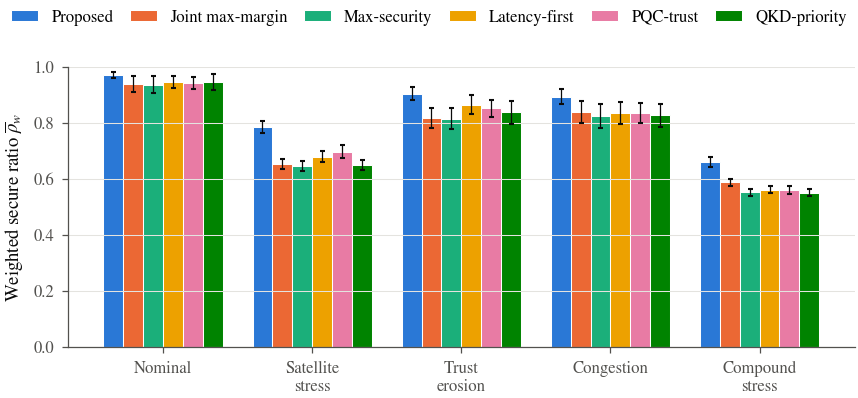

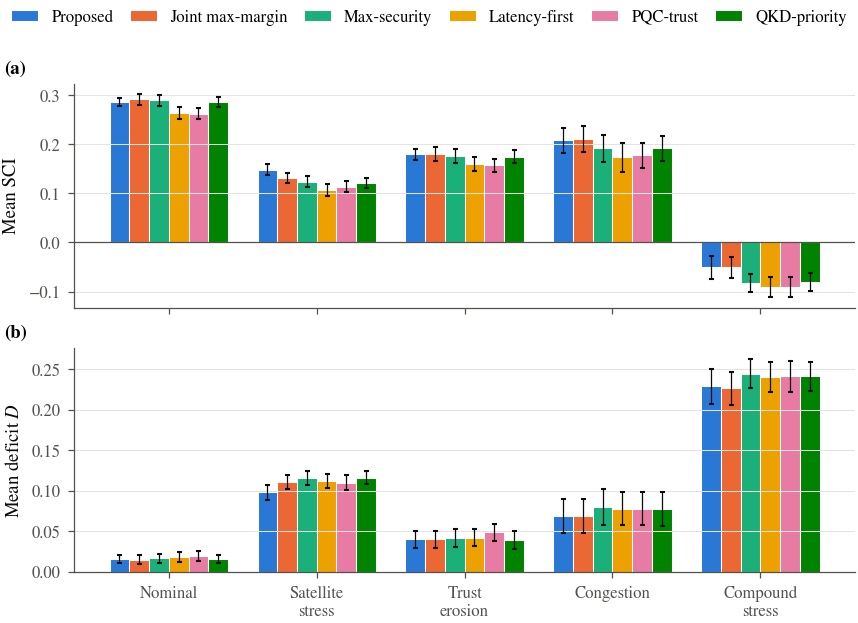

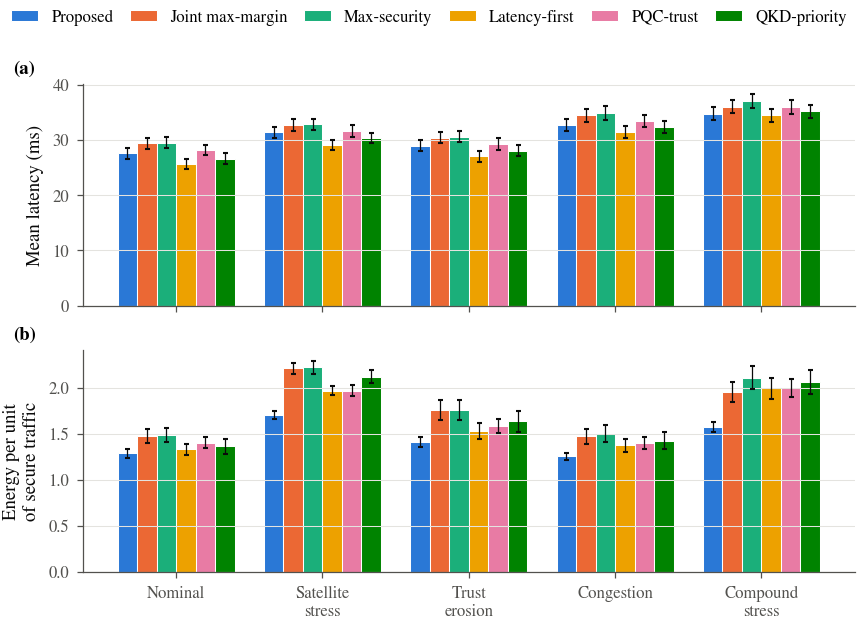

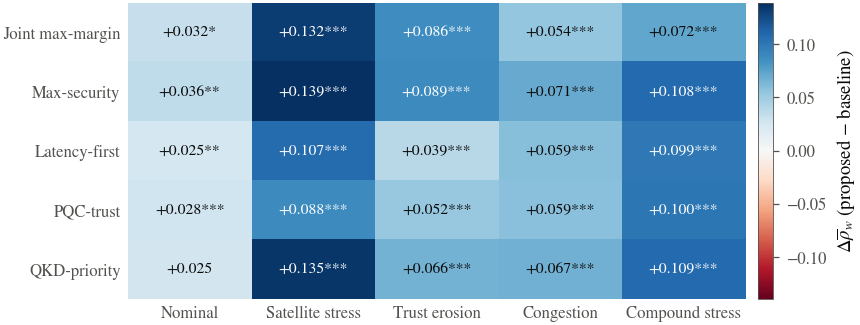

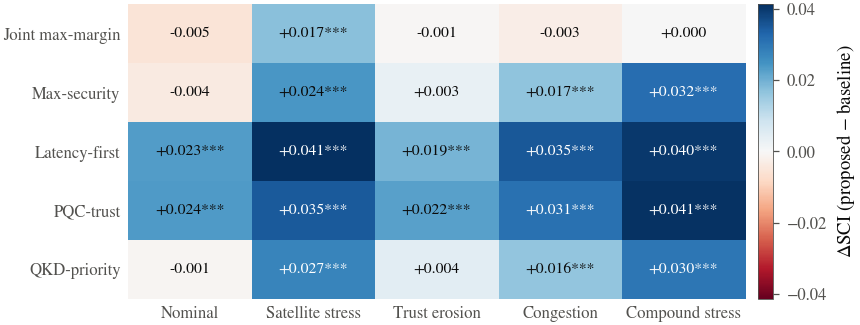

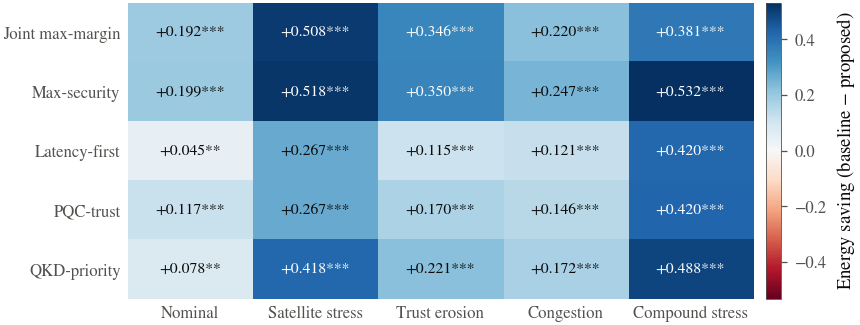

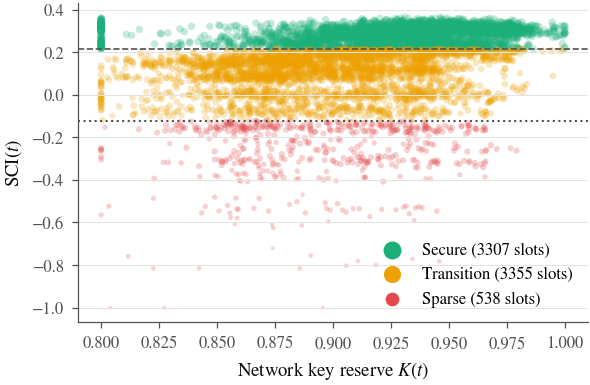

Saved scenario-sweep figures:
- fig18_secure_ratio_by_scenario_and_method.pdf
- fig18_secure_ratio_by_scenario_and_method.png
- fig19_sci_and_deficit_by_scenario_and_method.pdf
- fig19_sci_and_deficit_by_scenario_and_method.png
- fig20_latency_and_energy_by_scenario_and_method.pdf
- fig20_latency_and_energy_by_scenario_and_method.png
- fig21a_secure_ratio_advantage_heatmap.pdf
- fig21a_secure_ratio_advantage_heatmap.png
- fig21b_sci_advantage_heatmap.pdf
- fig21b_sci_advantage_heatmap.png
- fig21c_energy_advantage_heatmap.pdf
- fig21c_energy_advantage_heatmap.png
- fig22_operating_regime_diagram.pdf
- fig22_operating_regime_diagram.png


In [14]:
scenario_plot_df = scenario_method_summary.copy()
SCENARIO_LABELS = {
    "nominal": "Nominal",
    "satellite_channel_stress": "Satellite\nstress",
    "trust_erosion": "Trust\nerosion",
    "congestion_heavy": "Congestion",
    "compound_stress": "Compound\nstress",
}

def grouped_bar_ci(ax, df, value_col, ylabel, hline=None):
    x = np.arange(len(scenario_order))
    width = 0.8 / len(method_order)
    for i, m in enumerate(method_order):
        sub = df[df["method"] == m].set_index("scenario").reindex(scenario_order)
        ax.bar(x + (i - (len(method_order) - 1) / 2) * width, sub[value_col], width,
               yerr=np.vstack([sub[value_col] - sub[f"{value_col}_ci_low"], sub[f"{value_col}_ci_high"] - sub[value_col]]),
               color=METHOD_COLORS[m], edgecolor="white", linewidth=0.5,
               error_kw={"elinewidth": 0.6, "capsize": 1.2, "ecolor": INK}, label=METHOD_LABELS[m])
    if hline is not None:
        ax.axhline(hline, color=INK2, lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([SCENARIO_LABELS[s] for s in scenario_order])
    ax.set_ylabel(ylabel)

# -----------------------------
# Figure 18 — Weighted secure ratio by scenario and method
# -----------------------------
fig, ax = plt.subplots(figsize=(FULL_W, 2.5))
grouped_bar_ci(ax, scenario_plot_df, "weighted_secure_ratio", r"Weighted secure ratio $\overline{\rho}_w$")
ax.set_ylim(0, 1.0)
method_legend(fig, ax, ncol=6, y=1.06)
fig.tight_layout()
save_figure(fig, "fig18_secure_ratio_by_scenario_and_method")

# -----------------------------
# Figure 19 — SCI and deficit by scenario and method
# -----------------------------
fig, axes = plt.subplots(2, 1, figsize=(FULL_W, 4.0), sharex=True)
grouped_bar_ci(axes[0], scenario_plot_df, "SCI", "Mean SCI", hline=0.0)
grouped_bar_ci(axes[1], scenario_plot_df, "deficit", r"Mean deficit $D$")
panel_label(axes[0], "a", x=-0.09)
panel_label(axes[1], "b", x=-0.09)
method_legend(fig, axes[0], ncol=6, y=1.04)
fig.tight_layout(h_pad=0.6)
save_figure(fig, "fig19_sci_and_deficit_by_scenario_and_method")

# -----------------------------
# Figure 20 — Latency and energy by scenario and method
# -----------------------------
fig, axes = plt.subplots(2, 1, figsize=(FULL_W, 4.0), sharex=True)
grouped_bar_ci(axes[0], scenario_plot_df, "mean_latency", "Mean latency (ms)")
grouped_bar_ci(axes[1], scenario_plot_df, "energy_per_secure_unit", "Energy per unit\nof secure traffic")
panel_label(axes[0], "a", x=-0.09)
panel_label(axes[1], "b", x=-0.09)
method_legend(fig, axes[0], ncol=6, y=1.04)
fig.tight_layout(h_pad=0.6)
save_figure(fig, "fig20_latency_and_energy_by_scenario_and_method")

# -----------------------------
# Figure 21 — Advantage heatmaps of the proposed controller (proposed - baseline)
# -----------------------------
heat_specs = [
    ("weighted_secure_ratio", r"$\Delta\overline{\rho}_w$ (proposed $-$ baseline)", "fig21a_secure_ratio_advantage_heatmap", 1.0),
    ("SCI", r"$\Delta$SCI (proposed $-$ baseline)", "fig21b_sci_advantage_heatmap", 1.0),
    ("energy_per_secure_unit", r"Energy saving (baseline $-$ proposed)", "fig21c_energy_advantage_heatmap", -1.0),
]
for metric, cbar_label, fname, sign in heat_specs:
    sub = scenario_paired[scenario_paired["metric"] == metric]
    val = sub.pivot(index="baseline", columns="scenario", values="mean_difference").reindex(index=BASELINES, columns=scenario_order) * sign
    pv = sub.pivot(index="baseline", columns="scenario", values="wilcoxon_p").reindex(index=BASELINES, columns=scenario_order)
    lim = np.nanmax(np.abs(val.values)) if np.isfinite(val.values).any() else 1.0
    fig, ax = plt.subplots(figsize=(FULL_W, 2.4))
    im = ax.imshow(val.values, aspect="auto", cmap="RdBu", vmin=-lim, vmax=lim)
    ax.set_xticks(np.arange(len(scenario_order)))
    ax.set_xticklabels([SCENARIO_LABELS[s].replace("\n", " ") for s in scenario_order])
    ax.set_yticks(np.arange(len(BASELINES)))
    ax.set_yticklabels([METHOD_LABELS[b] for b in BASELINES])
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label(cbar_label)
    cb.outline.set_linewidth(0.4)
    for i in range(val.shape[0]):
        for j in range(val.shape[1]):
            p = pv.iloc[i, j]
            star = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))
            v = val.iloc[i, j]
            ax.text(j, i, f"{v:+.3f}{star}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > 0.6 * lim else INK)
    ax.grid(False)
    fig.tight_layout()
    save_figure(fig, fname)

# -----------------------------
# Figure 22 — Operating-regime diagram (proposed controller, all scenarios)
# -----------------------------
phase_df = scenario_slots[scenario_slots["method"] == "proposed"]
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.8))
for reg in ["secure", "transition", "sparse"]:
    grp = phase_df[phase_df["regime"] == reg]
    ax.scatter(grp["key_reserve"], grp["SCI"], s=3 + 10 * grp["weighted_secure_ratio"], alpha=0.25, lw=0,
               color=REGIME_COLORS[reg], label=f"{reg.capitalize()} ({len(grp)} slots)", rasterized=True)
ax.axhline(REGIME_THRESHOLDS["secure"], color=INK2, ls="--", lw=0.8)
ax.axhline(REGIME_THRESHOLDS["sparse"], color=INK2, ls=":", lw=1.0)
ax.set_xlabel("Network key reserve $K(t)$")
ax.set_ylabel(r"$\mathrm{SCI}(t)$")
leg = ax.legend(loc="lower right", markerscale=2.5)
for lh in leg.legend_handles:
    lh.set_alpha(1.0)
fig.tight_layout()
save_figure(fig, "fig22_operating_regime_diagram")

print("Saved scenario-sweep figures:")
for fig_name in sorted(os.listdir(FIG_DIR)):
    if any(fig_name.startswith(f"fig{i}") for i in range(18, 23)):
        print("-", fig_name)

## Cell 15 — Stress sweeps over QKD scarcity, congestion, trust, noise, and load

This cell varies one stress dimension at a time over six levels: QKD key-rate scarcity, link-capacity congestion, trust degradation, link noise and QBER, and traffic and key load. All methods run on the sweep seeds, and seed-level metrics, confidence intervals, and paired tests are stored for each level.

In [15]:
# -----------------------------
# One-dimensional stress sweeps
# -----------------------------
STRESS_SWEEPS = {
    "qkd_scarcity": {
        "label": "QKD key-rate factor",
        "levels": [1.00, 0.80, 0.60, 0.45, 0.30, 0.20],
        "apply": lambda v: make_scenario(qkd_space_factor=v, qkd_ground_factor=v),
    },
    "congestion": {
        "label": "Capacity factor",
        "levels": [1.00, 0.90, 0.80, 0.70, 0.60, 0.50],
        "apply": lambda v: make_scenario(capacity_space_factor=v, capacity_ground_factor=v),
    },
    "trust_degradation": {
        "label": "Trust shift",
        "levels": [0.00, -0.05, -0.10, -0.15, -0.20, -0.25],
        "apply": lambda v: make_scenario(trust_shift=v),
    },
    "link_noise": {
        "label": "Noise and QBER factor",
        "levels": [1.00, 1.20, 1.40, 1.60, 1.80, 2.00],
        "apply": lambda v: make_scenario(noise_factor=v, qber_factor=v),
    },
    "traffic_load": {
        "label": "Traffic and key demand factor",
        "levels": [0.80, 1.00, 1.20, 1.40, 1.60, 1.80],
        "apply": lambda v: make_scenario(traffic_demand_factor=v, key_demand_factor=v),
    },
}

sweep_seeds = CONFIG["sweep_seeds"]
sweep_frames = []
for dim, spec in STRESS_SWEEPS.items():
    sweep_scenarios = {f"{dim}={v}": spec["apply"](v) for v in spec["levels"]}
    d_, s_ = run_batch(sweep_seeds, sweep_scenarios, method_specs_for(METHODS))
    sm = seed_metrics(d_, s_)
    sm["dimension"] = dim
    sm["level"] = sm["scenario"].str.split("=").str[1].astype(float)
    sweep_frames.append(sm)

stress_sweep_seed_df = pd.concat(sweep_frames, ignore_index=True)
stress_sweep_summary = summarize_with_ci(stress_sweep_seed_df, ["dimension", "level", "method"], metric_cols)
stress_sweep_paired = paired_tests(
    stress_sweep_seed_df, "proposed", BASELINES,
    ["weighted_secure_ratio", "SCI", "deficit", "energy_per_secure_unit"],
    group_cols=("dimension", "level"),
)

stress_sweep_seed_df.to_csv(TAB_DIR / "stress_sweep_seed_level_metrics.csv", index=False)
stress_sweep_summary.to_csv(TAB_DIR / "stress_sweep_summary.csv", index=False)
stress_sweep_paired.to_csv(TAB_DIR / "stress_sweep_paired_tests.csv", index=False)

display(
    stress_sweep_summary.pivot_table(index=["dimension", "level"], columns="method", values="weighted_secure_ratio")
    .reindex(columns=METHODS).round(3)
)
print(f"[SAVED] {TAB_DIR / 'stress_sweep_seed_level_metrics.csv'}")
print(f"[SAVED] {TAB_DIR / 'stress_sweep_summary.csv'}")
print(f"[SAVED] {TAB_DIR / 'stress_sweep_paired_tests.csv'}")

[INFO] run_batch (reference): 20 seeds x 6 scenarios x 6 methods in 164.3s
[INFO] run_batch (reference): 20 seeds x 6 scenarios x 6 methods in 160.5s
[INFO] run_batch (reference): 20 seeds x 6 scenarios x 6 methods in 158.2s
[INFO] run_batch (reference): 20 seeds x 6 scenarios x 6 methods in 148.5s
[INFO] run_batch (reference): 20 seeds x 6 scenarios x 6 methods in 156.2s


method                   proposed  milp_max_secure  max_security  \
dimension         level                                            
congestion         0.50     0.777            0.745         0.732   
                   0.60     0.851            0.820         0.810   
                   0.70     0.917            0.893         0.890   
                   0.80     0.950            0.926         0.925   
                   0.90     0.969            0.942         0.939   
                   1.00     0.975            0.949         0.946   
link_noise         1.00     0.975            0.949         0.946   
                   1.20     0.930            0.828         0.822   
                   1.40     0.864            0.751         0.741   
                   1.60     0.798            0.688         0.683   
                   1.80     0.737            0.647         0.641   
                   2.00     0.687            0.625         0.619   
qkd_scarcity       0.20     0.719            0.614         0.605   
                   0.30     0.781            0.657         0.650   
                   0.45     0.854            0.715         0.708   
                   0.60     0.908            0.781         0.771   
                   0.80     0.949            0.875         0.872   
                   1.00     0.975            0.949         0.946   
traffic_load       0.80     0.990            0.983         0.982   
                   1.00     0.975            0.949         0.946   
                   1.20     0.928            0.861         0.847   
                   1.40     0.859            0.760         0.747   
                   1.60     0.781            0.685         0.674   
                   1.80     0.728            0.634         0.614   
trust_degradation -0.25     0.766            0.726         0.699   
                  -0.20     0.828            0.780         0.771   
                  -0.15     0.904            0.848         0.840   
                  -0.10     0.952            0.904         0.902   
                  -0.05     0.971            0.934         0.935   
                   0.00     0.975            0.949         0.946   

method                   latency_first  pqc_trust  qkd_priority  
dimension         level                                          
congestion         0.50          0.734      0.733         0.735  
                   0.60          0.810      0.809         0.813  
                   0.70          0.882      0.887         0.889  
                   0.80          0.930      0.921         0.935  
                   0.90          0.957      0.946         0.961  
                   1.00          0.960      0.952         0.963  
link_noise         1.00          0.960      0.952         0.963  
                   1.20          0.877      0.861         0.841  
                   1.40          0.793      0.791         0.749  
                   1.60          0.725      0.737         0.686  
                   1.80          0.672      0.688         0.644  
                   2.00          0.635      0.648         0.620  
qkd_scarcity       0.20          0.652      0.653         0.610  
                   0.30          0.692      0.710         0.652  
                   0.45          0.755      0.773         0.710  
                   0.60          0.823      0.833         0.785  
                   0.80          0.915      0.906         0.894  
                   1.00          0.960      0.952         0.963  
traffic_load       0.80          0.988      0.982         0.988  
                   1.00          0.960      0.952         0.963  
                   1.20          0.879      0.869         0.858  
                   1.40          0.770      0.774         0.752  
                   1.60          0.702      0.693         0.674  
                   1.80          0.635      0.633         0.615  
trust_degradation -0.25          0.737      0.735         0.724  
                  -0.20          0.812   

[SAVED] Outputs\quantum_secure_comm\tables\stress_sweep_seed_level_metrics.csv
[SAVED] Outputs\quantum_secure_comm\tables\stress_sweep_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\stress_sweep_paired_tests.csv


## Cell 16 — Stress-sweep figures

This cell plots secure service, SCI, and energy efficiency against stress severity for every method, with confidence bands.

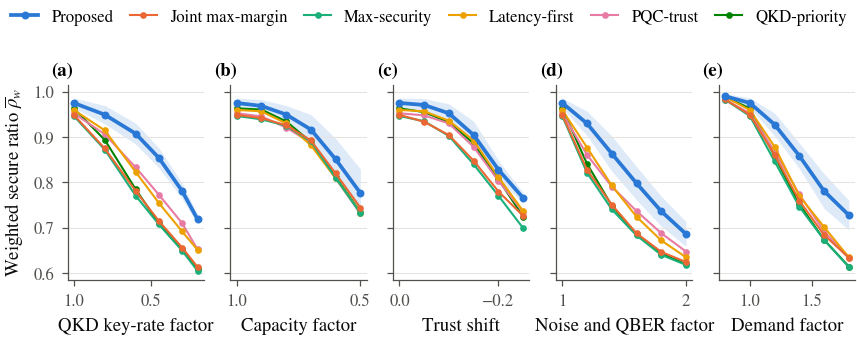

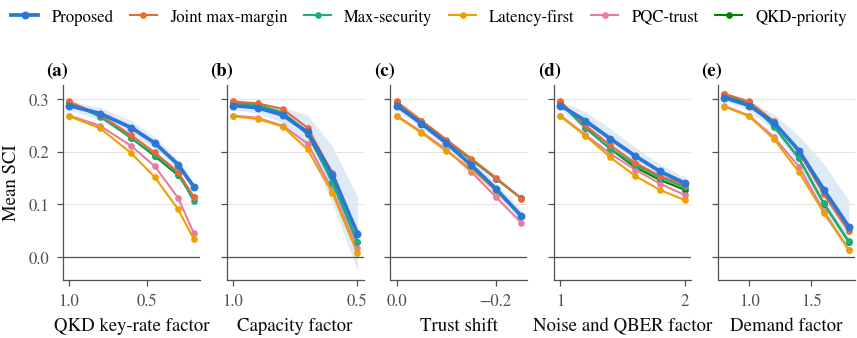

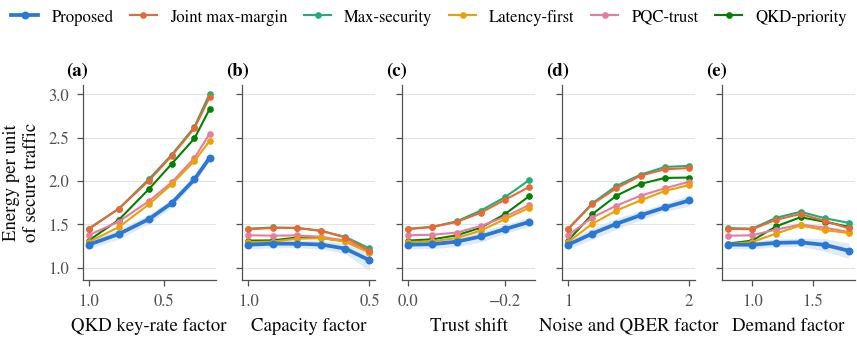

In [16]:
# -----------------------------
# Figures 23-25 — Stress-sweep robustness curves
# -----------------------------
SWEEP_AXIS_LABELS = {
    "qkd_scarcity": "QKD key-rate factor",
    "congestion": "Capacity factor",
    "trust_degradation": "Trust shift",
    "link_noise": "Noise and QBER factor",
    "traffic_load": "Demand factor",
}

def sweep_panel_figure(metric, ylabel, filename, hline=None):
    dims = list(STRESS_SWEEPS.keys())
    fig, axes = plt.subplots(1, len(dims), figsize=(FULL_W, 2.1), sharey=True)
    for ax, dim, L in zip(axes, dims, "abcde"):
        sub = stress_sweep_summary[stress_sweep_summary["dimension"] == dim]
        for m in method_order[::-1]:
            g = sub[sub["method"] == m].sort_values("level")
            ax.plot(g["level"], g[metric], color=METHOD_COLORS[m], marker="o", ms=2.2 if m != "proposed" else 2.8,
                    label=METHOD_LABELS[m], **method_style(m))
            if m == "proposed":
                ax.fill_between(g["level"], g[f"{metric}_ci_low"], g[f"{metric}_ci_high"], color=METHOD_COLORS[m], alpha=0.15, lw=0, zorder=1)
        if hline is not None:
            ax.axhline(hline, color=INK2, lw=0.6)
        if dim in ("qkd_scarcity", "congestion", "trust_degradation"):
            ax.invert_xaxis()
        ax.set_xlabel(SWEEP_AXIS_LABELS[dim])
        panel_label(ax, L, x=-0.12)
    axes[0].set_ylabel(ylabel)
    method_legend(fig, axes[0], ncol=6, y=1.10)
    fig.tight_layout(w_pad=0.4)
    save_figure(fig, filename)

sweep_panel_figure("weighted_secure_ratio", r"Weighted secure ratio $\overline{\rho}_w$", "fig23_stress_sweeps_secure_ratio")
sweep_panel_figure("SCI", "Mean SCI", "fig24_stress_sweeps_sci", hline=0.0)
sweep_panel_figure("energy_per_secure_unit", "Energy per unit\nof secure traffic", "fig25_stress_sweeps_energy")

## Cell 17 — Sensitivity analysis of controller weights and model parameters

This cell performs a one-at-a-time sensitivity analysis under moderate stress. It varies the stress-energy weights (lambda_H, lambda_R, lambda_L, lambda_E, lambda_K), the risk weights (beta), the PQC and QKD assurance levels, the trust scaling, the key-autonomy horizon, and the weight alpha of the linear combiner. For each setting it reports secure service, SCI, energy, and the fraction of flow-slot decisions that differ from the default configuration, which shows when each component changes the orchestration decision.

[INFO] run_batch (reference): 12 seeds x 1 scenarios x 1 methods in 4.1s
[INFO] sensitivity: lambda_H done
[INFO] sensitivity: lambda_R done
[INFO] sensitivity: lambda_L done
[INFO] sensitivity: lambda_E done
[INFO] sensitivity: lambda_K done
[INFO] sensitivity: beta_reliability done
[INFO] sensitivity: beta_trust_risk done
[INFO] sensitivity: beta_qber done
[INFO] sensitivity: sigma_pqc done
[INFO] sensitivity: sigma_qkd done
[INFO] sensitivity: beta_trust done
[INFO] sensitivity: autonomy_slots done
[INFO] sensitivity: alpha_linear done


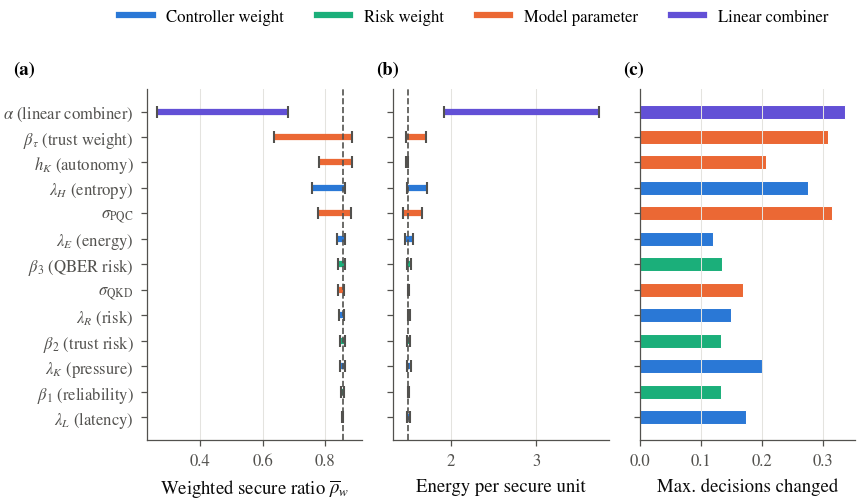

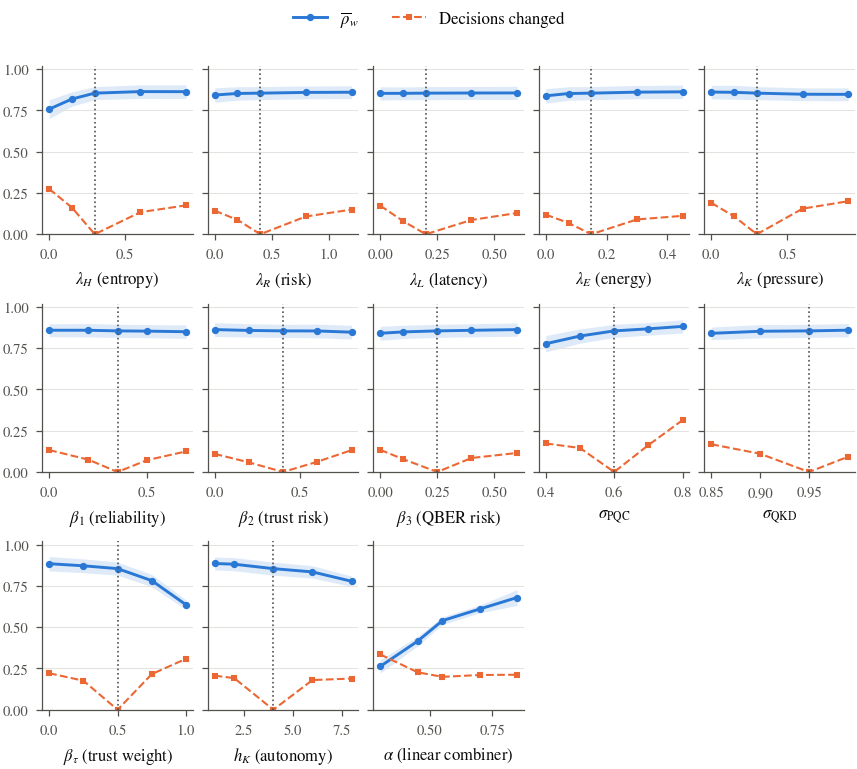

,parameter,group,secure_ratio_min,secure_ratio_max,sci_min,sci_max,energy_min,energy_max,max_decision_change,secure_ratio_range,sci_range,energy_range
0,alpha_linear,linear combiner,0.262467,0.679911,-0.237177,-0.025420,1.928246,3.733816,0.335417,0.417444,0.211757,1.805570
1,beta_trust,model parameter,0.636061,0.884741,-0.036080,0.338212,1.485196,1.710839,0.308681,0.248680,0.374293,0.225643
2,autonomy_slots,model parameter,0.778446,0.886289,0.143613,0.211113,1.475090,1.507746,0.206250,0.107843,0.067500,0.032656
3,lambda_H,controller weight,0.757801,0.864301,0.171935,0.185570,1.494886,1.725596,0.275000,0.106500,0.013635,0.230710
4,sigma_pqc,model parameter,0.777071,0.882172,0.131772,0.206602,1.446401,1.662486,0.314583,0.105101,0.074830,0.216085
5,lambda_E,controller weight,0.838542,0.862894,0.181777,0.186488,1.468265,1.559814,0.119097,0.024353,0.004711,0.091549
6,beta_qber,risk weight,0.840435,0.862753,0.183173,0.185236,1.496753,1.533011,0.134375,0.022318,0.002063,0.036257
7,sigma_qkd,model parameter,0.840129,0.859194,0.139754,0.201016,1.502433,1.518399,0.168056,0.019066,0.061262,0.015966
8,lambda_R,controller weight,0.843530,0.860420,0.184376,0.185635,1.499045,1.529152,0.149306,0.016890,0.001259,0.030107
9,beta_trust_risk,risk weight,0.847089,0.862824,0.183967,0.185438,1.492712,1.523235,0.132292,0.015735,0.001471,0.030523


[SAVED] Outputs\quantum_secure_comm\tables\sensitivity_analysis.csv
[SAVED] Outputs\quantum_secure_comm\tables\sensitivity_ranges.csv


In [17]:
# -----------------------------
# Sensitivity analysis (one-at-a-time)
# -----------------------------
SENSITIVITY_SCENARIO = {
    "moderate_stress": make_scenario(
        qkd_space_factor=0.70, qkd_ground_factor=0.90,
        capacity_space_factor=0.90, capacity_ground_factor=0.85,
        trust_shift=-0.05, noise_factor=1.15, qber_factor=1.10,
        traffic_demand_factor=1.10, key_demand_factor=1.10,
    )
}

def config_with(updates):
    P = deepcopy(CONFIG)
    for path, value in updates.items():
        node = P
        for key in path[:-1]:
            node = node[key]
        node[path[-1]] = value
    return P

def risk_weight_update(name, value):
    base = CONFIG["risk_weights"]
    others = [k for k in base if k != name]
    rest = sum(base[k] for k in others)
    upd = {("risk_weights", name): value}
    for k in others:
        upd[("risk_weights", k)] = (1.0 - value) * base[k] / rest
    return upd

SENSITIVITY_PARAMS = [
    ("lambda_H", "controller weight", [0.0, 0.15, 0.30, 0.60, 0.90], lambda v: {("stress_weights", "lambda_H"): v}),
    ("lambda_R", "controller weight", [0.0, 0.20, 0.40, 0.80, 1.20], lambda v: {("stress_weights", "lambda_R"): v}),
    ("lambda_L", "controller weight", [0.0, 0.10, 0.20, 0.40, 0.60], lambda v: {("stress_weights", "lambda_L"): v}),
    ("lambda_E", "controller weight", [0.0, 0.075, 0.15, 0.30, 0.45], lambda v: {("stress_weights", "lambda_E"): v}),
    ("lambda_K", "controller weight", [0.0, 0.15, 0.30, 0.60, 0.90], lambda v: {("stress_weights", "lambda_K"): v}),
    ("beta_reliability", "risk weight", [0.0, 0.20, 0.35, 0.50, 0.70], lambda v: risk_weight_update("reliability", v)),
    ("beta_trust_risk", "risk weight", [0.0, 0.20, 0.40, 0.60, 0.80], lambda v: risk_weight_update("trust", v)),
    ("beta_qber", "risk weight", [0.0, 0.10, 0.25, 0.40, 0.60], lambda v: risk_weight_update("qber", v)),
    ("sigma_pqc", "model parameter", [0.40, 0.50, 0.60, 0.70, 0.80], lambda v: {("security", "sigma_pqc"): v}),
    ("sigma_qkd", "model parameter", [0.85, 0.90, 0.95, 0.99], lambda v: {("security", "sigma_qkd"): v}),
    ("beta_trust", "model parameter", [0.0, 0.25, 0.50, 0.75, 1.00], lambda v: {("security", "beta_trust"): v}),
    ("autonomy_slots", "model parameter", [1.0, 2.0, 4.0, 6.0, 8.0], lambda v: {("security", "autonomy_slots"): v}),
    ("alpha_linear", "linear combiner", [0.30, 0.45, 0.55, 0.70, 0.85],
     lambda v: {("security", "combiner"): "linear", ("security", "alpha_linear"): v}),
]

DEFAULT_VALUES = {
    "lambda_H": CONFIG["stress_weights"]["lambda_H"],
    "lambda_R": CONFIG["stress_weights"]["lambda_R"],
    "lambda_L": CONFIG["stress_weights"]["lambda_L"],
    "lambda_E": CONFIG["stress_weights"]["lambda_E"],
    "lambda_K": CONFIG["stress_weights"]["lambda_K"],
    "beta_reliability": CONFIG["risk_weights"]["reliability"],
    "beta_trust_risk": CONFIG["risk_weights"]["trust"],
    "beta_qber": CONFIG["risk_weights"]["qber"],
    "sigma_pqc": CONFIG["security"]["sigma_pqc"],
    "sigma_qkd": CONFIG["security"]["sigma_qkd"],
    "beta_trust": CONFIG["security"]["beta_trust"],
    "autonomy_slots": CONFIG["security"]["autonomy_slots"],
    "alpha_linear": None,
}

sens_seeds = CONFIG["sensitivity_seeds"]
sens_default_dec, sens_default_slots = run_batch(sens_seeds, SENSITIVITY_SCENARIO, method_specs_for(["proposed"]))
default_decisions = sens_default_dec.set_index(["seed", "time", "flow_id"])[["path", "variant"]]
default_seed_metrics = seed_metrics(sens_default_dec, sens_default_slots)

def decision_change_rate(dec):
    d = dec.set_index(["seed", "time", "flow_id"])[["path", "variant"]]
    joined = d.join(default_decisions, rsuffix="_default", how="inner")
    changed = (joined["path"] != joined["path_default"]) | (joined["variant"] != joined["variant_default"])
    return float(changed.mean())

sens_rows = []
for name, group, values, updater in SENSITIVITY_PARAMS:
    for v in values:
        P_v = config_with(updater(v))
        d_, s_ = run_batch(sens_seeds, SENSITIVITY_SCENARIO, [{"label": "proposed", "method": "proposed", "P": P_v}], P=P_v, verbose=False)
        sm = seed_metrics(d_, s_)
        row = {"parameter": name, "group": group, "value": v, "is_default": DEFAULT_VALUES[name] is not None and np.isclose(v, DEFAULT_VALUES[name])}
        for m in ["weighted_secure_ratio", "SCI", "deficit", "energy_per_secure_unit", "mean_latency", "q_share", "key_reserve"]:
            mean, lo, hi = mean_ci(sm[m])
            row[m], row[f"{m}_ci_low"], row[f"{m}_ci_high"] = mean, lo, hi
        row["decision_change_rate"] = decision_change_rate(d_)
        sens_rows.append(row)
    print(f"[INFO] sensitivity: {name} done")

sensitivity_df = pd.DataFrame(sens_rows)
sensitivity_range = (
    sensitivity_df.groupby(["parameter", "group"])
    .agg(
        secure_ratio_min=("weighted_secure_ratio", "min"),
        secure_ratio_max=("weighted_secure_ratio", "max"),
        sci_min=("SCI", "min"),
        sci_max=("SCI", "max"),
        energy_min=("energy_per_secure_unit", "min"),
        energy_max=("energy_per_secure_unit", "max"),
        max_decision_change=("decision_change_rate", "max"),
    )
    .reset_index()
)
sensitivity_range["secure_ratio_range"] = sensitivity_range["secure_ratio_max"] - sensitivity_range["secure_ratio_min"]
sensitivity_range["sci_range"] = sensitivity_range["sci_max"] - sensitivity_range["sci_min"]
sensitivity_range["energy_range"] = sensitivity_range["energy_max"] - sensitivity_range["energy_min"]
sensitivity_range = sensitivity_range.sort_values("secure_ratio_range", ascending=False).reset_index(drop=True)

sensitivity_df.to_csv(TAB_DIR / "sensitivity_analysis.csv", index=False)
sensitivity_range.to_csv(TAB_DIR / "sensitivity_ranges.csv", index=False)

PARAM_LABELS = {
    "lambda_H": r"$\lambda_H$ (entropy)",
    "lambda_R": r"$\lambda_R$ (risk)",
    "lambda_L": r"$\lambda_L$ (latency)",
    "lambda_E": r"$\lambda_E$ (energy)",
    "lambda_K": r"$\lambda_K$ (pressure)",
    "beta_reliability": r"$\beta_1$ (reliability)",
    "beta_trust_risk": r"$\beta_2$ (trust risk)",
    "beta_qber": r"$\beta_3$ (QBER risk)",
    "sigma_pqc": r"$\sigma_{\mathrm{PQC}}$",
    "sigma_qkd": r"$\sigma_{\mathrm{QKD}}$",
    "beta_trust": r"$\beta_\tau$ (trust weight)",
    "autonomy_slots": r"$h_K$ (autonomy)",
    "alpha_linear": r"$\alpha$ (linear combiner)",
}
GROUP_COLORS = {"controller weight": PALETTE[0], "risk weight": PALETTE[2], "model parameter": PALETTE[1], "linear combiner": PALETTE[6]}

# -----------------------------
# Figure 26 — Sensitivity ranges and decision impact
# -----------------------------
sr = sensitivity_range.sort_values("secure_ratio_range")
fig, axes = plt.subplots(1, 3, figsize=(FULL_W, 3.2), sharey=True)
y = np.arange(len(sr))
colors = [GROUP_COLORS[g] for g in sr["group"]]
base_secure = float(default_seed_metrics["weighted_secure_ratio"].mean())
base_energy = float(default_seed_metrics["energy_per_secure_unit"].mean())
for ax, lo, hi, base, xl in [
    (axes[0], sr["secure_ratio_min"], sr["secure_ratio_max"], base_secure, r"Weighted secure ratio $\overline{\rho}_w$"),
    (axes[1], sr["energy_min"], sr["energy_max"], base_energy, "Energy per secure unit"),
]:
    ax.hlines(y, lo, hi, colors=colors, lw=3.0)
    ax.plot(lo, y, "|", color=INK2, ms=6)
    ax.plot(hi, y, "|", color=INK2, ms=6)
    ax.axvline(base, color=INK2, ls="--", lw=0.8)
    ax.set_xlabel(xl)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
axes[2].barh(y, sr["max_decision_change"], height=0.55, color=colors, edgecolor="white", linewidth=0.5)
axes[2].set_xlabel("Max. decisions changed")
axes[2].grid(axis="y", visible=False)
axes[2].grid(axis="x", visible=True)
axes[0].set_yticks(y)
axes[0].set_yticklabels([PARAM_LABELS[p] for p in sr["parameter"]])
for ax, L in zip(axes, "abc"):
    panel_label(ax, L, x=-0.08 if L != "a" else -0.62)
handles = [plt.Line2D([], [], color=c, lw=3) for c in GROUP_COLORS.values()]
fig.legend(handles, [g.capitalize() for g in GROUP_COLORS], loc="lower center", ncol=4, bbox_to_anchor=(0.55, 1.0))
fig.tight_layout(w_pad=0.8)
save_figure(fig, "fig26_sensitivity_tornado")

# -----------------------------
# Figure 27 — Sensitivity profiles
# -----------------------------
params = [p[0] for p in SENSITIVITY_PARAMS]
ncols = 5
nrows = int(np.ceil(len(params) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(FULL_W, 1.55 * nrows + 0.3), sharey=True)
for ax, name in zip(axes.flat, params):
    g = sensitivity_df[sensitivity_df["parameter"] == name].sort_values("value")
    ax.fill_between(g["value"], g["weighted_secure_ratio_ci_low"], g["weighted_secure_ratio_ci_high"], color=PALETTE[0], alpha=0.15, lw=0)
    ax.plot(g["value"], g["weighted_secure_ratio"], color=PALETTE[0], marker="o", ms=2.5, lw=1.4, label=r"$\overline{\rho}_w$")
    ax.plot(g["value"], g["decision_change_rate"], color=PALETTE[1], marker="s", ms=2.2, lw=1.0, ls="--", label="Decisions changed")
    dv = DEFAULT_VALUES[name]
    if dv is not None:
        ax.axvline(dv, color=INK2, ls=":", lw=0.8)
    ax.set_xlabel(PARAM_LABELS[name], fontsize=8)
    ax.set_ylim(0, 1.02)
    ax.tick_params(labelsize=7)
for ax in list(axes.flat)[len(params):]:
    ax.axis("off")
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(h_pad=0.6, w_pad=0.4)
save_figure(fig, "fig27_sensitivity_profiles")

display(sensitivity_range)
print(f"[SAVED] {TAB_DIR / 'sensitivity_analysis.csv'}")
print(f"[SAVED] {TAB_DIR / 'sensitivity_ranges.csv'}")

## Cell 18 — Ablation study

This cell removes one component at a time from the controller objective: the entropy term, risk term, trust signal, energy term, key-pressure term, or quantum signal. It also tests the linear combiner, forcing the QKD layer whenever available, and replacing the joint solver with sequential greedy allocation. Every variant is evaluated with the same full security model, under nominal, satellite-stress, congestion, compound-stress, and QKD-scarcity conditions, and is compared with the full model by paired tests.

[INFO] run_batch (reference): 30 seeds x 5 scenarios x 10 methods in 444.7s


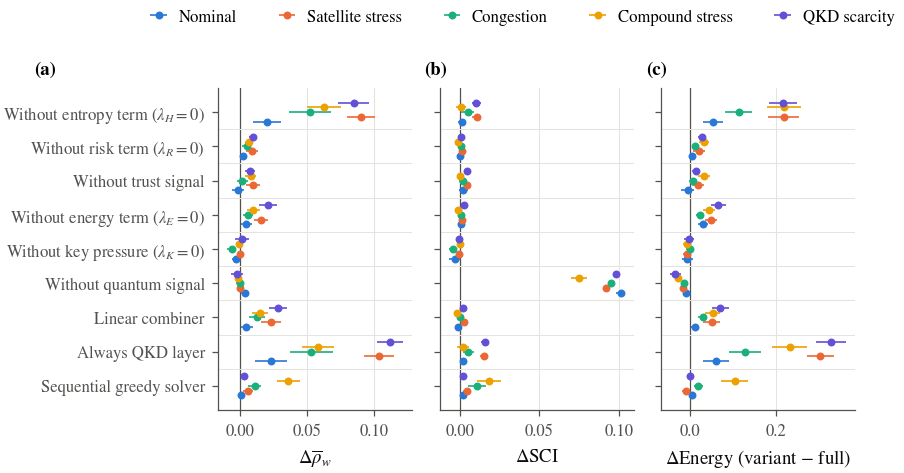

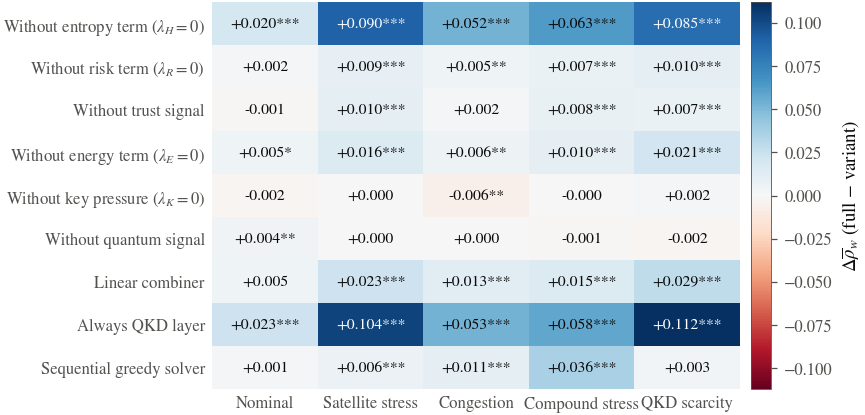

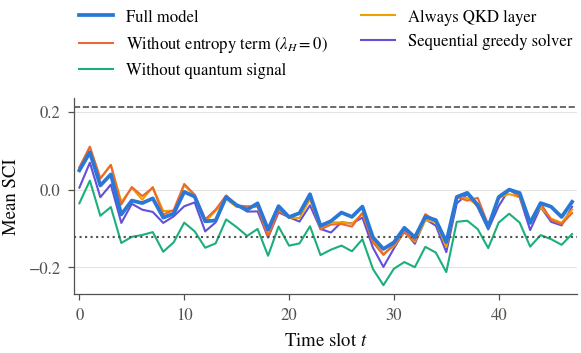

scenario,compound_stress,congestion_heavy,nominal,qkd_scarcity,satellite_channel_stress
variant,,,,,
full_model,0.6593,0.8928,0.9700,0.8463,0.7847
no_entropy_term,0.5963,0.8403,0.9499,0.7614,0.6943
no_risk_term,0.6523,0.8877,0.9677,0.8366,0.7755
no_trust_signal,0.6512,0.8909,0.9711,0.8389,0.7751
no_energy_term,0.6494,0.8869,0.9654,0.8253,0.7691
no_key_pressure,0.6597,0.8988,0.9724,0.8445,0.7844
no_quantum_signal,0.6603,0.8927,0.9663,0.8483,0.7846
linear_combiner,0.6443,0.8800,0.9651,0.8178,0.7615
always_qkd_layer,0.6012,0.8396,0.9466,0.7345,0.6810


,scenario,reference,baseline,metric,direction,n,mean_difference,ci_low,ci_high,wins,ties,losses,wilcoxon_p
0,compound_stress,full_model,no_entropy_term,weighted_secure_ratio,max,30,0.0630,0.0503,0.0757,29,1,0,0.0000
16,compound_stress,full_model,no_risk_term,weighted_secure_ratio,max,30,0.0070,0.0040,0.0101,20,9,1,0.0000
32,compound_stress,full_model,no_trust_signal,weighted_secure_ratio,max,30,0.0081,0.0042,0.0121,19,9,2,0.0002
48,compound_stress,full_model,no_energy_term,weighted_secure_ratio,max,30,0.0099,0.0050,0.0149,19,11,0,0.0000
64,compound_stress,full_model,no_key_pressure,weighted_secure_ratio,max,30,-0.0004,-0.0018,0.0011,5,20,5,0.9235
80,compound_stress,full_model,no_quantum_signal,weighted_secure_ratio,max,30,-0.0010,-0.0037,0.0016,4,16,10,0.1454
96,compound_stress,full_model,linear_combiner,weighted_secure_ratio,max,30,0.0151,0.0090,0.0211,22,8,0,0.0000
112,compound_stress,full_model,always_qkd_layer,weighted_secure_ratio,max,30,0.0582,0.0462,0.0702,29,1,0,0.0000
128,compound_stress,full_model,sequential_greedy,weighted_secure_ratio,max,30,0.0360,0.0275,0.0445,29,1,0,0.0000
144,congestion_heavy,full_model,no_entropy_term,weighted_secure_ratio,max,30,0.0525,0.0369,0.0681,27,2,1,0.0000


[SAVED] Outputs\quantum_secure_comm\tables\ablation_seed_level_metrics.csv
[SAVED] Outputs\quantum_secure_comm\tables\ablation_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\ablation_paired_tests.csv


In [18]:
# -----------------------------
# Ablation study
# Components are removed from the controller objective only; all variants are
# evaluated with the same full security model.
# -----------------------------
ABLATIONS = [
    {"label": "full_model", "method": "proposed"},
    {"label": "no_entropy_term", "method": "proposed", "ctrl": {"stress_weights": {"lambda_H": 0.0}}},
    {"label": "no_risk_term", "method": "proposed", "ctrl": {"stress_weights": {"lambda_R": 0.0}}},
    {"label": "no_trust_signal", "method": "proposed", "ctrl": {"beta_trust": 0.0, "risk_weights": {"trust": 0.0}}},
    {"label": "no_energy_term", "method": "proposed", "ctrl": {"stress_weights": {"lambda_E": 0.0}}},
    {"label": "no_key_pressure", "method": "proposed", "ctrl": {"stress_weights": {"lambda_K": 0.0}}},
    {"label": "no_quantum_signal", "method": "proposed", "ctrl": {"ignore_qkd": True}},
    {"label": "linear_combiner", "method": "proposed", "ctrl": {"combiner": "linear"}},
    {"label": "always_qkd_layer", "method": "proposed", "ctrl": {"hybrid_only": True}},
    {"label": "sequential_greedy", "method": "proposed_greedy"},
]
ABLATION_LABELS = [a["label"] for a in ABLATIONS]
ABLATION_SCENARIOS = {k: SCENARIOS[k] for k in ["nominal", "satellite_channel_stress", "congestion_heavy", "compound_stress"]}
ABLATION_SCENARIOS["qkd_scarcity"] = make_scenario(qkd_space_factor=0.45, qkd_ground_factor=0.45)

abl_dec, abl_slots = run_batch(eval_seeds, ABLATION_SCENARIOS, [dict(a, P=CONFIG) for a in ABLATIONS])
ablation_seed_df = seed_metrics(abl_dec, abl_slots)
ablation_summary = summarize_with_ci(ablation_seed_df, ["scenario", "method"], metric_cols).rename(columns={"method": "variant"})
ablation_paired = paired_tests(ablation_seed_df, "full_model", ABLATION_LABELS[1:], metric_cols, group_cols=("scenario",))

ablation_seed_df.to_csv(TAB_DIR / "ablation_seed_level_metrics.csv", index=False)
ablation_summary.to_csv(TAB_DIR / "ablation_summary.csv", index=False)
ablation_paired.to_csv(TAB_DIR / "ablation_paired_tests.csv", index=False)

ABLATION_DISPLAY = {
    "full_model": "Full model",
    "no_entropy_term": r"Without entropy term ($\lambda_H=0$)",
    "no_risk_term": r"Without risk term ($\lambda_R=0$)",
    "no_trust_signal": "Without trust signal",
    "no_energy_term": r"Without energy term ($\lambda_E=0$)",
    "no_key_pressure": r"Without key pressure ($\lambda_K=0$)",
    "no_quantum_signal": "Without quantum signal",
    "linear_combiner": "Linear combiner",
    "always_qkd_layer": "Always QKD layer",
    "sequential_greedy": "Sequential greedy solver",
}
ABL_SCEN_LABELS = {"nominal": "Nominal", "satellite_channel_stress": "Satellite stress", "congestion_heavy": "Congestion",
                   "compound_stress": "Compound stress", "qkd_scarcity": "QKD scarcity"}
abl_scen = list(ABLATION_SCENARIOS.keys())
ABL_SCEN_COLORS = dict(zip(abl_scen, [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3], PALETTE[6]]))

# -----------------------------
# Figure 28 — Ablation effect sizes (full model minus variant, 95% CI)
# -----------------------------
variants = ABLATION_LABELS[1:]
fig, axes = plt.subplots(1, 3, figsize=(FULL_W, 3.0), sharey=True)
offsets = np.linspace(-0.28, 0.28, len(abl_scen))
for ax, (metric, xl, sign), L in zip(axes, [("weighted_secure_ratio", r"$\Delta\overline{\rho}_w$", 1.0),
                                             ("SCI", r"$\Delta$SCI", 1.0),
                                             ("energy_per_secure_unit", r"$\Delta$Energy (variant $-$ full)", -1.0)], "abc"):
    y = np.arange(len(variants))[::-1]
    for k, sc in enumerate(abl_scen):
        sub = ablation_paired[(ablation_paired["metric"] == metric) & (ablation_paired["scenario"] == sc)].set_index("baseline").reindex(variants)
        mean = sign * sub["mean_difference"].values
        lo = sign * (sub["ci_low"].values if sign > 0 else sub["ci_high"].values)
        hi = sign * (sub["ci_high"].values if sign > 0 else sub["ci_low"].values)
        ax.errorbar(mean, y + offsets[k], xerr=[mean - lo, hi - mean], fmt="o", ms=2.8, color=ABL_SCEN_COLORS[sc],
                    ecolor=ABL_SCEN_COLORS[sc], elinewidth=0.8, capsize=0, label=ABL_SCEN_LABELS[sc])
    ax.axvline(0.0, color=INK2, lw=0.6)
    ax.set_xlabel(xl)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    for yy in np.arange(len(variants) - 1) + 0.5:
        ax.axhline(yy, color="#e4e3df", lw=0.5)
axes[0].set_yticks(np.arange(len(variants))[::-1])
axes[0].set_yticklabels([ABLATION_DISPLAY[v] for v in variants])
for ax, L in zip(axes, "abc"):
    panel_label(ax, L, x=-0.08 if L != "a" else -0.95)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, bbox_to_anchor=(0.6, 1.0), handletextpad=0.2)
fig.tight_layout(w_pad=0.6)
save_figure(fig, "fig28_ablation_comparison")

# -----------------------------
# Figure 29 — Ablation effect heatmap (weighted secure ratio)
# -----------------------------
eff = ablation_paired[ablation_paired["metric"] == "weighted_secure_ratio"].pivot(index="baseline", columns="scenario", values="mean_difference").reindex(index=variants, columns=abl_scen)
pv = ablation_paired[ablation_paired["metric"] == "weighted_secure_ratio"].pivot(index="baseline", columns="scenario", values="wilcoxon_p").reindex(index=variants, columns=abl_scen)
lim = np.nanmax(np.abs(eff.values)) if np.isfinite(eff.values).any() else 1.0
fig, ax = plt.subplots(figsize=(FULL_W, 3.0))
im = ax.imshow(eff.values, aspect="auto", cmap="RdBu", vmin=-lim, vmax=lim)
ax.set_xticks(np.arange(len(abl_scen)))
ax.set_xticklabels([ABL_SCEN_LABELS[s] for s in abl_scen])
ax.set_yticks(np.arange(len(variants)))
ax.set_yticklabels([ABLATION_DISPLAY[v] for v in variants])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(eff.shape[0]):
    for j in range(eff.shape[1]):
        p = pv.iloc[i, j]
        star = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))
        v = eff.iloc[i, j]
        ax.text(j, i, f"{v:+.3f}{star}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 * lim else INK)
cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label(r"$\Delta\overline{\rho}_w$ (full $-$ variant)")
cb.outline.set_linewidth(0.4)
ax.grid(False)
fig.tight_layout()
save_figure(fig, "fig29_ablation_effect_heatmap")

# -----------------------------
# Figure 30 — SCI over time under selected ablation variants (compound stress)
# -----------------------------
abl_time = summarize_with_ci(abl_slots[abl_slots["scenario"] == "compound_stress"], ["method", "time"], ["SCI"])
shown = ["full_model", "no_entropy_term", "no_quantum_signal", "always_qkd_layer", "sequential_greedy"]
shown_colors = dict(zip(shown, [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3], PALETTE[6]]))
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.6))
for lab in shown[::-1]:
    g = abl_time[abl_time["method"] == lab].sort_values("time")
    ax.plot(g["time"], g["SCI"], color=shown_colors[lab], lw=1.8 if lab == "full_model" else 1.0,
            zorder=5 if lab == "full_model" else 2, label=ABLATION_DISPLAY[lab])
ax.axhline(REGIME_THRESHOLDS["secure"], color=INK2, ls="--", lw=0.8)
ax.axhline(REGIME_THRESHOLDS["sparse"], color=INK2, ls=":", lw=1.0)
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Mean SCI")
ax.set_xlim(-0.5, CONFIG["time_horizon"] - 0.5)
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)
fig.tight_layout()
save_figure(fig, "fig30_sci_over_time_ablation")

display(ablation_summary.pivot_table(index="variant", columns="scenario", values="weighted_secure_ratio").reindex(ABLATION_LABELS).round(4))
display(ablation_paired[ablation_paired["metric"] == "weighted_secure_ratio"].round(4))
print(f"[SAVED] {TAB_DIR / 'ablation_seed_level_metrics.csv'}")
print(f"[SAVED] {TAB_DIR / 'ablation_summary.csv'}")
print(f"[SAVED] {TAB_DIR / 'ablation_paired_tests.csv'}")

## Cell 19 — Prospective evaluation of SCI as an early-warning indicator

This cell tests whether the indicators anticipate secure-service failure. For every slot in which the system has not failed, each indicator at time t is used to predict failure at t + k for k = 1 to 5. Thresholds and logistic models are fitted on calibration seeds and evaluated on held-out seeds. Reported metrics are ROC-AUC with cluster-bootstrap confidence intervals, PR-AUC, precision, recall, F1, and false-alarm rate. The indicators are compared with persistence, QBER, link-availability, and observable-only baselines. The cell also measures the warning lead time of threshold alarms and the sensitivity of the free-energy indicator to its temperature.

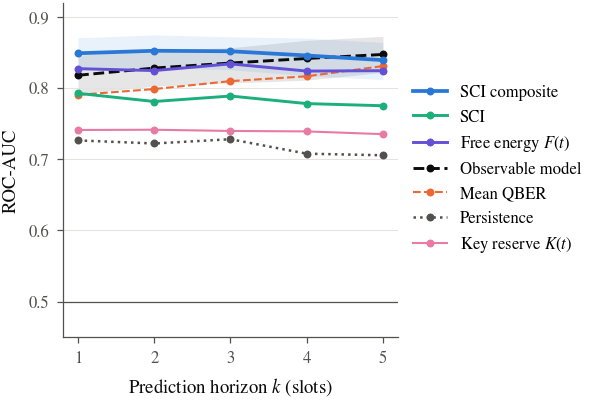

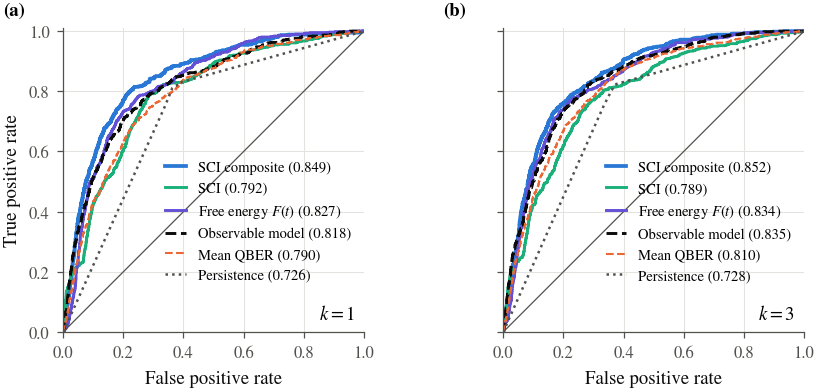

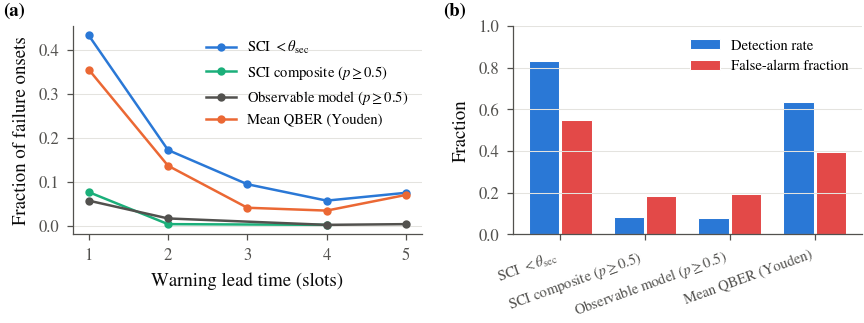

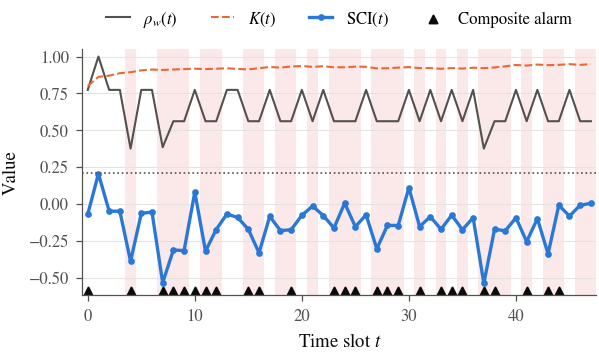

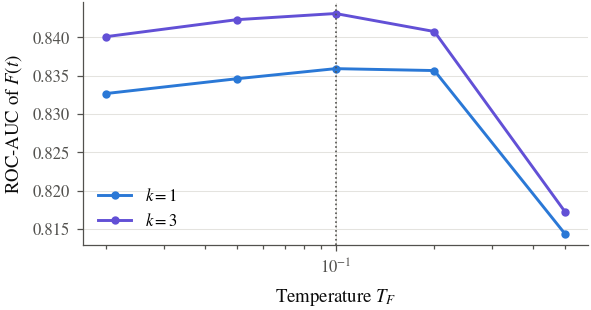

horizon,1,2,3,4,5
predictor,,,,,
SCI_composite,0.849,0.852,0.852,0.846,0.839
SCI,0.792,0.781,0.789,0.778,0.775
free_energy,0.827,0.824,0.834,0.824,0.824
key_reserve,0.741,0.741,0.740,0.739,0.735
deficit,0.760,0.753,0.762,0.741,0.744
observable_baseline,0.818,0.828,0.835,0.841,0.847
persistence,0.726,0.722,0.728,0.708,0.705
mean_qber,0.790,0.798,0.810,0.816,0.831
link_unavailability,0.636,0.605,0.629,0.600,0.626


,alarm_rule,failure_onsets,detected_onsets,detection_rate,mean_lead_time,median_lead_time,alarm_steps,false_alarm_fraction
0,SCI below secure threshold,616,512,0.831169,1.998047,1.0,2668,0.550600
1,SCI_composite (p >= 0.5),616,50,0.081169,1.100000,1.0,120,0.183333
2,observable_baseline (p >= 0.5),616,48,0.077922,1.437500,1.0,113,0.194690
3,mean_qber (Youden),616,392,0.636364,1.941327,1.0,1503,0.394544


,temperature,horizon,free_energy_auc,mean_effective_alternatives
0,0.02,1,0.832667,2.256593
1,0.02,3,0.840092,2.256593
2,0.05,1,0.834598,3.358836
3,0.05,3,0.842311,3.358836
4,0.10,1,0.835918,4.172360
5,0.10,3,0.843115,4.172360
6,0.20,1,0.835667,4.766264
7,0.20,3,0.840763,4.766264
8,0.50,1,0.814339,5.314350
9,0.50,3,0.817224,5.314350


[SAVED] Outputs\quantum_secure_comm\tables\prediction_evaluation.csv
[SAVED] Outputs\quantum_secure_comm\tables\prediction_evaluation_all_methods.csv
[SAVED] Outputs\quantum_secure_comm\tables\prediction_lead_time.csv
[SAVED] Outputs\quantum_secure_comm\tables\prediction_temperature_sensitivity.csv


In [19]:
# -----------------------------
# Prospective evaluation of SCI as an early-warning indicator
# Failure: priority-weighted secure ratio below the failure level.
# Task: at time t (system not failed), predict failure at t + k.
# Calibration seeds fit thresholds and models; evaluation seeds are held out.
# -----------------------------
horizons = CONFIG["prediction"]["horizons"]
test_df = add_failure_labels(scenario_slots[scenario_slots["method"] == "proposed"].drop(columns=["regime"]))
test_all_methods = add_failure_labels(scenario_slots.drop(columns=["regime"]))

SINGLE_PREDICTORS = {
    "SCI": lambda d: -d["SCI"].values,
    "free_energy": lambda d: d["free_energy"].values,
    "key_reserve": lambda d: -d["key_reserve"].values,
    "deficit": lambda d: d["deficit"].values,
    "persistence": lambda d: 1.0 - d["weighted_secure_ratio"].values,
    "mean_qber": lambda d: d["mean_qber"].values,
    "link_unavailability": lambda d: 1.0 - d["link_availability"].values,
}
COMPOSITE_FEATURES = {
    "SCI_composite": ["SCI", "SCI_delta", "free_energy", "free_energy_delta", "key_reserve", "key_reserve_delta"],
    "observable_baseline": ["mean_qber", "link_availability", "weighted_secure_ratio"],
}
PREDICTOR_ORDER = ["SCI_composite", "SCI", "free_energy", "key_reserve", "deficit", "observable_baseline", "persistence", "mean_qber", "link_unavailability"]

def onset_rows(df, k):
    return df[(df["fail"] == 0) & df[f"fail_t{k}"].notna()]

def youden_threshold(scores, labels):
    fpr, tpr = roc_curve_points(scores, labels)
    thr = np.concatenate([[np.inf], np.unique(scores)[::-1]])
    j = np.argmax(tpr - fpr)
    return float(thr[min(j, len(thr) - 1)])

def predictor_scores(name, df, models):
    if name in SINGLE_PREDICTORS:
        return SINGLE_PREDICTORS[name](df)
    return predict_logistic(models[name], df[COMPOSITE_FEATURES[name]].values)

def cluster_bootstrap_auc(df, scores, labels, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    keys = (df["scenario"].astype(str) + "|" + df["seed"].astype(str)).values
    uniq = np.unique(keys)
    idx_by_key = {k_: np.flatnonzero(keys == k_) for k_ in uniq}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([idx_by_key[p] for p in pick])
        a = roc_auc(scores[idx], labels[idx])
        if np.isfinite(a):
            vals.append(a)
    if not vals:
        return np.nan, np.nan
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

prediction_rows = []
roc_store = {}
for k in horizons:
    cal_k = onset_rows(calib_df, k)
    tst_k = onset_rows(test_df, k)
    y_cal = cal_k[f"fail_t{k}"].values.astype(int)
    y_tst = tst_k[f"fail_t{k}"].values.astype(int)
    models = {name: fit_logistic(cal_k[feats].values, y_cal) for name, feats in COMPOSITE_FEATURES.items()}
    for name in PREDICTOR_ORDER:
        s_cal = predictor_scores(name, cal_k, models)
        s_tst = predictor_scores(name, tst_k, models)
        thr = youden_threshold(s_cal, y_cal)
        pred = s_tst >= thr
        tp = int((pred & (y_tst == 1)).sum())
        fp = int((pred & (y_tst == 0)).sum())
        fn = int((~pred & (y_tst == 1)).sum())
        tn = int((~pred & (y_tst == 0)).sum())
        precision = tp / max(tp + fp, 1)
        recall = tp / max(tp + fn, 1)
        lo, hi = cluster_bootstrap_auc(tst_k, s_tst, y_tst, seed=k)
        prediction_rows.append({
            "horizon": k,
            "predictor": name,
            "n_test": len(y_tst),
            "positive_rate": float(y_tst.mean()),
            "roc_auc": roc_auc(s_tst, y_tst),
            "roc_auc_ci_low": lo,
            "roc_auc_ci_high": hi,
            "pr_auc": average_precision(s_tst, y_tst),
            "threshold": thr,
            "precision": precision,
            "recall": recall,
            "f1": 2 * precision * recall / max(precision + recall, 1e-12),
            "false_alarm_rate": fp / max(fp + tn, 1),
        })
        if k in (1, 3):
            roc_store[(k, name)] = roc_curve_points(s_tst, y_tst)

prediction_df = pd.DataFrame(prediction_rows)

# -----------------------------
# Robustness: all allocation methods pooled
# -----------------------------
pooled_rows = []
for k in horizons:
    cal_k = onset_rows(calib_df, k)
    y_cal = cal_k[f"fail_t{k}"].values.astype(int)
    models = {name: fit_logistic(cal_k[feats].values, y_cal) for name, feats in COMPOSITE_FEATURES.items()}
    tst_k = onset_rows(test_all_methods, k)
    y_tst = tst_k[f"fail_t{k}"].values.astype(int)
    for name in PREDICTOR_ORDER:
        pooled_rows.append({"horizon": k, "predictor": name, "roc_auc": roc_auc(predictor_scores(name, tst_k, models), y_tst),
                            "pr_auc": average_precision(predictor_scores(name, tst_k, models), y_tst), "n_test": len(y_tst)})
prediction_pooled_df = pd.DataFrame(pooled_rows)

# -----------------------------
# Warning lead time of threshold alarms
# Alarm rules use thresholds fitted on calibration seeds.
# -----------------------------
W = CONFIG["prediction"]["max_lead_window"]
cal_1 = onset_rows(calib_df, 1)
models_1 = {name: fit_logistic(cal_1[feats].values, cal_1["fail_t1"].values.astype(int)) for name, feats in COMPOSITE_FEATURES.items()}
qber_alarm_threshold = youden_threshold(cal_1["mean_qber"].values, cal_1["fail_t1"].values)
ALARM_RULES = {
    "SCI below secure threshold": lambda d: d["SCI"].values < REGIME_THRESHOLDS["secure"],
    "SCI_composite (p >= 0.5)": lambda d: predict_logistic(models_1["SCI_composite"], d[COMPOSITE_FEATURES["SCI_composite"]].values) >= 0.5,
    "observable_baseline (p >= 0.5)": lambda d: predict_logistic(models_1["observable_baseline"], d[COMPOSITE_FEATURES["observable_baseline"]].values) >= 0.5,
    "mean_qber (Youden)": lambda d: d["mean_qber"].values >= qber_alarm_threshold,
}

lead_rows = []
for rule, fn in ALARM_RULES.items():
    leads, detected, n_events, false_alarms, alarm_steps = [], 0, 0, 0, 0
    for _, g in test_df.groupby(["scenario", "seed"]):
        g = g.sort_values("time")
        alarm = fn(g)
        fail = g["fail"].values
        for t_ in range(1, len(g)):
            if fail[t_] == 1 and fail[t_ - 1] == 0:
                n_events += 1
                lead = 0
                while lead < W and t_ - 1 - lead >= 0 and alarm[t_ - 1 - lead] and fail[t_ - 1 - lead] == 0:
                    lead += 1
                if lead > 0:
                    detected += 1
                    leads.append(lead)
        for t_ in range(len(g)):
            if fail[t_] == 0 and alarm[t_]:
                alarm_steps += 1
                if not np.any(fail[t_ + 1:t_ + 1 + W] == 1):
                    false_alarms += 1
    lead_rows.append({
        "alarm_rule": rule,
        "failure_onsets": n_events,
        "detected_onsets": detected,
        "detection_rate": detected / max(n_events, 1),
        "mean_lead_time": float(np.mean(leads)) if leads else 0.0,
        "median_lead_time": float(np.median(leads)) if leads else 0.0,
        "alarm_steps": alarm_steps,
        "false_alarm_fraction": false_alarms / max(alarm_steps, 1),
        "lead_times": leads,
    })
lead_time_df = pd.DataFrame(lead_rows)

# -----------------------------
# Free-energy temperature sensitivity (indicator only; decisions do not depend on T)
# -----------------------------
temp_rows = []
temp_seeds = eval_seeds[:10]
for T_val in [0.02, 0.05, 0.10, 0.20, 0.50]:
    P_T = config_with({("temperature",): T_val})
    _, s_T = run_batch(temp_seeds, SCENARIOS, [{"label": "proposed", "method": "proposed", "P": P_T}], P=P_T, verbose=False)
    lab_T = add_failure_labels(s_T)
    for k in [1, 3]:
        r = onset_rows(lab_T, k)
        temp_rows.append({"temperature": T_val, "horizon": k, "free_energy_auc": roc_auc(r["free_energy"].values, r[f"fail_t{k}"].values),
                          "mean_effective_alternatives": float(s_T["effective_alternatives"].mean())})
temperature_df = pd.DataFrame(temp_rows)

prediction_df.to_csv(TAB_DIR / "prediction_evaluation.csv", index=False)
prediction_pooled_df.to_csv(TAB_DIR / "prediction_evaluation_all_methods.csv", index=False)
lead_time_df.drop(columns=["lead_times"]).to_csv(TAB_DIR / "prediction_lead_time.csv", index=False)
temperature_df.to_csv(TAB_DIR / "prediction_temperature_sensitivity.csv", index=False)

PRED_LABELS = {
    "SCI_composite": "SCI composite",
    "SCI": "SCI",
    "free_energy": "Free energy $F(t)$",
    "key_reserve": "Key reserve $K(t)$",
    "deficit": "Deficit $D(t)$",
    "observable_baseline": "Observable model",
    "persistence": "Persistence",
    "mean_qber": "Mean QBER",
    "link_unavailability": "Link unavailability",
}
PRED_STYLE = {
    "SCI_composite": (PALETTE[0], "-", 1.8),
    "SCI": (PALETTE[2], "-", 1.4),
    "free_energy": (PALETTE[6], "-", 1.4),
    "key_reserve": (PALETTE[4], "-", 1.0),
    "deficit": (PALETTE[5], "-", 1.0),
    "observable_baseline": (INK, "--", 1.4),
    "persistence": (INK2, ":", 1.2),
    "mean_qber": (PALETTE[1], "--", 1.0),
    "link_unavailability": (PALETTE[3], ":", 1.0),
}

# -----------------------------
# Figure 31 — ROC-AUC versus prediction horizon
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.9))
shown_pred = ["SCI_composite", "SCI", "free_energy", "observable_baseline", "mean_qber", "persistence", "key_reserve"]
for name in shown_pred[::-1]:
    g = prediction_df[prediction_df["predictor"] == name].sort_values("horizon")
    c, ls, lw = PRED_STYLE[name]
    ax.plot(g["horizon"], g["roc_auc"], color=c, ls=ls, lw=lw, marker="o", ms=2.8, label=PRED_LABELS[name])
    if name in ("SCI_composite", "observable_baseline"):
        ax.fill_between(g["horizon"], g["roc_auc_ci_low"], g["roc_auc_ci_high"], color=c, alpha=0.10, lw=0)
ax.axhline(0.5, color=INK2, lw=0.6)
ax.set_xticks(horizons)
ax.set_xlabel("Prediction horizon $k$ (slots)")
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0.45, 0.92)
h, l = ax.get_legend_handles_labels()
ax.legend(h[::-1], l[::-1], loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
save_figure(fig, "fig31_prediction_auc_vs_horizon")

# -----------------------------
# Figure 32 — ROC curves at k = 1 and k = 3
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.8), sharey=True)
for ax, k, L in zip(axes, [1, 3], "ab"):
    for name in ["SCI_composite", "SCI", "free_energy", "observable_baseline", "mean_qber", "persistence"]:
        fpr, tpr = roc_store[(k, name)]
        auc = prediction_df[(prediction_df["horizon"] == k) & (prediction_df["predictor"] == name)]["roc_auc"].iloc[0]
        c, ls, lw = PRED_STYLE[name]
        ax.plot(fpr, tpr, color=c, ls=ls, lw=lw, label=f"{PRED_LABELS[name]} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6)
    ax.set_xlabel("False positive rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
    ax.set_aspect("equal")
    ax.grid(axis="x", visible=True)
    ax.text(0.97, 0.03, f"$k={k}$", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.12), fontsize=7, handlelength=1.4)
    panel_label(ax, L, x=-0.2)
axes[0].set_ylabel("True positive rate")
fig.tight_layout(w_pad=1.5)
save_figure(fig, "fig32_prediction_roc_curves")

# -----------------------------
# Figure 33 — Warning lead time and false alarms
# -----------------------------
RULE_LABELS = {
    "SCI below secure threshold": r"SCI $<\theta_{\mathrm{sec}}$",
    "SCI_composite (p >= 0.5)": r"SCI composite ($p\geq0.5$)",
    "observable_baseline (p >= 0.5)": r"Observable model ($p\geq0.5$)",
    "mean_qber (Youden)": "Mean QBER (Youden)",
}
RULE_COLORS = dict(zip(RULE_LABELS, [PALETTE[0], PALETTE[2], INK2, PALETTE[1]]))
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.4))
for rule_row in lead_rows:
    if rule_row["lead_times"]:
        vals, counts = np.unique(rule_row["lead_times"], return_counts=True)
        axes[0].plot(vals, counts / max(rule_row["failure_onsets"], 1), marker="o", ms=3, lw=1.2,
                     color=RULE_COLORS[rule_row["alarm_rule"]], label=RULE_LABELS[rule_row["alarm_rule"]])
axes[0].set_xlabel("Warning lead time (slots)")
axes[0].set_ylabel("Fraction of failure onsets")
axes[0].set_xticks(range(1, W + 1))
axes[0].legend(loc="upper right", fontsize=7)
x = np.arange(len(lead_time_df))
axes[1].bar(x - 0.19, lead_time_df["detection_rate"], 0.36, color=PALETTE[0], edgecolor="white", linewidth=0.5, label="Detection rate")
axes[1].bar(x + 0.19, lead_time_df["false_alarm_fraction"], 0.36, color=PALETTE[7], edgecolor="white", linewidth=0.5, label="False-alarm fraction")
axes[1].set_xticks(x)
axes[1].set_xticklabels([RULE_LABELS[r] for r in lead_time_df["alarm_rule"]], rotation=20, ha="right", fontsize=7)
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel("Fraction")
axes[1].legend(loc="upper right", fontsize=7)
panel_label(axes[0], "a", x=-0.2)
panel_label(axes[1], "b", x=-0.2)
fig.tight_layout(w_pad=1.5)
save_figure(fig, "fig33_prediction_lead_time")

# -----------------------------
# Figure 34 — Example indicator trace
# -----------------------------
onset_counts = test_df.assign(onset=(test_df["fail"].diff() == 1)).groupby(["scenario", "seed"])["onset"].sum()
ex_scenario, ex_seed = onset_counts.idxmax()
ex = test_df[(test_df["scenario"] == ex_scenario) & (test_df["seed"] == ex_seed)].sort_values("time")
ex_alarm = ALARM_RULES["SCI_composite (p >= 0.5)"](ex)
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.6))
for t_, f_ in zip(ex["time"], ex["fail"]):
    if f_:
        ax.axvspan(t_ - 0.5, t_ + 0.5, color=PALETTE[7], alpha=0.12, linewidth=0)
ax.plot(ex["time"], ex["weighted_secure_ratio"], color=INK2, lw=1.0, label=r"$\rho_w(t)$")
ax.plot(ex["time"], ex["key_reserve"], color=PALETTE[1], lw=1.0, ls="--", label="$K(t)$")
ax.plot(ex["time"], ex["SCI"], color=PALETTE[0], lw=1.6, marker="o", ms=2.2, label=r"$\mathrm{SCI}(t)$")
ymin = min(ex["SCI"].min(), 0) - 0.08
ax.scatter(ex["time"][ex_alarm], np.full(int(ex_alarm.sum()), ymin + 0.03), marker="^", s=14, color=INK, label="Composite alarm")
ax.axhline(REGIME_THRESHOLDS["secure"], color=INK2, ls=":", lw=0.8)
ax.set_ylim(ymin, 1.05)
ax.set_xlim(-0.5, CONFIG["time_horizon"] - 0.5)
ax.set_xlabel("Time slot $t$")
ax.set_ylabel("Value")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=4, handlelength=1.4)
fig.tight_layout()
save_figure(fig, "fig34_prediction_example_trace")

# -----------------------------
# Figure 35 — Free-energy temperature sensitivity
# -----------------------------
fig, ax = plt.subplots(figsize=(SINGLE_W, 2.3))
for k, c in zip([1, 3], [PALETTE[0], PALETTE[6]]):
    g = temperature_df[temperature_df["horizon"] == k]
    ax.plot(g["temperature"], g["free_energy_auc"], color=c, marker="o", ms=3, lw=1.4, label=f"$k={k}$")
ax.set_xscale("log")
ax.axvline(CONFIG["temperature"], color=INK2, ls=":", lw=0.8)
ax.set_xlabel("Temperature $T_F$")
ax.set_ylabel("ROC-AUC of $F(t)$")
ax.grid(axis="x", visible=True)
ax.legend(loc="lower left")
fig.tight_layout()
save_figure(fig, "fig35_free_energy_temperature_sensitivity")

display(prediction_df.pivot_table(index="predictor", columns="horizon", values="roc_auc").reindex(PREDICTOR_ORDER).round(3))
display(lead_time_df.drop(columns=["lead_times"]))
display(temperature_df)
for name in ["prediction_evaluation", "prediction_evaluation_all_methods", "prediction_lead_time", "prediction_temperature_sensitivity"]:
    print(f"[SAVED] {TAB_DIR / (name + '.csv')}")

## Cell 20 — Energy-aware orchestration tradeoff

This cell sweeps the energy weight lambda_E of the stress energy and reports the resulting tradeoff between the energy consumed per unit of secure traffic and the secure-service ratio, alongside the baseline methods.

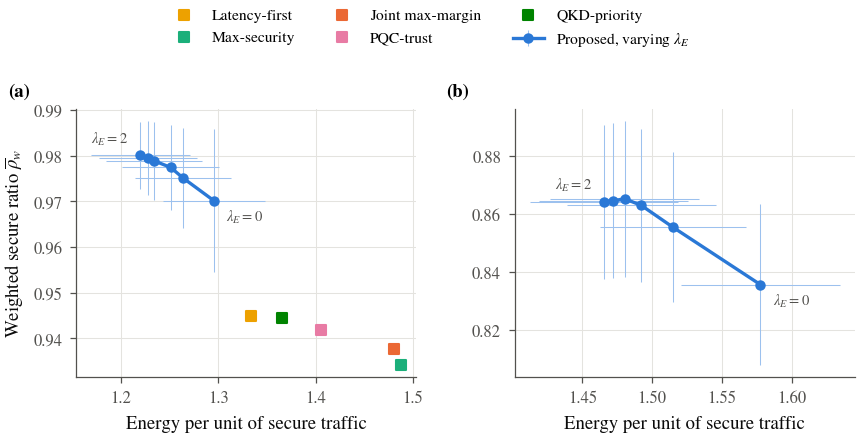

,scenario,lambda_E,weighted_secure_ratio,energy_per_secure_unit,q_share,mean_latency
0,moderate_stress,0.00,0.8357,1.5775,0.8896,28.2671
1,moderate_stress,0.15,0.8555,1.5151,0.8902,28.0657
2,moderate_stress,0.30,0.8631,1.4922,0.8906,27.9514
3,moderate_stress,0.60,0.8654,1.4802,0.8912,27.8610
4,moderate_stress,1.00,0.8646,1.4722,0.8904,27.7590
5,moderate_stress,2.00,0.8643,1.4656,0.8899,27.6698
6,nominal,0.00,0.9702,1.2956,0.9861,27.8502
7,nominal,0.15,0.9751,1.2640,0.9851,27.5300
8,nominal,0.30,0.9774,1.2514,0.9859,27.3877
9,nominal,0.60,0.9788,1.2345,0.9870,27.2465


[SAVED] Outputs\quantum_secure_comm\tables\energy_tradeoff_seed_level_metrics.csv
[SAVED] Outputs\quantum_secure_comm\tables\energy_tradeoff_summary.csv


In [20]:
# -----------------------------
# Energy-aware orchestration: energy-security tradeoff
# -----------------------------
energy_lambdas = [0.0, 0.15, 0.30, 0.60, 1.00, 2.00]
energy_scenarios = {"nominal": SCENARIOS["nominal"], "moderate_stress": SENSITIVITY_SCENARIO["moderate_stress"]}
energy_rows = []
energy_frames = []
for lam in energy_lambdas:
    P_E = config_with({("stress_weights", "lambda_E"): lam})
    d_, s_ = run_batch(sweep_seeds, energy_scenarios, [{"label": f"lambda_E={lam}", "method": "proposed", "P": P_E}], P=P_E, verbose=False)
    sm = seed_metrics(d_, s_)
    sm["lambda_E"] = lam
    energy_frames.append(sm)
energy_seed_df = pd.concat(energy_frames, ignore_index=True)
energy_tradeoff = summarize_with_ci(
    energy_seed_df, ["scenario", "lambda_E"],
    ["weighted_secure_ratio", "SCI", "energy_per_secure_unit", "mean_latency", "q_share", "key_per_secure_unit"],
)

reference_points = scenario_method_summary[scenario_method_summary["scenario"].isin(["nominal"])][
    ["scenario", "method", "weighted_secure_ratio", "energy_per_secure_unit"]
]

energy_seed_df.to_csv(TAB_DIR / "energy_tradeoff_seed_level_metrics.csv", index=False)
energy_tradeoff.to_csv(TAB_DIR / "energy_tradeoff_summary.csv", index=False)

# -----------------------------
# Figure 36 — Energy-security tradeoff
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.6))
for ax, sc, L in zip(axes, ["nominal", "moderate_stress"], "ab"):
    g = energy_tradeoff[energy_tradeoff["scenario"] == sc].sort_values("lambda_E")
    ax.errorbar(g["energy_per_secure_unit"], g["weighted_secure_ratio"],
                xerr=np.vstack([g["energy_per_secure_unit"] - g["energy_per_secure_unit_ci_low"], g["energy_per_secure_unit_ci_high"] - g["energy_per_secure_unit"]]),
                yerr=np.vstack([g["weighted_secure_ratio"] - g["weighted_secure_ratio_ci_low"], g["weighted_secure_ratio_ci_high"] - g["weighted_secure_ratio"]]),
                marker="o", ms=4, lw=1.6, elinewidth=0.5, capsize=0, color=METHOD_COLORS["proposed"], ecolor="#9cc1ee",
                label=r"Proposed, varying $\lambda_E$")
    for (_, r), off, ha in zip(g.iloc[[0, -1]].iterrows(), [(6, -10), (-6, 6)], ["left", "right"]):
        ax.annotate(rf"$\lambda_E={r['lambda_E']:g}$", (r["energy_per_secure_unit"], r["weighted_secure_ratio"]), textcoords="offset points",
                    xytext=off, ha=ha, fontsize=7, color=INK2)
    if sc == "nominal":
        for _, r in reference_points.iterrows():
            if r["method"] != "proposed":
                ax.scatter(r["energy_per_secure_unit"], r["weighted_secure_ratio"], marker="s", s=22, color=METHOD_COLORS[r["method"]],
                           label=METHOD_LABELS[r["method"]], zorder=4)
    ax.set_xlabel("Energy per unit of secure traffic")
    ax.grid(axis="x", visible=True)
    panel_label(ax, L, x=-0.2)
axes[0].set_ylabel(r"Weighted secure ratio $\overline{\rho}_w$")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0), fontsize=7.5)
fig.tight_layout(w_pad=1.5)
save_figure(fig, "fig36_energy_security_tradeoff")

display(energy_tradeoff[["scenario", "lambda_E", "weighted_secure_ratio", "energy_per_secure_unit", "q_share", "mean_latency"]].round(4))
print(f"[SAVED] {TAB_DIR / 'energy_tradeoff_seed_level_metrics.csv'}")
print(f"[SAVED] {TAB_DIR / 'energy_tradeoff_summary.csv'}")

## Cell 21 — Scalability across topology sizes

This cell repeats the comparison on medium and large generated topologies with more flows, under nominal and compound-stress conditions, and records the decision time per slot of each method.

[INFO] run_batch (reference): 10 seeds x 2 scenarios x 6 methods in 22.1s
[INFO] run_batch (medium): 10 seeds x 2 scenarios x 6 methods in 66.1s
[INFO] run_batch (large): 10 seeds x 2 scenarios x 6 methods in 155.5s


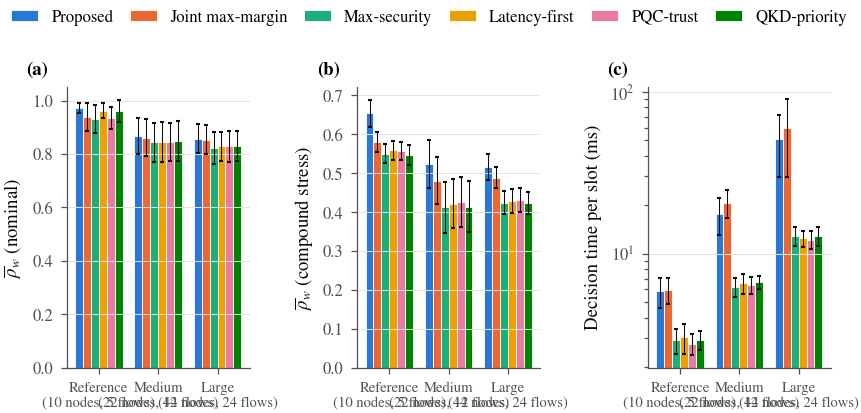

,topology,nodes,edges,flows,mean_candidates,qkd_edge_fraction
0,reference,10.0,18.0,5.0,8.000000,0.888889
1,medium,22.0,54.0,12.0,7.883333,0.870370
2,large,44.0,110.0,24.0,7.433333,0.863636


method                     proposed  milp_max_secure  max_security  \
topology  scenario                                                   
large     compound_stress     0.515            0.488         0.424   
          nominal             0.858            0.853         0.823   
medium    compound_stress     0.523            0.481         0.412   
          nominal             0.868            0.862         0.843   
reference compound_stress     0.654            0.579         0.550   
          nominal             0.972            0.938         0.932   

method                     latency_first  pqc_trust  qkd_priority  
topology  scenario                                                 
large     compound_stress          0.429      0.431         0.424  
          nominal                  0.828      0.828         0.830  
medium    compound_stress          0.421      0.426         0.414  
          nominal                  0.845      0.846         0.849  
reference compound_stress          0.559      0.557         0.547  
          nominal                  0.962      0.934         0.961

method,proposed,milp_max_secure,max_security,latency_first,pqc_trust,qkd_priority
topology,,,,,,
large,46.29,51.69,11.30,11.53,11.52,11.82
medium,17.92,19.61,6.05,6.11,6.03,6.26
reference,5.72,5.94,2.61,3.01,2.90,2.84


[SAVED] Outputs\quantum_secure_comm\tables\scalability_seed_level_metrics.csv
[SAVED] Outputs\quantum_secure_comm\tables\scalability_summary.csv
[SAVED] Outputs\quantum_secure_comm\tables\scalability_topology_statistics.csv
[SAVED] Outputs\quantum_secure_comm\tables\scalability_paired_tests.csv


In [21]:
# -----------------------------
# Scalability across topology sizes
# -----------------------------
scal_seeds = CONFIG["scalability_seeds"]
scal_scenarios = {"nominal": SCENARIOS["nominal"], "compound_stress": SCENARIOS["compound_stress"]}
scal_frames, topo_rows = [], []
for kind in ["reference", "medium", "large"]:
    d_, s_ = run_batch(scal_seeds, scal_scenarios, method_specs_for(METHODS), kind=kind)
    sm = seed_metrics(d_, s_)
    rt = s_.groupby(["method", "scenario", "seed"])["run_time_s"].first().reset_index()
    sm = sm.merge(rt, on=["method", "scenario", "seed"])
    sm["decision_time_per_slot_ms"] = 1000.0 * sm["run_time_s"] / CONFIG["time_horizon"]
    sm["topology"] = kind
    scal_frames.append(sm)
    for seed in scal_seeds:
        b = get_bundle(kind, seed)
        topo_rows.append({
            "topology": kind,
            "seed": seed,
            "nodes": b["G"].number_of_nodes(),
            "edges": b["G"].number_of_edges(),
            "flows": len(b["flows"]),
            "mean_candidates": float(np.mean([len(v) for v in b["candidates"].values()])),
            "qkd_edge_fraction": float(np.mean([b["G"][u][v]["supports_qkd"] for u, v in b["G"].edges()])),
        })

scalability_seed_df = pd.concat(scal_frames, ignore_index=True)
scalability_summary = summarize_with_ci(
    scalability_seed_df, ["topology", "scenario", "method"],
    ["weighted_secure_ratio", "SCI", "deficit", "energy_per_secure_unit", "decision_time_per_slot_ms"],
)
topology_stats = pd.DataFrame(topo_rows).groupby("topology").mean(numeric_only=True).drop(columns=["seed"]).reindex(["reference", "medium", "large"]).reset_index()
scalability_paired = paired_tests(scalability_seed_df.assign(scenario=scalability_seed_df["topology"] + "|" + scalability_seed_df["scenario"]),
                                  "proposed", BASELINES, ["weighted_secure_ratio", "SCI"], group_cols=("scenario",))

scalability_seed_df.to_csv(TAB_DIR / "scalability_seed_level_metrics.csv", index=False)
scalability_summary.to_csv(TAB_DIR / "scalability_summary.csv", index=False)
topology_stats.to_csv(TAB_DIR / "scalability_topology_statistics.csv", index=False)
scalability_paired.to_csv(TAB_DIR / "scalability_paired_tests.csv", index=False)

# -----------------------------
# Figure 37 — Scalability
# -----------------------------
topo_order = ["reference", "medium", "large"]
ts_idx = topology_stats.set_index("topology")
topo_ticks = [f"{t.capitalize()}\n({int(ts_idx.loc[t, 'nodes'])} nodes, {int(ts_idx.loc[t, 'flows'])} flows)" for t in topo_order]
fig, axes = plt.subplots(1, 3, figsize=(FULL_W, 2.6))
for ax, (metric, ylabel, sc), L in zip(axes, [("weighted_secure_ratio", r"$\overline{\rho}_w$ (nominal)", "nominal"),
                                               ("weighted_secure_ratio", r"$\overline{\rho}_w$ (compound stress)", "compound_stress"),
                                               ("decision_time_per_slot_ms", "Decision time per slot (ms)", "nominal")], "abc"):
    x = np.arange(len(topo_order))
    width = 0.8 / len(method_order)
    for i, m in enumerate(method_order):
        sub = scalability_summary[(scalability_summary["scenario"] == sc) & (scalability_summary["method"] == m)].set_index("topology").reindex(topo_order)
        ax.bar(x + (i - (len(method_order) - 1) / 2) * width, sub[metric], width,
               yerr=np.vstack([sub[metric] - sub[f"{metric}_ci_low"], sub[f"{metric}_ci_high"] - sub[metric]]),
               color=METHOD_COLORS[m], edgecolor="white", linewidth=0.4,
               error_kw={"elinewidth": 0.5, "capsize": 1.0, "ecolor": INK}, label=METHOD_LABELS[m])
    ax.set_xticks(x)
    ax.set_xticklabels(topo_ticks, fontsize=7)
    ax.set_ylabel(ylabel)
    if metric == "decision_time_per_slot_ms":
        ax.set_yscale("log")
    panel_label(ax, L, x=-0.22)
method_legend(fig, axes[0], ncol=6, y=1.07)
fig.tight_layout(w_pad=1.0)
save_figure(fig, "fig37_scalability")

display(topology_stats)
display(scalability_summary.pivot_table(index=["topology", "scenario"], columns="method", values="weighted_secure_ratio").reindex(columns=METHODS).round(3))
display(scalability_summary.pivot_table(index=["topology"], columns="method", values="decision_time_per_slot_ms").reindex(columns=METHODS).round(2))
for name in ["scalability_seed_level_metrics", "scalability_summary", "scalability_topology_statistics", "scalability_paired_tests"]:
    print(f"[SAVED] {TAB_DIR / (name + '.csv')}")

## Cell 22 — Final results summary and export

This cell assembles the final summary from all experiments. It covers the nominal comparison, scenario results, stress sweeps, sensitivity, ablation, prediction, energy tradeoff, and scalability, together with key findings and an inventory of all exported tables and figures.

In [23]:
# -----------------------------
# Final results summary
# -----------------------------
def ci_str(row, col, digits=4):
    return f"{row[col]:.{digits}f} [{row[col + '_ci_low']:.{digits}f}, {row[col + '_ci_high']:.{digits}f}]"

R = []
R.append("Quantum-Secure 6G STIN - Results Summary")
R.append("=" * 78)
R.append("")

R.append("1. Experiment overview")
R.append(f"- Reference topology: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, {len(flows)} flows, {T} time steps")
R.append(f"- Evaluation seeds: {len(eval_seeds)}; calibration seeds: {len(CONFIG['calibration_seeds'])}; sweep seeds: {len(sweep_seeds)}")
R.append(f"- Methods: {', '.join(METHODS)}")
R.append(f"- Named scenarios: {', '.join(SCENARIOS.keys())}")
R.append(f"- Stress sweeps: {', '.join(STRESS_SWEEPS.keys())}")
R.append(f"- Regime thresholds (risk-calibrated): secure SCI >= {REGIME_THRESHOLDS['secure']:.4f}, sparse SCI < {REGIME_THRESHOLDS['sparse']:.4f}")
R.append("")

R.append("2. Nominal comparison (mean [95% CI] over seeds)")
for _, row in method_summary.iterrows():
    R.append(
        f"- {row['method']}: weighted_secure_ratio={ci_str(row, 'weighted_secure_ratio')}, "
        f"allocated_ratio={ci_str(row, 'allocated_ratio')}, SCI={ci_str(row, 'SCI')}, deficit={ci_str(row, 'deficit')}, "
        f"latency={ci_str(row, 'mean_latency', 2)} ms, energy_per_secure_unit={ci_str(row, 'energy_per_secure_unit')}, "
        f"q_share={row['q_share']:.3f}, key_reserve={row['key_reserve']:.3f}"
    )
R.append("")

R.append("3. Scenario-level results (weighted secure ratio, mean [95% CI])")
for sc in scenario_order:
    R.append(f"- Scenario: {sc}")
    sub = scenario_method_summary[scenario_method_summary["scenario"] == sc].set_index("method").reindex(METHODS)
    for m, row in sub.iterrows():
        R.append(f"    * {m}: {ci_str(row, 'weighted_secure_ratio')}, SCI={row['SCI']:.4f}, deficit={row['deficit']:.4f}, energy/secure={row['energy_per_secure_unit']:.4f}")
R.append("")

R.append("4. Proposed vs baselines by scenario (weighted secure ratio difference, Wilcoxon p)")
for sc in scenario_order:
    sub = scenario_paired[(scenario_paired["scenario"] == sc) & (scenario_paired["metric"] == "weighted_secure_ratio")]
    R.append(f"- Scenario: {sc}")
    for _, row in sub.iterrows():
        R.append(f"    * vs {row['baseline']}: {fmt_test(row)}")
R.append("")

R.append("5. Stress sweeps (weighted secure ratio of proposed and best baseline at the most severe level)")
for dim, spec in STRESS_SWEEPS.items():
    sev = spec["levels"][-1]
    sub = stress_sweep_summary[(stress_sweep_summary["dimension"] == dim) & np.isclose(stress_sweep_summary["level"], sev)].set_index("method")
    best_base = sub.loc[BASELINES, "weighted_secure_ratio"].idxmax()
    R.append(f"- {dim} at {sev}: proposed={sub.loc['proposed', 'weighted_secure_ratio']:.4f}, best baseline {best_base}={sub.loc[best_base, 'weighted_secure_ratio']:.4f}")
R.append("")

R.append("6. Sensitivity (moderate stress; range of weighted secure ratio and maximum decision change)")
for _, row in sensitivity_range.iterrows():
    R.append(f"- {row['parameter']} ({row['group']}): secure ratio {row['secure_ratio_min']:.4f}-{row['secure_ratio_max']:.4f}, max decision change {row['max_decision_change']:.3f}")
R.append("")

R.append("7. Ablation (full model minus variant, weighted secure ratio)")
for sc in ABLATION_SCENARIOS:
    sub = ablation_paired[(ablation_paired["scenario"] == sc) & (ablation_paired["metric"] == "weighted_secure_ratio")]
    R.append(f"- Scenario: {sc}")
    for _, row in sub.iterrows():
        R.append(f"    * without {row['baseline']}: {fmt_test(row)}")
R.append("")

R.append("8. Prediction of secure-service failure at t + k (held-out seeds, ROC-AUC)")
pv_auc = prediction_df.pivot_table(index="predictor", columns="horizon", values="roc_auc").reindex(PREDICTOR_ORDER)
for name, row in pv_auc.iterrows():
    R.append(f"- {name}: " + ", ".join(f"k={k}: {row[k]:.3f}" for k in horizons))
for _, row in lead_time_df.iterrows():
    R.append(f"- Alarm '{row['alarm_rule']}': detection_rate={row['detection_rate']:.3f}, mean_lead={row['mean_lead_time']:.2f} steps, false_alarm_fraction={row['false_alarm_fraction']:.3f}")
R.append("")

R.append("9. Energy-security tradeoff (proposed, lambda_E sweep)")
for _, row in energy_tradeoff.iterrows():
    R.append(f"- {row['scenario']}, lambda_E={row['lambda_E']:g}: weighted_secure_ratio={row['weighted_secure_ratio']:.4f}, energy_per_secure_unit={row['energy_per_secure_unit']:.4f}")
R.append("")

R.append("10. Scalability")
for _, row in topology_stats.iterrows():
    R.append(f"- {row['topology']}: nodes={row['nodes']:.0f}, edges={row['edges']:.1f}, flows={row['flows']:.0f}")
for _, row in scalability_summary[scalability_summary["method"] == "proposed"].iterrows():
    R.append(f"    * proposed, {row['topology']}, {row['scenario']}: weighted_secure_ratio={row['weighted_secure_ratio']:.4f}, decision_time_per_slot={row['decision_time_per_slot_ms']:.1f} ms")
R.append("")

# -----------------------------
# Key findings
# -----------------------------
key_findings = []
nom = paired_nominal[paired_nominal["metric"] == "weighted_secure_ratio"].set_index("baseline")
sig_better = [b for b in BASELINES if nom.loc[b, "mean_difference"] > 0 and nom.loc[b, "wilcoxon_p"] < 0.05]
key_findings.append(
    f"Nominal: proposed is significantly better than {len(sig_better)}/{len(BASELINES)} baselines in weighted secure ratio "
    f"(p<0.05): {', '.join(sig_better) if sig_better else 'none'}."
)
for sc in scenario_order:
    sub = scenario_paired[(scenario_paired["scenario"] == sc) & (scenario_paired["metric"] == "weighted_secure_ratio")].set_index("baseline")
    better = [b for b in BASELINES if sub.loc[b, "mean_difference"] > 0 and sub.loc[b, "wilcoxon_p"] < 0.05]
    worse = [b for b in BASELINES if sub.loc[b, "mean_difference"] < 0 and sub.loc[b, "wilcoxon_p"] < 0.05]
    key_findings.append(f"{sc}: significantly better than {better if better else 'none'}; significantly worse than {worse if worse else 'none'}.")
best_k1 = pv_auc[1].idxmax()
key_findings.append(
    f"Prediction: best one-step predictor is {best_k1} (AUC={pv_auc.loc[best_k1, 1]:.3f}); SCI alone AUC={pv_auc.loc['SCI', 1]:.3f} at k=1 "
    f"and {pv_auc.loc['SCI', max(horizons)]:.3f} at k={max(horizons)}; persistence AUC={pv_auc.loc['persistence', 1]:.3f} at k=1."
)
helpful = ablation_paired[(ablation_paired["metric"] == "weighted_secure_ratio") & (ablation_paired["mean_difference"] > 0) & (ablation_paired["wilcoxon_p"] < 0.05)]
key_findings.append(
    "Ablation: components with a significant positive contribution in at least one scenario: "
    + (", ".join(sorted(helpful["baseline"].unique())) if len(helpful) else "none") + "."
)
neutral = sorted(set(ABLATION_LABELS[1:]) - set(helpful["baseline"].unique()))
key_findings.append("Ablation: components without a significant contribution in any scenario: " + (", ".join(neutral) if neutral else "none") + ".")
e0 = energy_tradeoff[(energy_tradeoff["scenario"] == "nominal") & (energy_tradeoff["lambda_E"] == 0.0)].iloc[0]
eD = energy_tradeoff[(energy_tradeoff["scenario"] == "nominal") & np.isclose(energy_tradeoff["lambda_E"], CONFIG["stress_weights"]["lambda_E"])].iloc[0]
key_findings.append(
    f"Energy: at the default lambda_E the energy per secure unit is {eD['energy_per_secure_unit']:.4f} versus {e0['energy_per_secure_unit']:.4f} "
    f"without the energy term, with weighted secure ratio {eD['weighted_secure_ratio']:.4f} versus {e0['weighted_secure_ratio']:.4f}."
)

R.append("11. Key findings")
for c in key_findings:
    R.append(f"- {c}")
R.append("")

R.append("12. Export inventory")
R.append("Tables:")
for fname in sorted(os.listdir(TAB_DIR)):
    R.append(f"- {fname}")
R.append("")
R.append("Figures:")
for fname in sorted(os.listdir(FIG_DIR)):
    R.append(f"- {fname}")
R.append("")
R.append(f"Total notebook runtime: {(time.time() - NOTEBOOK_START) / 60.0:.1f} min")

FINAL_REPORT_PATH = OTH_DIR / "final_results_summary.txt"
FINDINGS_PATH = OTH_DIR / "key_findings.txt"
FINAL_REPORT_PATH.write_text("\n".join(R), encoding="utf-8")
FINDINGS_PATH.write_text("\n".join(key_findings), encoding="utf-8")

print(FINAL_REPORT_PATH.read_text(encoding="utf-8"))
print(f"[SAVED] {FINAL_REPORT_PATH}")
print(f"[SAVED] {FINDINGS_PATH}")

Quantum-Secure 6G STIN - Results Summary

1. Experiment overview
- Reference topology: 10 nodes, 18 edges, 5 flows, 48 time steps
- Evaluation seeds: 30; calibration seeds: 15; sweep seeds: 20
- Methods: proposed, milp_max_secure, max_security, latency_first, pqc_trust, qkd_priority
- Named scenarios: nominal, satellite_channel_stress, trust_erosion, congestion_heavy, compound_stress
- Stress sweeps: qkd_scarcity, congestion, trust_degradation, link_noise, traffic_load
- Regime thresholds (risk-calibrated): secure SCI >= 0.2126, sparse SCI < -0.1219

2. Nominal comparison (mean [95% CI] over seeds)
- proposed: weighted_secure_ratio=0.9700 [0.9583, 0.9817], allocated_ratio=0.9919 [0.9888, 0.9951], SCI=0.2861 [0.2779, 0.2943], deficit=0.0157 [0.0106, 0.0209], latency=27.59 [26.58, 28.61] ms, energy_per_secure_unit=1.2886 [1.2439, 1.3333], q_share=0.982, key_reserve=0.934
- milp_max_secure: weighted_secure_ratio=0.9377 [0.9086, 0.9668], allocated_ratio=0.9919 [0.9888, 0.9951], SCI=0.2915 